# 0. les biblios

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Charger environmental_monthly.csv

In [2]:
# Charger les données
df = pd.read_csv("environmental_monthly.csv")

In [3]:
# 1. Dimensions et types de colonnes
print("Dimensions :", df.shape)
print("\nTypes de colonnes :")
df.info()

Dimensions : (4994, 11)

Types de colonnes :
<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   site_code                  4994 non-null   str    
 1   reporting_month            4994 non-null   str    
 2   mean_temperature_c         4994 non-null   str    
 3   rainfall_mm                4994 non-null   str    
 4   mean_humidity_pct          4994 non-null   str    
 5   vegetation_cover_pct       4984 non-null   float64
 6   habitat_disturbance_index  4994 non-null   float64
 7   pesticide_index            4979 non-null   float64
 8   land_use_category          4994 non-null   str    
 9   weather_exception_code     204 non-null    str    
 10  data_completeness_pct      4994 non-null   float64
dtypes: float64(4), str(7)
memory usage: 429.3 KB


In [4]:
# 2. Échantillon des données
print("\nPremières lignes :")
display(df.head())


Premières lignes :


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
0,KNT-KES,2019-01-01,25.25,95.0,74.4,69.7,25.9,31.6,karst_habitat,NaN,98.6
1,KNT-KES,2019-02-01,25.72,78.5,67.3,64.1,23.5,19.4,karst_habitat,NaN,90.4
2,KNT-KES,2019-03-01,25.8,100.4,67.0,62.8,24.6,18.0,karst_habitat,NaN,100.0
3,KNT-KES,2019-04-01,26.68,189.2,68.8,68.5,19.0,21.7,karst_habitat,NaN,96.0
4,KNT-KES,2019-05-01,26.87,198.9,75.9,74.3,21.1,17.1,karst_habitat,NaN,93.9


- 4994 lignes et 11 colonnes.
- Une ligne = un relevé environnemental mensuel pour un site (`site_code` + `reporting_month`).
- Presque toutes les colonnes sont en `object` alors qu'elles devraient être numériques ou date : c'est déjà le signe de formats incohérents.

# 2. Doublons

### a- Doublons de lignes

In [5]:
print("Nombre de lignes strictement dupliquées :", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values(['site_code', 'reporting_month']))

Nombre de lignes strictement dupliquées : 2


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
3489,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
4993,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
3490,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1
4992,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1


### b- Doublons sur la clé métier (site_code + reporting_month)

Le vrai identifiant de ce jeu de données n'est pas une colonne unique : c'est le couple **(site, mois)**.
Un même site ne peut pas avoir deux relevés pour le même mois.

In [6]:
cle = ['site_code', 'reporting_month']
print("Couples (site_code, reporting_month) dupliqués :", df.duplicated(subset=cle).sum())
display(df[df.duplicated(subset=cle, keep=False)].sort_values(cle))

Couples (site_code, reporting_month) dupliqués : 2


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
3489,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
4993,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
3490,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1
4992,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1


- Solution

In [7]:
# On supprime les doublons stricts puis les doublons de clé métier (on garde la 1ère occurrence)
df = df.drop_duplicates(keep='first')
df = df.drop_duplicates(subset=cle, keep='first')

# Vérification
print("Nombre de lignes après suppression :", df.shape[0])
print("Doublons stricts restants :", df.duplicated().sum())
print("Doublons de clé restants :", df.duplicated(subset=cle).sum())

Nombre de lignes après suppression : 4992
Doublons stricts restants : 0
Doublons de clé restants : 0


### c- Doublons de colonnes

In [8]:
# 1. Vérifier si des noms de colonnes sont strictement identiques
noms_doublons = df.columns[df.columns.duplicated()]
print("Noms de colonnes en double :", noms_doublons.tolist())

# 2. Vérifier si le contenu de certaines colonnes est 100% identique
contenu_doublons = df.columns[df.T.duplicated()]
print("Colonnes avec un contenu dupliqué :", contenu_doublons.tolist())

Noms de colonnes en double : []
Colonnes avec un contenu dupliqué : []


- Aucune colonne redondante au sens strict.
- On vérifiera plus bas la redondance *fonctionnelle* (ex : `site_code` → `land_use_category`) et la colinéarité via la matrice de corrélation.

# 3. Formats incohérents

### Les types de chaque colonne :

In [9]:
print(df.dtypes)

site_code                        str
reporting_month                  str
mean_temperature_c               str
rainfall_mm                      str
mean_humidity_pct                str
vegetation_cover_pct         float64
habitat_disturbance_index    float64
pesticide_index              float64
land_use_category                str
weather_exception_code           str
data_completeness_pct        float64
dtype: object


### - Vérifier le format de site_code (catégorielle)

In [10]:
print("Valeurs uniques :", df['site_code'].nunique())
print("Formats structurels :", df['site_code'].str.replace(r'[A-Z0-9]+', 'X', regex=True).unique())
print(df['site_code'].str.extract(r'^([A-Z]+)-')[0].value_counts())
print("Manquants :", df['site_code'].isna().sum())

Valeurs uniques : 64
Formats structurels : <StringArray>
['X-X']
Length: 1, dtype: str
0
KNT    1716
AVL    1716
TMB    1560
Name: count, dtype: int64
Manquants : 0


→ Format homogène `XXX-XXX` (64 sites répartis sur 3 régions : AVL, KNT, TMB). Rien à corriger.

### - Vérifier le format de reporting_month (date) <--->

In [11]:
# On remplace tous les chiffres par 9 pour voir les "patrons" de format présents
print("Formats bruts rencontrés :", df['reporting_month'].str.replace(r'\d', '9', regex=True).unique())

dates = pd.to_datetime(df['reporting_month'], errors='coerce')
print("Valeurs non convertibles :", dates.isna().sum() - df['reporting_month'].isna().sum())

Formats bruts rencontrés : <StringArray>
['9999-99-99']
Length: 1, dtype: str
Valeurs non convertibles : 0


- Solution

In [12]:
# Conversion en vrai type datetime (format ISO homogène ici)
df['reporting_month'] = pd.to_datetime(df['reporting_month'], format='mixed', errors='coerce')

# Vérification
print("Type de la colonne :", df['reporting_month'].dtype)
print("Dates non convertibles :", df['reporting_month'].isna().sum())
print("Période couverte :", df['reporting_month'].min(), "->", df['reporting_month'].max())
print("Nombre de mois par site :")
print(df.groupby('site_code').size().value_counts())

Type de la colonne : datetime64[us]
Dates non convertibles : 0
Période couverte : 2019-01-01 00:00:00 -> 2025-06-01 00:00:00
Nombre de mois par site :
78    64
Name: count, dtype: int64


### - Vérifier le format des colonnes numériques <--->

In [13]:
cols_num = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct',
            'vegetation_cover_pct', 'habitat_disturbance_index',
            'pesticide_index', 'data_completeness_pct']

for col in cols_num:
    s = df[col]
    non_num = s[pd.to_numeric(s, errors='coerce').isna() & s.notna()]
    print(col, "| non convertibles :", len(non_num), "| exemples :", non_num.unique()[:8])

mean_temperature_c | non convertibles : 40 | exemples : <StringArray>
['23,81', '26,34', '29,35', '26,63', '24,65', '26,56', '25.86 C', '23.3 C']
Length: 8, dtype: str
rainfall_mm | non convertibles : 50 | exemples : <StringArray>
['102.7 mm',     '75,5', '251.3 mm',  '67.9 mm',  '29.5 mm',  '91.9 mm',
 '210.9 mm', '216.7 mm']
Length: 8, dtype: str
mean_humidity_pct | non convertibles : 10 | exemples : <StringArray>
['74,8', '64,7', '73,5', '83,2', '70,7', '87,4', '68,8', '80,0']
Length: 8, dtype: str
vegetation_cover_pct | non convertibles : 0 | exemples : []
habitat_disturbance_index | non convertibles : 0 | exemples : []
pesticide_index | non convertibles : 0 | exemples : []
data_completeness_pct | non convertibles : 0 | exemples : []


**Constat :** trois problèmes se cumulent sur les mêmes colonnes :
- **séparateur décimal variable** : `23,81` (virgule française) au lieu de `23.81`
- **unité collée à la valeur** : `25.86 C`, `102.7 mm`
- résultat : pandas a typé toute la colonne en texte.

Comme le cours le recommande, on **garde une seule unité par colonne** (déjà indiquée dans le nom : `_c`, `_mm`, `_pct`) et on convertit tout le reste.

- Solution

In [14]:
for col in cols_num:
    df[col] = (df[col].astype(str)
                      .str.replace(r'\s*(mm|C|%)$', '', regex=True)   # on enlève l'unité collée
                      .str.replace(',', '.', regex=False)             # virgule -> point
                      .str.strip()
                      .replace({'nan': np.nan, '': np.nan}))
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Vérification
print(df[cols_num].dtypes)
print("\nValeurs encore non numériques :")
print(df[cols_num].isna().sum())

mean_temperature_c           float64
rainfall_mm                  float64
mean_humidity_pct            float64
vegetation_cover_pct         float64
habitat_disturbance_index    float64
pesticide_index              float64
data_completeness_pct        float64
dtype: object

Valeurs encore non numériques :
mean_temperature_c            0
rainfall_mm                   0
mean_humidity_pct             0
vegetation_cover_pct         10
habitat_disturbance_index     0
pesticide_index              15
data_completeness_pct         0
dtype: int64


### - Vérifier le format de land_use_category (catégorielle) <--->

In [15]:
print(df['land_use_category'].value_counts(dropna=False))
print("Nombre de catégories brutes :", df['land_use_category'].nunique())

land_use_category
mixed_forest         1481
coastal_habitat       780
durian_orchard        777
karst_habitat         697
research_site         467
mixed_agriculture     388
protected_forest      234
degraded_land         153
Karst_Habitat           4
DEGRADED_LAND           2
DURIAN_ORCHARD          2
Degraded_Land           1
KARST_HABITAT           1
Research_Site           1
Durian_Orchard          1
MIXED_AGRICULTURE       1
Mixed_Agriculture       1
Mixed_Forest            1
Name: count, dtype: int64
Nombre de catégories brutes : 18


**Constat :** 18 catégories alors qu'il n'y en a que 8 réellement. Le même objet est écrit de 3 façons :
`karst_habitat`, `Karst_Habitat`, `KARST_HABITAT`.

Bonne pratique du cours : identifier les différents noms d'un même objet → choisir le label le plus adapté → remplacer le reste.
Ici on choisit le format `snake_case` en minuscules (le plus fréquent).

- Solution

In [16]:
df['land_use_category'] = df['land_use_category'].str.strip().str.lower()

# Vérification
print(df['land_use_category'].value_counts())
print("Nombre de catégories après nettoyage :", df['land_use_category'].nunique())

land_use_category
mixed_forest         1482
durian_orchard        780
coastal_habitat       780
karst_habitat         702
research_site         468
mixed_agriculture     390
protected_forest      234
degraded_land         156
Name: count, dtype: int64
Nombre de catégories après nettoyage : 8


In [17]:
# Cohérence : un site doit toujours avoir le même type d'occupation du sol
print("Sites ayant plusieurs land_use_category :",
      (df.groupby('site_code')['land_use_category'].nunique() > 1).sum())

Sites ayant plusieurs land_use_category : 0


→ Chaque site n'a qu'une seule catégorie d'occupation du sol : la correspondance `site_code` → `land_use_category` est parfaite.
On conserve quand même les deux colonnes (identifiant du lieu vs. caractéristique écologique), comme information conceptuellement distincte.

### - Vérifier le format de weather_exception_code (catégorielle)

In [18]:
print(df['weather_exception_code'].value_counts(dropna=False))
print("Manquants :", df['weather_exception_code'].isna().sum())

weather_exception_code
NaN           4788
HEAVY_RAIN     112
DRY_SPELL       92
Name: count, dtype: int64
Manquants : 4788


# 4. Valeurs manquantes

### a. Constat du problème

In [19]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

print("\nPourcentage de manquants par colonne :")
print((df.isna().sum() / len(df) * 100).round(2))

Valeurs manquantes par colonne :
site_code                       0
reporting_month                 0
mean_temperature_c              0
rainfall_mm                     0
mean_humidity_pct               0
vegetation_cover_pct           10
habitat_disturbance_index       0
pesticide_index                15
land_use_category               0
weather_exception_code       4788
data_completeness_pct           0
dtype: int64

Pourcentage de manquants par colonne :
site_code                     0.00
reporting_month               0.00
mean_temperature_c            0.00
rainfall_mm                   0.00
mean_humidity_pct             0.00
vegetation_cover_pct          0.20
habitat_disturbance_index     0.00
pesticide_index               0.30
land_use_category             0.00
weather_exception_code       95.91
data_completeness_pct         0.00
dtype: float64


- `weather_exception_code` : ~96% de manquants
- `pesticide_index` : 15 manquants (0.3%)
- `vegetation_cover_pct` : 10 manquants (0.2%)

Les deux cas n'ont rien à voir et se traitent différemment.

### b. weather_exception_code : l'absence d'information EST une information

Hypothèse : ce n'est pas une donnée perdue, c'est un code d'exception météo qui n'est renseigné que
quand le mois est anormal. Un mois "normal" n'a donc pas de code.

In [20]:
# Vérification de l'hypothèse : comparer la pluviométrie selon le code
print(df.groupby('weather_exception_code')['rainfall_mm'].describe())
print("\nMois sans code :")
print(df[df['weather_exception_code'].isna()]['rainfall_mm'].describe())

                        count        mean        std   min      25%     50%  \
weather_exception_code                                                        
DRY_SPELL                92.0   23.676087   9.640612   5.0   16.475   26.85   
HEAVY_RAIN              112.0  255.493750  56.151818  81.1  218.475  265.70   

                            75%    max  
weather_exception_code                  
DRY_SPELL                32.500   35.0  
HEAVY_RAIN              294.225  366.7  

Mois sans code :
count    4788.000000
mean      160.275167
std        72.138219
min        35.100000
25%        97.300000
50%       155.850000
75%       220.325000
max       384.300000
Name: rainfall_mm, dtype: float64


→ Preuve par les données : `DRY_SPELL` = mois très secs (moyenne ~24 mm), `HEAVY_RAIN` = mois très pluvieux
(moyenne ~255 mm), les lignes sans code = régime normal (~160 mm).

Le vide est donc porteur de sens. Comme le dit le cours, « considérer que l'absence d'information est une
information en soi » : on remplace `NaN` par une vraie modalité `NORMAL` plutôt que de supprimer 96% du jeu.

In [21]:
df['weather_exception_code'] = df['weather_exception_code'].fillna('NORMAL')

# Vérification
print(df['weather_exception_code'].value_counts())
print("Manquants restants :", df['weather_exception_code'].isna().sum())

weather_exception_code
NORMAL        4788
HEAVY_RAIN     112
DRY_SPELL       92
Name: count, dtype: int64
Manquants restants : 0


### c. vegetation_cover_pct et pesticide_index : inférence par série temporelle du site

Hypothèse : ces trous sont isolés (1 ou 2 mois par site). Comme chaque site est suivi mois par mois,
la valeur manquante peut être inférée à partir des mois qui l'encadrent **sur le même site**,
plutôt qu'avec une moyenne globale qui écraserait les différences entre sites.

In [22]:
for col in ['vegetation_cover_pct', 'pesticide_index']:
    trous = df[df[col].isna()]
    print(col, "->", len(trous), "trous répartis sur", trous['site_code'].nunique(), "sites")
    display(trous[['site_code', 'reporting_month', col]].head())

vegetation_cover_pct -> 10 trous répartis sur 10 sites


,site_code,reporting_month,vegetation_cover_pct
863,KNT-NNM,2019-06-01,NaN
1858,KNT-VXR,2024-05-01,NaN
1998,KNT-BME,2023-01-01,NaN
2076,KNT-XAC,2023-01-01,NaN
2342,AVL-GRB,2019-03-01,NaN


pesticide_index -> 15 trous répartis sur 12 sites


,site_code,reporting_month,pesticide_index
731,KNT-YRX,2021-06-01,NaN
1437,KNT-DMJ,2021-10-01,NaN
1648,KNT-TLQ,2019-11-01,NaN
1649,KNT-TLQ,2019-12-01,NaN
1807,KNT-VXR,2020-02-01,NaN


- Solution

In [23]:
# On trie par site et par mois, puis on interpole à l'intérieur de chaque site
df = df.sort_values(['site_code', 'reporting_month']).reset_index(drop=True)

for col in ['vegetation_cover_pct', 'pesticide_index']:
    df[col] = df.groupby('site_code')[col].transform(
        lambda s: s.interpolate(limit_direction='both')
    )

# Vérification
print("Valeurs manquantes restantes :")
print(df.isna().sum())

Valeurs manquantes restantes :
site_code                    0
reporting_month              0
mean_temperature_c           0
rainfall_mm                  0
mean_humidity_pct            0
vegetation_cover_pct         0
habitat_disturbance_index    0
pesticide_index              0
land_use_category            0
weather_exception_code       0
data_completeness_pct        0
dtype: int64


Solution

On remplace chaque mois manquant en le calculant à partir du mois d'avant et du mois d'après, du même site uniquement (pour ne jamais mélanger les sites entre eux).

Vérification : on recompte les valeurs manquantes, elles doivent toutes être à 0.

# 5. Gestion des variables catégorielles

### a. Création des variables temporelles

La date seule est difficile à exploiter dans un modèle : on en extrait l'année et le mois,
ce qui permettra ensuite d'observer la saisonnalité.

In [24]:
df['year'] = df['reporting_month'].dt.year
df['month'] = df['reporting_month'].dt.month

display(df.head())

,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct,year,month
0,AVL-ABG,2019-01-01,27.28,118.9,69.2,61.1,21.1,39.0,mixed_forest,NORMAL,96.2,2019,1
1,AVL-ABG,2019-02-01,28.78,91.4,67.7,54.9,16.8,42.1,mixed_forest,NORMAL,95.3,2019,2
2,AVL-ABG,2019-03-01,28.70,62.6,73.7,59.2,13.9,37.4,mixed_forest,NORMAL,90.4,2019,3
3,AVL-ABG,2019-04-01,28.64,70.2,68.5,61.8,11.1,32.9,mixed_forest,NORMAL,99.1,2019,4
4,AVL-ABG,2019-05-01,28.66,96.6,71.3,61.6,23.6,38.8,mixed_forest,NORMAL,100.0,2019,5


### b. Variables ordonnées

Aucune variable réellement ordinale ici : `land_use_category` (forêt, verger, karst…) et
`weather_exception_code` (DRY_SPELL / NORMAL / HEAVY_RAIN) n'ont pas de hiérarchie chiffrable
évidente — on les traite donc comme nominales.

Les "notes" (`habitat_disturbance_index`, `pesticide_index`, `data_completeness_pct`) sont déjà
des variables numériques continues, pas des catégories.

### c. Encodage One-Hot des variables nominales

`land_use_category` et `weather_exception_code` sont des variables **nominales** (aucun ordre entre les modalités) : on les encode en One-Hot avec `pd.get_dummies`.

- `drop_first=False` : on garde **toutes** les modalités (One-Hot "pur"), plus lisible pour l'exploration et les corrélations. Pour une régression linéaire il faudrait `drop_first=True` (encodage *dummy*) afin d'éviter la colinéarité parfaite entre les colonnes d'une même variable.
- `dtype=int` : colonnes 0/1 directement exploitables.
- `site_code` n'est **pas** encodée : c'est un identifiant (64 valeurs) et la clé de fusion avec les autres fichiers. L'encoder ajouterait 64 colonnes quasi vides et ferait disparaître la clé. Elle reste en texte.
- `df_stats` reste **non encodé** (c'est lui qui est exporté dans `environmental_monthly_clean.csv`) ; l'encodage est stocké dans un DataFrame séparé `df_encoded`, exporté dans un second fichier.

In [25]:
cols_nominales = ['land_use_category', 'weather_exception_code']

df_stats = df.copy()
df_encoded = pd.get_dummies(df_stats, columns=cols_nominales, drop_first=False, dtype=int)

cols_land_use = [c for c in df_encoded.columns if c.startswith('land_use_category_')]
cols_weather  = [c for c in df_encoded.columns if c.startswith('weather_exception_code_')]

print("Avant :", df_stats.shape, "-> Après :", df_encoded.shape)
print(f"{len(cols_land_use)} colonnes land_use, {len(cols_weather)} weather")
print("Valeurs manquantes :", df_encoded.isna().sum().sum())

# Vérification : une et une seule modalité active par ligne et par variable
for nom, cols in [('land_use', cols_land_use), ('weather', cols_weather)]:
    print(f"{nom} : somme des dummies == 1 sur toutes les lignes ->", bool((df_encoded[cols].sum(axis=1) == 1).all()))

display(df_encoded[cols_land_use + cols_weather].head())

Avant : (4992, 13) -> Après : (4992, 22)
8 colonnes land_use, 3 weather
Valeurs manquantes : 0
land_use : somme des dummies == 1 sur toutes les lignes -> True
weather : somme des dummies == 1 sur toutes les lignes -> True


,land_use_category_coastal_habitat,land_use_category_degraded_land,land_use_category_durian_orchard,land_use_category_karst_habitat,land_use_category_mixed_agriculture,land_use_category_mixed_forest,land_use_category_protected_forest,land_use_category_research_site,weather_exception_code_DRY_SPELL,weather_exception_code_HEAVY_RAIN,weather_exception_code_NORMAL
0,0,0,0,0,0,1,0,0,0,0,1
1,0,0,0,0,0,1,0,0,0,0,1
2,0,0,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,1,0,0,0,0,1
4,0,0,0,0,0,1,0,0,0,0,1


# 6. Voir les outliers (colonnes numériques)

In [26]:
# Tableau statistique pour traquer les valeurs aberrantes
display(df_stats[cols_num].describe().T)

,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,4992.0,26.377073,1.672062,21.3,25.19,26.35,27.6125,32.0
rainfall_mm,4992.0,159.894030,74.901939,5.0,95.70,156.25,221.7000,384.3
mean_humidity_pct,4992.0,75.841847,7.248342,56.7,70.30,75.90,81.5000,96.4
vegetation_cover_pct,4992.0,61.006080,14.001057,15.0,52.70,62.30,70.9000,98.0
habitat_disturbance_index,4992.0,30.364423,16.358109,0.0,17.90,29.40,41.4000,86.8
pesticide_index,4992.0,25.018970,16.271040,0.0,11.60,25.20,37.5000,77.3
data_completeness_pct,4992.0,95.961819,2.817944,85.5,94.00,96.15,98.2000,100.0


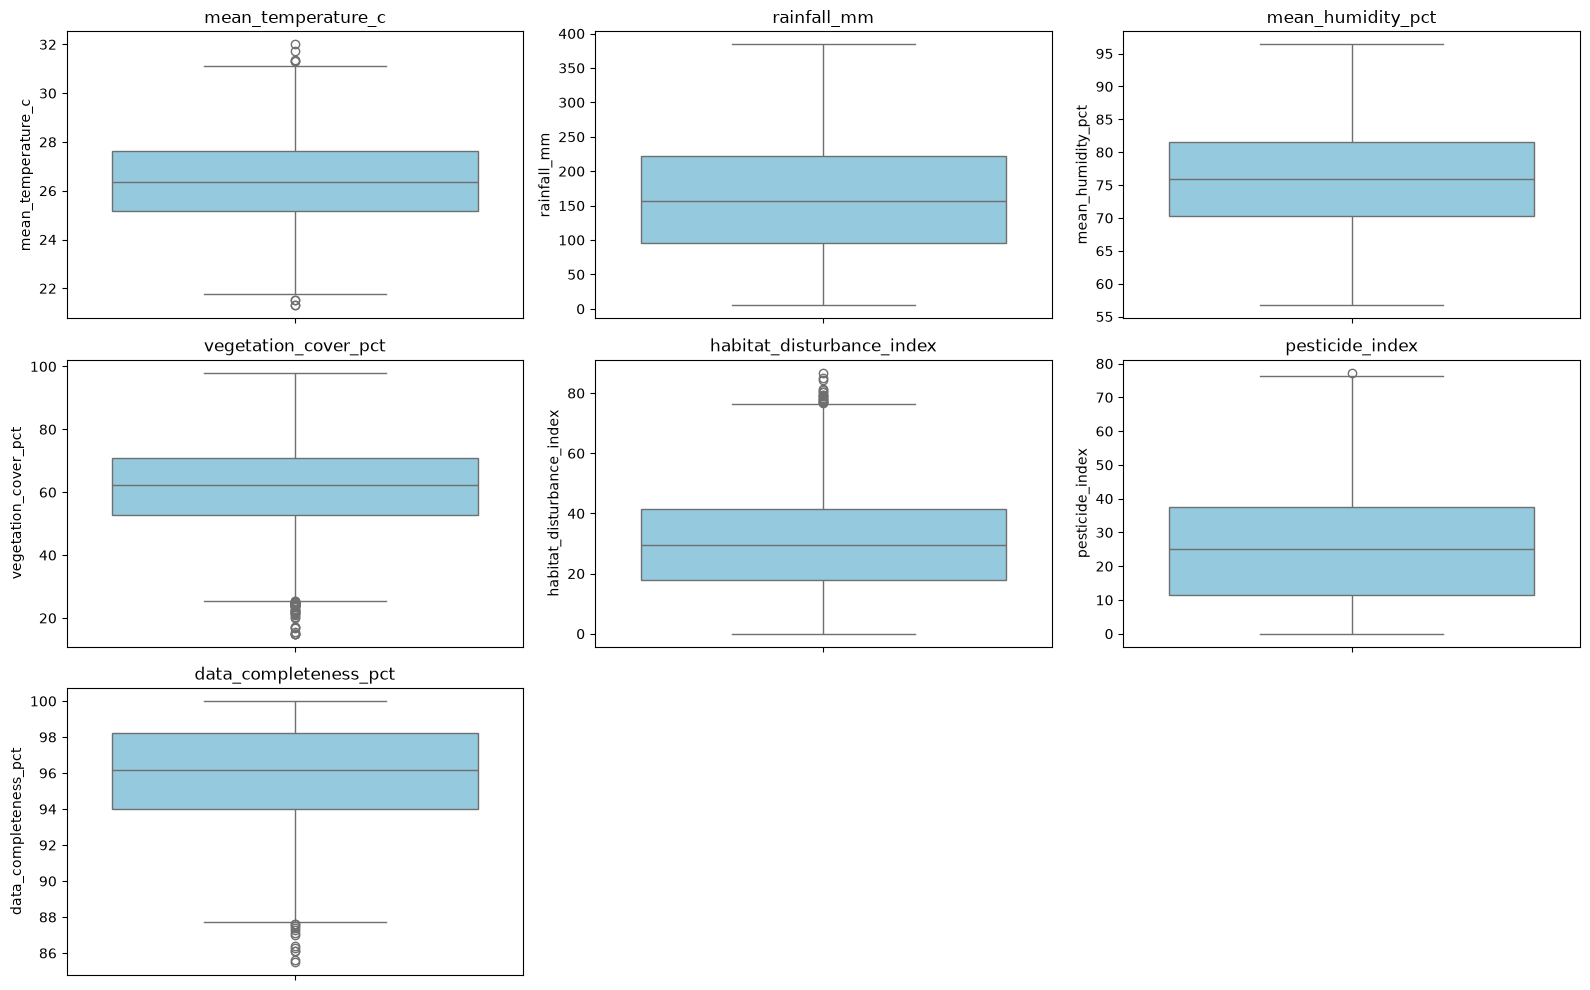

In [27]:
# Configuration de la taille globale de la figure
plt.figure(figsize=(16, 10))

for i, col in enumerate(cols_num, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df_stats[col], color="skyblue")
    plt.title(col)

plt.tight_layout()
plt.show()

Lecture des boxplots

rainfall_mm et mean_humidity_pct : aucun outlier détecté
mean_temperature_c : quelques valeurs extrêmes légères (autour de 22°C et 31-32°C)
vegetation_cover_pct : plusieurs sites avec une couverture végétale très basse (15-25%)
habitat_disturbance_index : plusieurs sites très perturbés (75-90)
pesticide_index : un seul point isolé très élevé (~77)

Vérification du point isolé de pesticide_index

En allant voir la ligne concernée, ce point appartient au site KNT-GKR (février 2024). En regardant l'historique complet de ce site, on constate qu'il oscille déjà régulièrement entre 12 et 77 sur plusieurs années (ex: 76.3 en octobre 2019, 73.2 en février 2020) — ce n'est donc pas une erreur isolée, mais un site naturellement très variable.

Décision : on garde tous les outliers. Aucune valeur n'est physiquement impossible, et elles sont cohérentes avec l'historique de leur site respectif. Ce sont des réalités environnementales, pas des erreurs.

In [28]:
# Comptage des points hors moustaches (règle 1.5 * IQR)
for col in cols_num:
    q1, q3 = df_stats[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_stats[col] < bas) | (df_stats[col] > haut)).sum()
    print(f"{col:28s} min={df_stats[col].min():7.1f} max={df_stats[col].max():7.1f} -> {n} points hors moustaches")

mean_temperature_c           min=   21.3 max=   32.0 -> 9 points hors moustaches
rainfall_mm                  min=    5.0 max=  384.3 -> 0 points hors moustaches
mean_humidity_pct            min=   56.7 max=   96.4 -> 0 points hors moustaches
vegetation_cover_pct         min=   15.0 max=   98.0 -> 46 points hors moustaches
habitat_disturbance_index    min=    0.0 max=   86.8 -> 19 points hors moustaches
pesticide_index              min=    0.0 max=   77.3 -> 1 points hors moustaches
data_completeness_pct        min=   85.5 max=  100.0 -> 13 points hors moustaches


### - Justification du traitement des outliers

- **Contrôle de plausibilité d'abord** : aucune valeur impossible n'a été trouvée (pas de négatif, pas de
code sentinelle type -99 / 999, pourcentages tous entre 0 et 100, températures entre 21 et 32 °C
cohérentes avec un climat tropical). Il n'y a donc pas d'outlier "erreur de saisie" à traiter comme
donnée manquante.

- **Décision** : les points extrêmes (mois très secs ou très pluvieux, sites très dégradés) sont
**conservés**. Ce sont des réalités environnementales, et pour plusieurs d'entre eux le jeu de données
les documente lui-même via `weather_exception_code`. Les supprimer reviendrait à effacer exactement
l'information la plus intéressante de l'étude (cf. cours : un outlier peut être une anomalie
intéressante à repérer).

# 7. Histogrammes et distributions

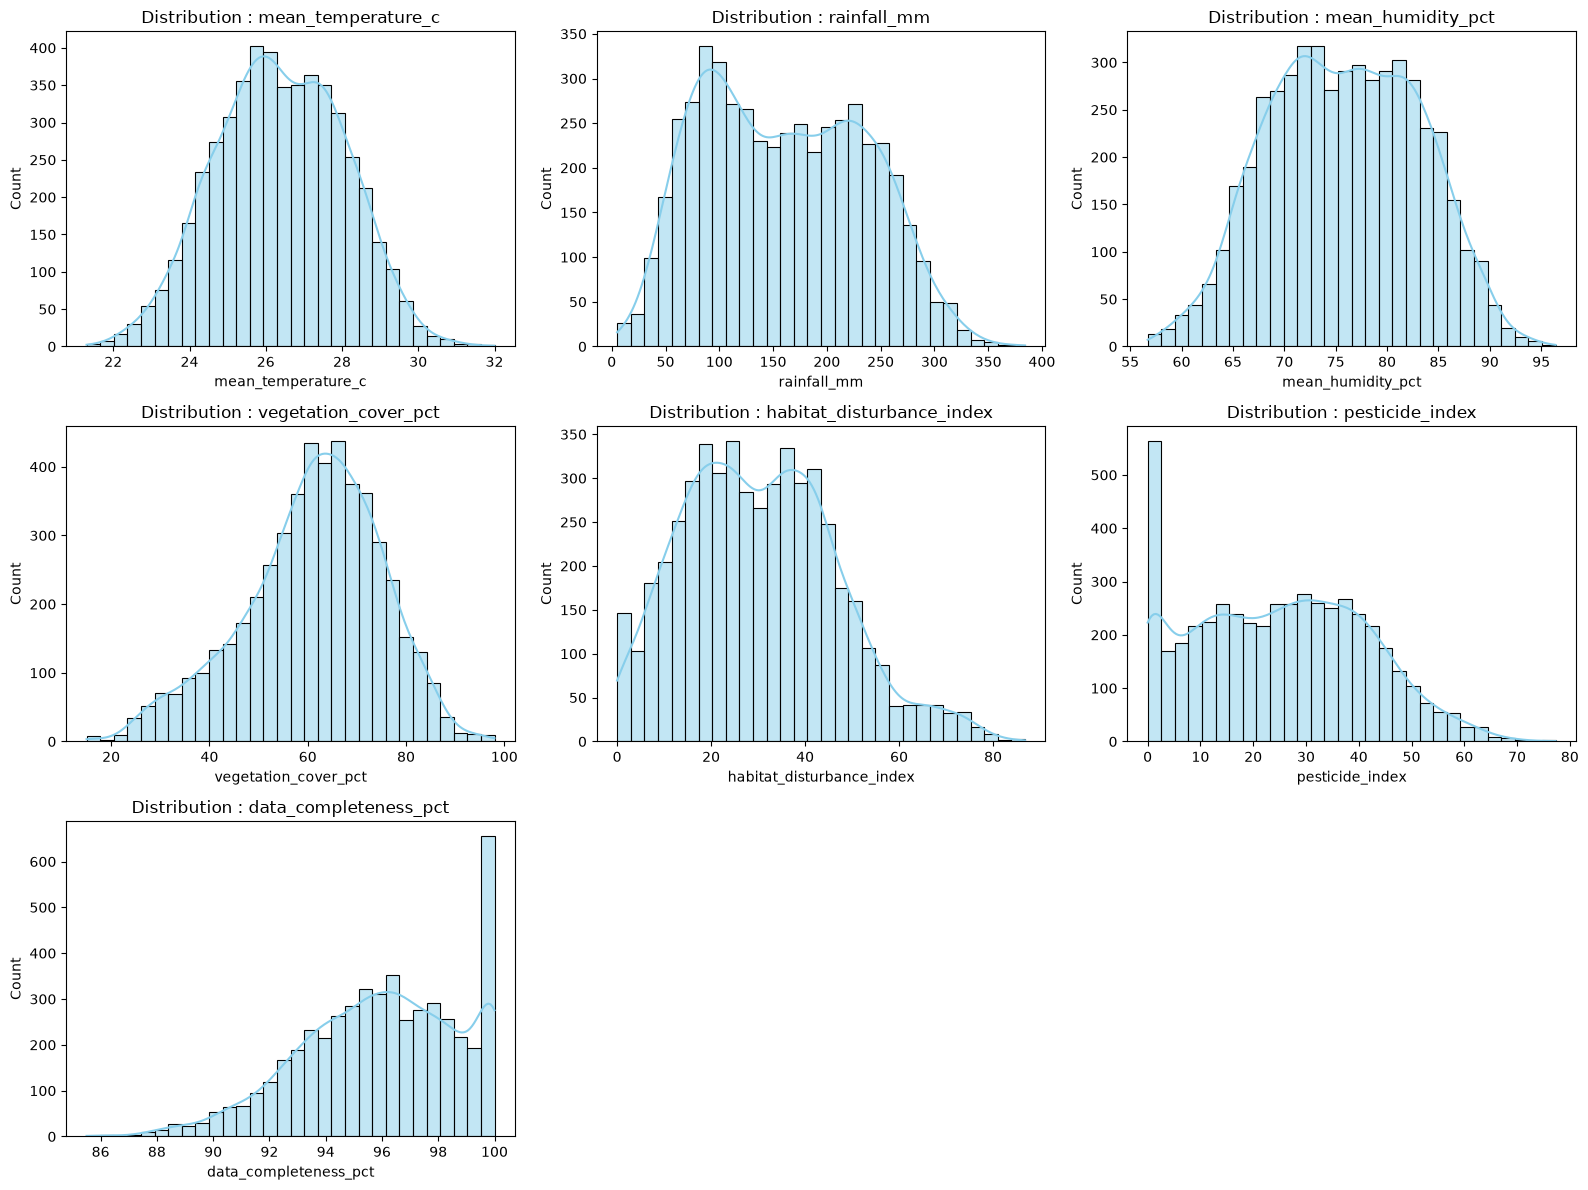

In [29]:
plt.figure(figsize=(16, 12))

for i, col in enumerate(cols_num, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df_stats[col], kde=True, bins=30, color='skyblue')
    plt.title(f"Distribution : {col}")

plt.tight_layout()
plt.show()

In [30]:
# Coefficients d'asymétrie (skewness) pour objectiver la forme des distributions
print(df_stats[cols_num].skew().round(2))

mean_temperature_c          -0.03
rainfall_mm                  0.18
mean_humidity_pct           -0.01
vegetation_cover_pct        -0.45
habitat_disturbance_index    0.40
pesticide_index              0.17
data_completeness_pct       -0.44
dtype: float64


### - Analyse exploratoire : distributions et lois statistiques

- **Proches d'une loi normale** : `mean_temperature_c`, `mean_humidity_pct` et `rainfall_mm` sont à peu près
symétriques autour de leur moyenne (asymétrie faible) — associer moyenne + écart-type a donc du sens.

- **Distributions asymétriques** : `vegetation_cover_pct` et `data_completeness_pct` sont étirées vers la
gauche (la plupart des sites/relevés sont bons, une minorité est très basse), tandis que
`habitat_disturbance_index` est étirée vers la droite (beaucoup de sites peu perturbés, une queue de
sites très dégradés). Pour ces variables, la **médiane + quartiles + min/max** décrit mieux la réalité
que la moyenne seule.

### - Répartition des variables catégorielles

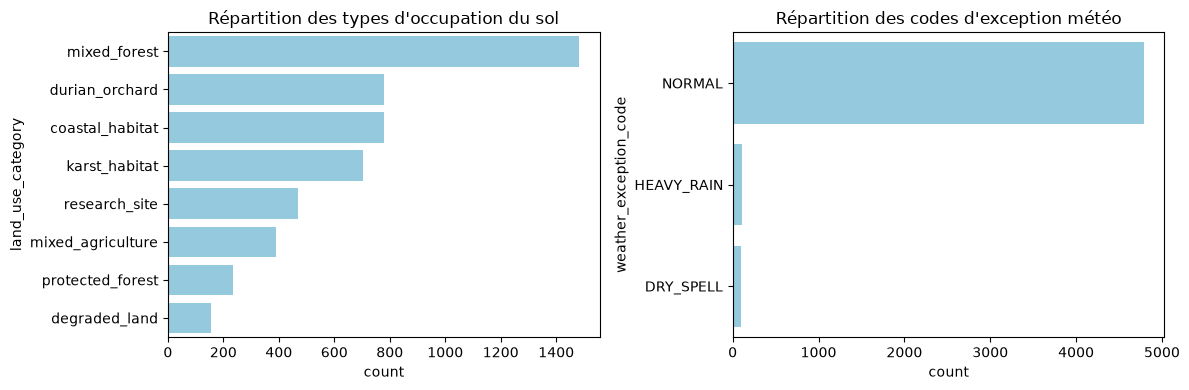

In [31]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(y='land_use_category', data=df_stats,
              order=df_stats['land_use_category'].value_counts().index, color='skyblue')
plt.title("Répartition des types d'occupation du sol")

plt.subplot(1, 2, 2)
sns.countplot(y='weather_exception_code', data=df_stats,
              order=df_stats['weather_exception_code'].value_counts().index, color='skyblue')
plt.title("Répartition des codes d'exception météo")

plt.tight_layout()
plt.show()

### - Saisonnalité (moyenne par mois calendaire)

,mean_temperature_c,rainfall_mm,mean_humidity_pct
month,,,
1,26.3,143.1,74.4
2,27.2,129.5,73.2
3,27.7,127.9,72.1
4,28.0,131.9,73.3
5,27.8,146.6,74.3
6,27.1,163.6,75.8
7,26.3,180.3,77.9
8,25.4,191.9,78.9
9,24.8,195.9,79.3


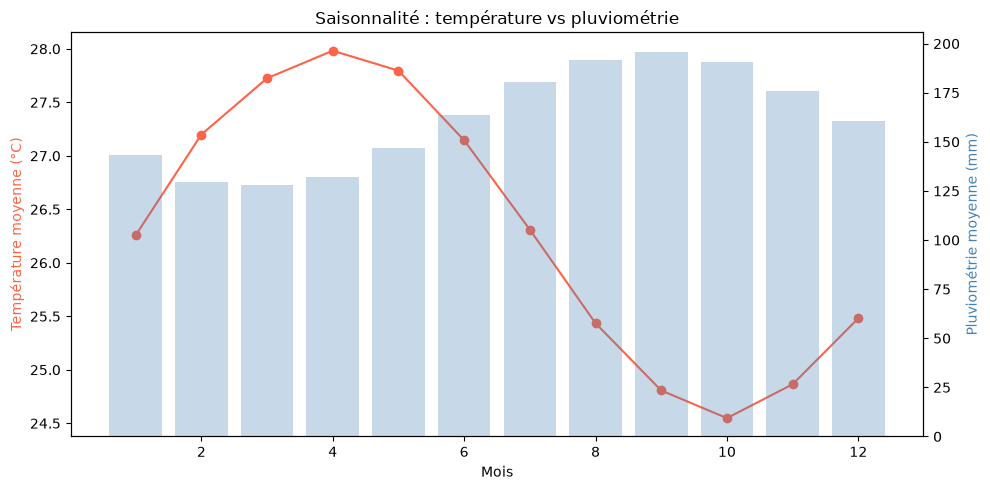

In [32]:
saison = df_stats.groupby('month')[['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct']].mean()
display(saison.round(1))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(saison.index, saison['mean_temperature_c'], marker='o', color='tomato', label='Température (°C)')
ax1.set_xlabel("Mois")
ax1.set_ylabel("Température moyenne (°C)", color='tomato')

ax2 = ax1.twinx()
ax2.bar(saison.index, saison['rainfall_mm'], alpha=0.3, color='steelblue', label='Pluie (mm)')
ax2.set_ylabel("Pluviométrie moyenne (mm)", color='steelblue')

plt.title("Saisonnalité : température vs pluviométrie")
plt.tight_layout()
plt.show()

→ Signal clair de mousson : les mois les plus pluvieux (août–octobre) sont aussi les plus frais,
les mois secs (février–avril) les plus chauds. C'est cohérent avec un climat tropical et confirme que
les données ne sont pas aléatoires.

# 8. Corrélations

### Matrices de corrélation (Pearson + Spearman) sur les variables numériques

In [33]:
# 1. On calcule explicitement les DEUX méthodes distinctes
matrice_spearman = df_stats[cols_num].corr(method='spearman')
matrice_pearson = df_stats[cols_num].corr(method='pearson')

display(matrice_spearman.round(2))

,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
mean_temperature_c,1.00,-0.22,-0.27,-0.06,0.00,-0.08,0.00
rainfall_mm,-0.22,1.00,0.75,0.34,0.01,0.08,-0.00
mean_humidity_pct,-0.27,0.75,1.00,0.27,0.01,-0.01,-0.02
vegetation_cover_pct,-0.06,0.34,0.27,1.00,-0.31,-0.04,0.02
habitat_disturbance_index,0.00,0.01,0.01,-0.31,1.00,0.05,0.00
pesticide_index,-0.08,0.08,-0.01,-0.04,0.05,1.00,0.00
data_completeness_pct,0.00,-0.00,-0.02,0.02,0.00,0.00,1.00


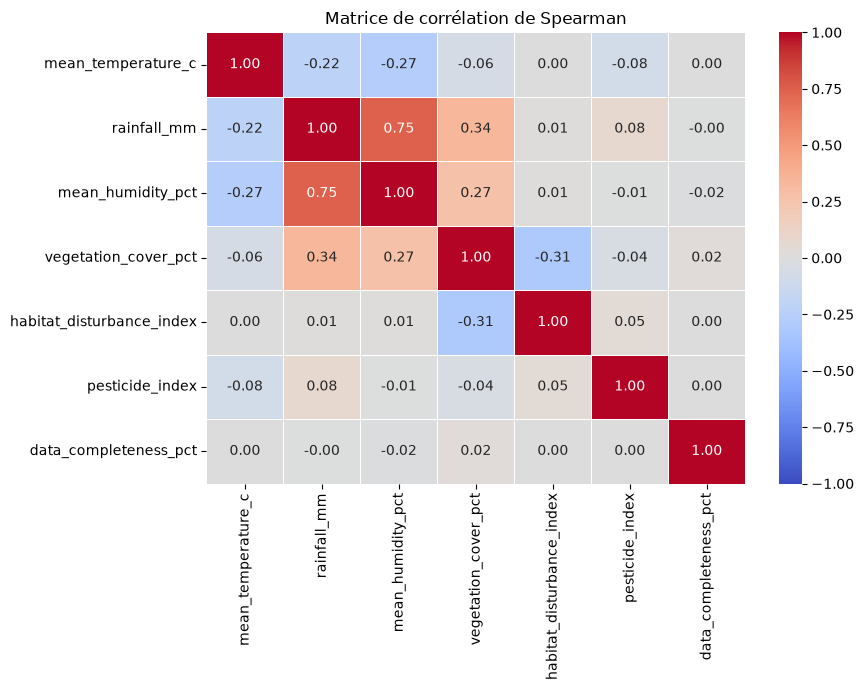

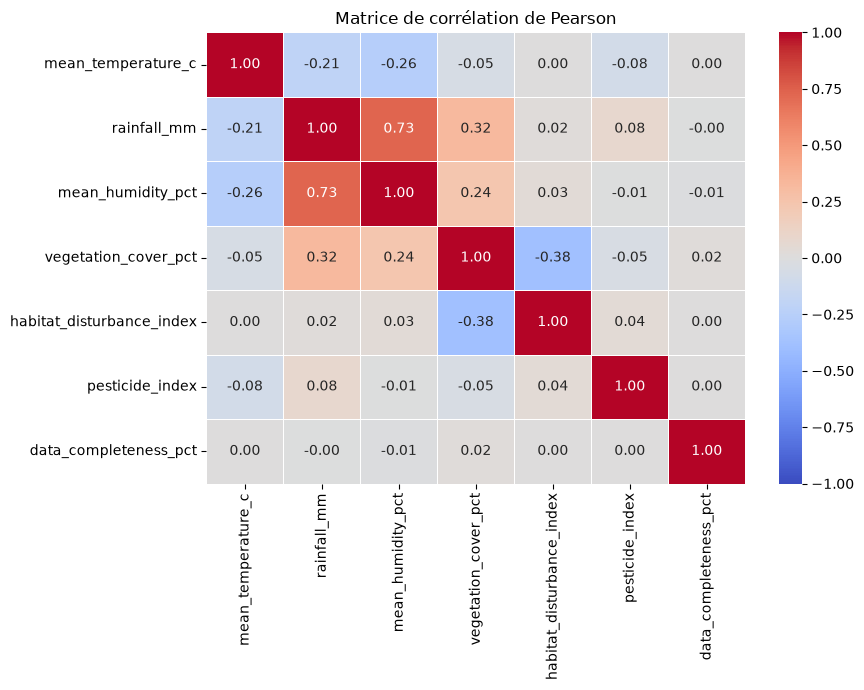

In [34]:
# Affichage de Spearman
plt.figure(figsize=(9, 7))
sns.heatmap(matrice_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation de Spearman")
plt.tight_layout()
plt.show()

# Affichage de Pearson
plt.figure(figsize=(9, 7))
sns.heatmap(matrice_pearson, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

### Nuages de points croisés (Pairplot)

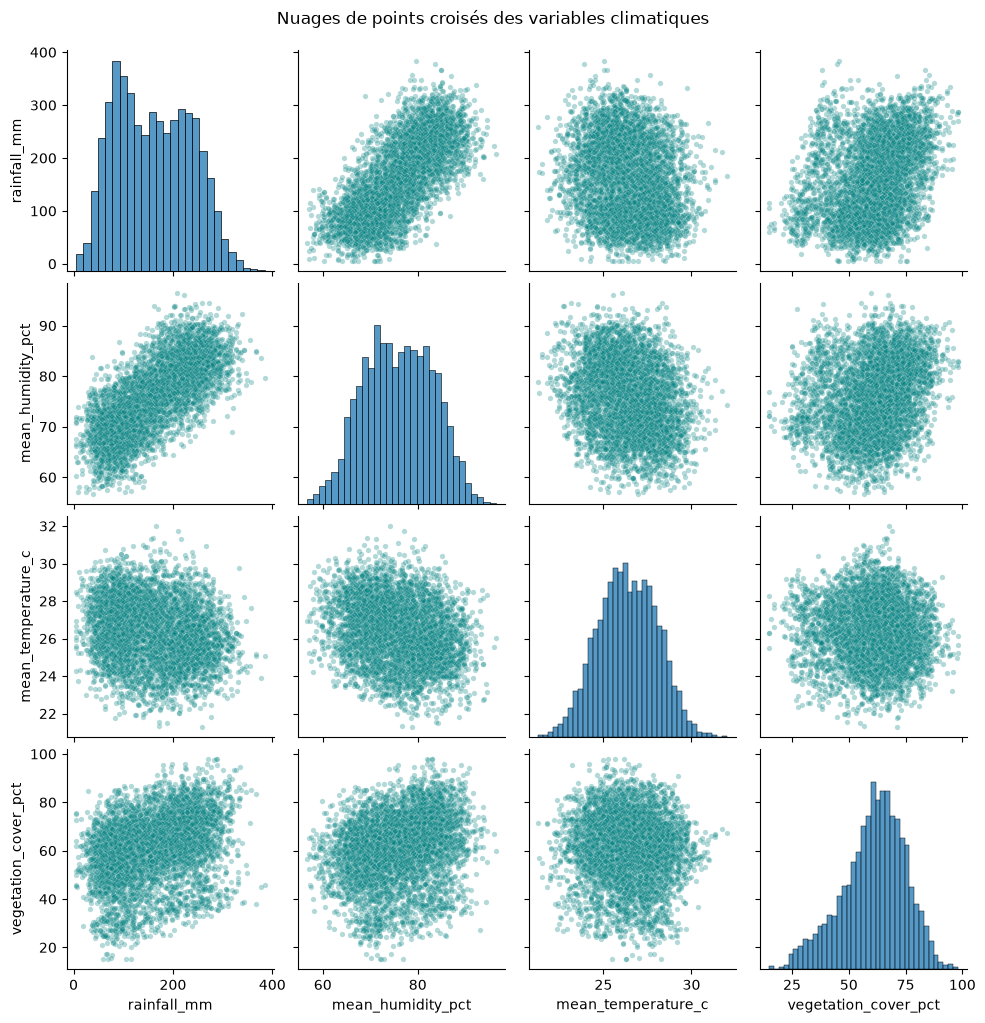

In [35]:
variables_a_croiser = ['rainfall_mm', 'mean_humidity_pct', 'mean_temperature_c', 'vegetation_cover_pct']

sns.pairplot(df_stats[variables_a_croiser], kind='scatter',
             plot_kws={'alpha': 0.3, 'color': 'teal', 's': 15})
plt.suptitle("Nuages de points croisés des variables climatiques", y=1.02)
plt.show()

### - Analyse des corrélations

- **pluie ↔ humidité (≈ 0.75)** : la corrélation la plus forte, relation monotone et quasi linéaire.
Les deux variables mesurent en partie le même phénomène → redondance à garder en tête si on construit
un modèle (colinéarité).
- **température ↔ pluie / humidité (≈ -0.22 / -0.27)** : négatif et modéré, c'est la saisonnalité vue plus haut.
- **couverture végétale ↔ perturbation de l'habitat (≈ -0.31)** : plus un site est perturbé, moins il est végétalisé.
Relation attendue écologiquement, mais **corrélation n'est pas causalité** : les deux peuvent découler
du même facteur (type d'occupation du sol).
- **`pesticide_index` et `data_completeness_pct`** ne sont corrélés à rien : `data_completeness_pct` est une
métadonnée de qualité de collecte, pas une mesure environnementale.
- **Pearson vs Spearman** donnent ici des valeurs très proches : les relations sont plutôt monotones et
linéaires, et il n'y a pas de queue de distribution extrême qui tire les coefficients (contrairement à des
données de comptage).

### Corrélations avec les variables encodées (Spearman)

On croise les variables numériques avec les dummies `land_use_category` et `weather_exception_code`.

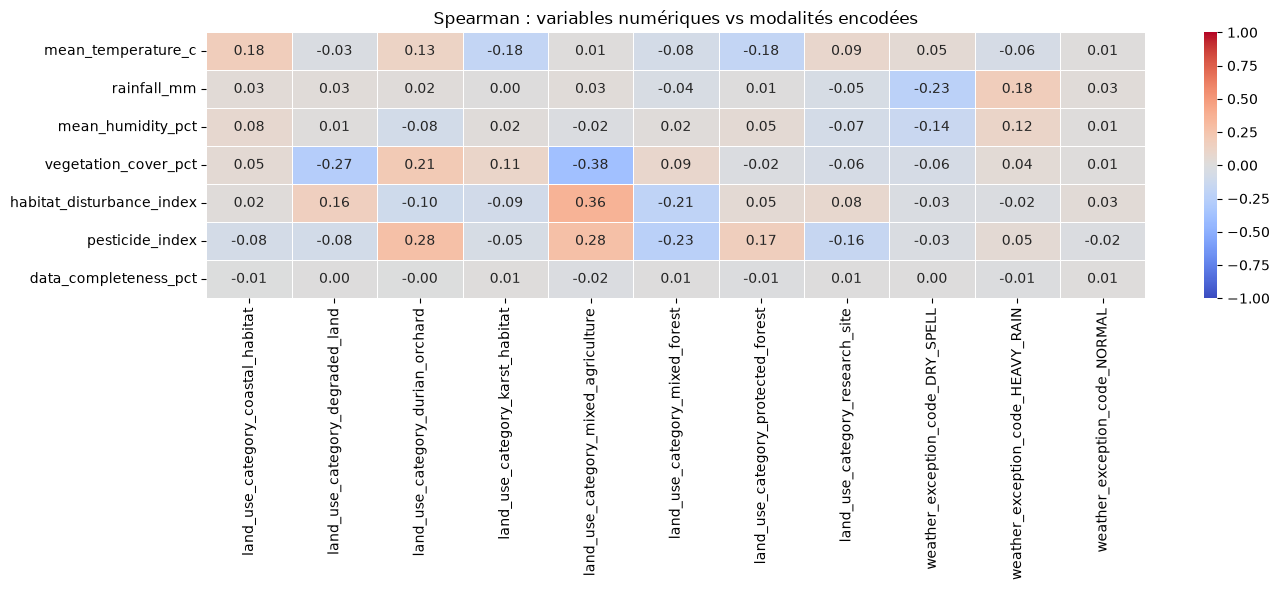

In [36]:
corr_cat = df_encoded[cols_num + cols_land_use + cols_weather].corr(method='spearman').loc[cols_num, cols_land_use + cols_weather]

plt.figure(figsize=(14, 6))
sns.heatmap(corr_cat, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Spearman : variables numériques vs modalités encodées")
plt.tight_layout()
plt.show()

### - Lecture des corrélations avec les catégories

- **`mixed_agriculture`** : le profil le plus marqué : moins de végétation (≈ -0.38), plus de perturbation (≈ +0.36) et plus de pesticides (≈ +0.28). Cohérent avec un usage agricole intensif.
- **`durian_orchard`** : plus de pesticides (≈ +0.28) et plus de végétation (≈ +0.21) : un verger est végétalisé mais traité.
- **`degraded_land`** : moins de végétation (≈ -0.27), plus de perturbation (≈ +0.16).
- **`mixed_forest`** : l'inverse, moins de perturbation (≈ -0.21) et moins de pesticides (≈ -0.23).
- **`DRY_SPELL` / `HEAVY_RAIN`** : liés à la pluie (≈ -0.23 / +0.18) et à l'humidité (≈ -0.14 / +0.12) : le code météo est cohérent avec les mesures. Il n'a aucun lien avec les autres variables.
- `coastal_habitat` (+0.18) et `karst_habitat` / `protected_forest` (≈ -0.18) se distinguent surtout par la température.

Ce sont des corrélations de Spearman avec des variables 0/1 : elles mesurent un écart de profil entre groupes, pas une causalité.

### Tableaux croisés (variables catégorielles)

weather_exception_code,DRY_SPELL,HEAVY_RAIN,NORMAL,All
land_use_category,,,,
coastal_habitat,8,32,740,780
degraded_land,0,3,153,156
durian_orchard,15,12,753,780
karst_habitat,12,10,680,702
mixed_agriculture,3,22,365,390
mixed_forest,34,32,1416,1482
protected_forest,7,0,227,234
research_site,13,1,454,468
All,92,112,4788,4992


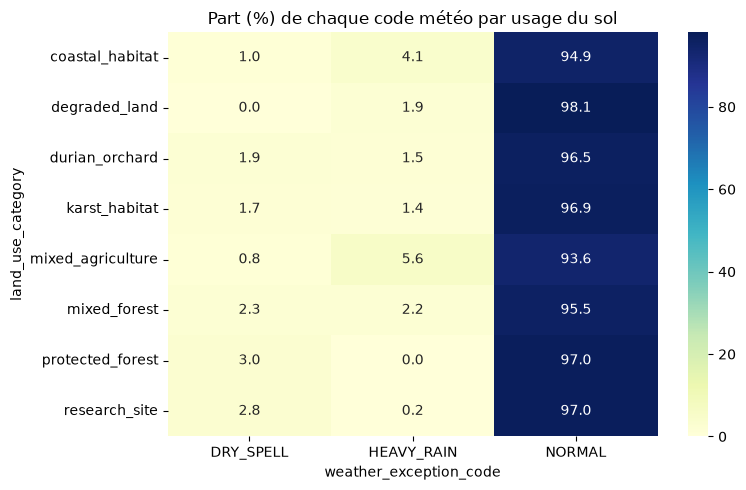

land_use_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site,All
site_code,,,,,,,,,
AVL,0,0,546,0,390,312,0,468,1716
KNT,0,156,0,702,0,624,234,0,1716
TMB,780,0,234,0,0,546,0,0,1560
All,780,156,780,702,390,1482,234,468,4992


In [37]:
# Effectifs : usage du sol x code météo
display(pd.crosstab(df_stats['land_use_category'], df_stats['weather_exception_code'], margins=True))

# Proportions par ligne (en %)
ct_meteo = pd.crosstab(df_stats['land_use_category'], df_stats['weather_exception_code'], normalize='index') * 100
plt.figure(figsize=(8, 5))
sns.heatmap(ct_meteo, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Part (%) de chaque code météo par usage du sol")
plt.tight_layout()
plt.show()

# Région (3 premières lettres du site_code) x usage du sol
region = df_stats['site_code'].str[:3]
display(pd.crosstab(region, df_stats['land_use_category'], margins=True))

### - Lecture des tableaux croisés

- Les codes météo sont rares : 4 788 mois `NORMAL`, 112 `HEAVY_RAIN`, 92 `DRY_SPELL`. `HEAVY_RAIN` touche surtout `mixed_agriculture` (≈ 5.6 %) et `coastal_habitat` (≈ 4.1 %) et jamais `protected_forest` (0 %).
- Région x usage du sol : chaque région n'a que certains usages (KNT : karst, forêts, terres dégradées ; AVL : durian, agriculture, forêt, recherche ; TMB : côtier, durian, forêt). `land_use_category` est donc **fortement redondante avec `site_code`** : un site a un seul usage du sol. À garder en tête avant de les mettre ensemble dans un modèle.

# 9. Export du jeu de données nettoyé

On exporte deux versions, **sans écraser la première** :
- `environmental_monthly_clean.csv` : nettoyée, **non encodée** (`df_stats`) ;
- `environmental_monthly_clean_encoded.csv` : même contenu avec les catégorielles encodées en One-Hot (`df_encoded`).

In [38]:
df_stats.to_csv("cleaned/environmental_monthly_clean.csv", index=False)

print("Dimensions finales :", df_stats.shape)
print("Valeurs manquantes restantes :", df_stats.isna().sum().sum())

Dimensions finales : (4992, 13)
Valeurs manquantes restantes : 0


In [39]:
df_encoded.to_csv("cleaned/environmental_monthly_clean_encoded.csv", index=False)

print("Dimensions du fichier encodé :", df_encoded.shape)
print("Valeurs manquantes restantes :", df_encoded.isna().sum().sum())

Dimensions du fichier encodé : (4992, 22)
Valeurs manquantes restantes : 0


# 10. Feature engineering & recherche du narratif caché

### a. Variables dérivées : région et saison

`region` = 3 premières lettres du `site_code` (KNT, AVL, TMB). `season` est construite comme dans `bat_surveys.ipynb` à partir du mois, pour pouvoir croiser plus tard les deux fichiers.

In [40]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Hiver (Hibernation)'
    elif month in [3, 4, 5]:
        return 'Printemps (Réveil)'
    elif month in [6, 7, 8]:
        return 'Été (Reproduction)'
    else:
        return 'Automne (Accouplement/Transit)'

df_fe = df_stats.copy()
df_fe['region'] = df_fe['site_code'].str[:3]
df_fe['season'] = df_fe['month'].apply(get_season)

display(df_fe.groupby('season')[['rainfall_mm', 'mean_temperature_c', 'mean_humidity_pct']].mean().round(1))
display((pd.crosstab(df_fe['season'], df_fe['weather_exception_code'], normalize='index') * 100).round(1))

,rainfall_mm,mean_temperature_c,mean_humidity_pct
season,,,
Automne (Accouplement/Transit),187.6,24.7,78.8
Hiver (Hibernation),143.6,26.4,74.4
Printemps (Réveil),135.5,27.8,73.2
Été (Reproduction),177.8,26.3,77.4


weather_exception_code,DRY_SPELL,HEAVY_RAIN,NORMAL
season,,,
Automne (Accouplement/Transit),0.2,4.0,95.8
Hiver (Hibernation),3.3,3.8,93.0
Printemps (Réveil),2.1,0.2,97.7
Été (Reproduction),1.6,1.2,97.1


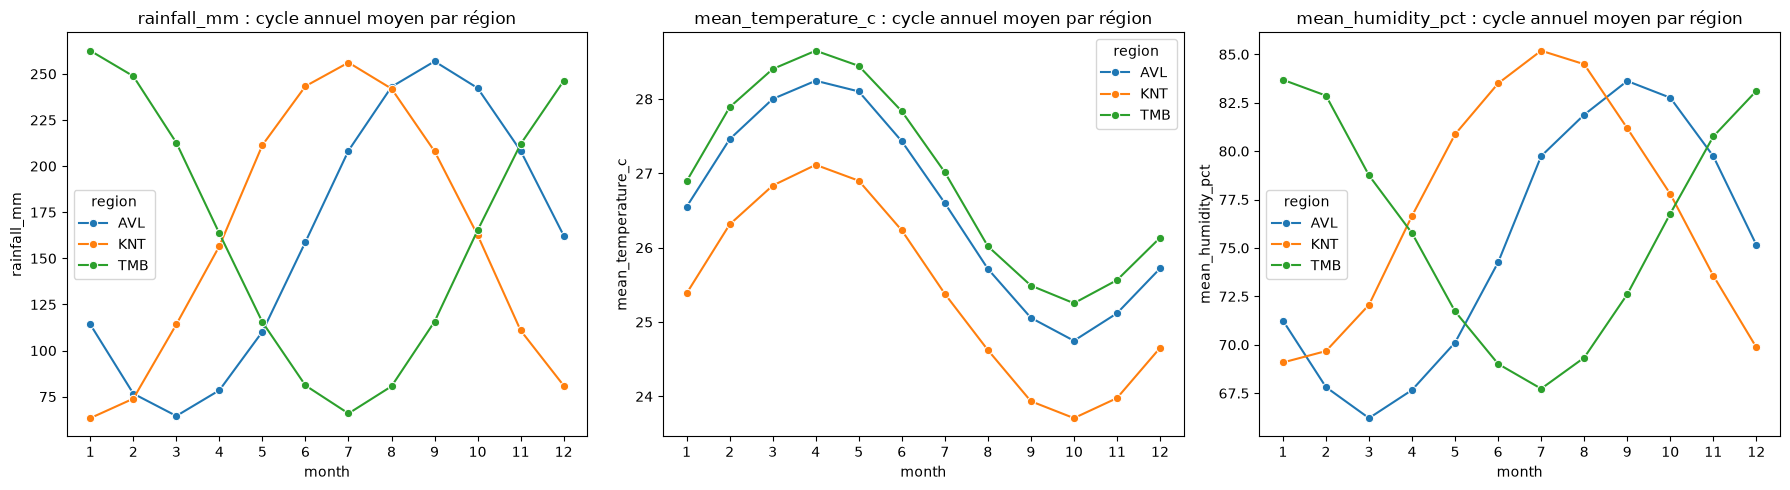

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['rainfall_mm', 'mean_temperature_c', 'mean_humidity_pct']):
    sns.lineplot(data=df_fe, x='month', y=col, hue='region', errorbar=None, marker='o', ax=ax)
    ax.set_xticks(range(1, 13))
    ax.set_title(f"{col} : cycle annuel moyen par région")
plt.tight_layout()
plt.show()

### - Lecture du cycle saisonnier

- **Les trois régions n'ont pas le même cycle de pluie** : pic en juillet pour KNT (≈ 256 mm), en septembre pour AVL (≈ 257 mm) et en **janvier** pour TMB (≈ 263 mm, creux en juillet ≈ 66 mm). TMB est quasiment en opposition de phase avec KNT.
- La moyenne par saison (tableau ci-dessus) mélange les trois régions et lisse donc ces différences : une saison "calendaire" n'a pas le même sens climatique partout. Toute comparaison avec les chauves-souris doit se faire **par région**.
- Les codes météo exceptionnels sont plus fréquents en hiver (`DRY_SPELL` ≈ 3.3 %) et en automne (`HEAVY_RAIN` ≈ 4 %), cohérent avec le cycle de pluie.

### b. Détection : le site KNT-KES en avril 2024

Dans `bat_surveys.ipynb`, le site **KNT-KES** (habitat karstique) présente un effondrement des comptages en avril 2024. Question posée à ce fichier : **l'environnement a-t-il changé ce mois-là ?** On compare avril 2024 (1) à l'historique du site lui-même et (2) aux autres sites le même mois, avec un z-score.

In [42]:
vars_env = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct',
            'habitat_disturbance_index', 'pesticide_index', 'data_completeness_pct']
mois_cible = pd.Timestamp('2024-04-01')

kes = df_fe[df_fe['site_code'] == 'KNT-KES'].sort_values('reporting_month').set_index('reporting_month')
print("KNT-KES :", len(kes), "mois, usage du sol :", kes['land_use_category'].unique())
print("Code météo en avril 2024 :", kes.loc[mois_cible, 'weather_exception_code'])

# (1) z-score par rapport à l'historique du site
z_site = (kes[vars_env] - kes[vars_env].mean()) / kes[vars_env].std()
# (2) z-score par rapport à tous les sites le même mois
tous = df_fe[df_fe['reporting_month'] == mois_cible]
z_reseau = (kes.loc[mois_cible, vars_env] - tous[vars_env].mean()) / tous[vars_env].std()

comparaison = pd.DataFrame({
    'valeur avril 2024': kes.loc[mois_cible, vars_env],
    'z vs historique du site': z_site.loc[mois_cible],
    'z vs autres sites (avr. 2024)': z_reseau,
}).round(2)
display(comparaison)

print("Plus grand |z| atteint par KNT-KES sur toute sa série (par variable) :")
display(z_site.abs().max().round(2))

KNT-KES : 78 mois, usage du sol : <StringArray>
['karst_habitat']
Length: 1, dtype: str
Code météo en avril 2024 : NORMAL


,valeur avril 2024,z vs historique du site,z vs autres sites (avr. 2024)
mean_temperature_c,28.19,1.99,0.18
rainfall_mm,140.60,-0.14,0.20
mean_humidity_pct,73.70,-0.28,0.00
vegetation_cover_pct,69.90,-0.29,0.82
habitat_disturbance_index,7.90,-2.05,-1.43
pesticide_index,19.40,-0.51,-0.36
data_completeness_pct,92.10,-1.60,-1.18


Plus grand |z| atteint par KNT-KES sur toute sa série (par variable) :


mean_temperature_c           2.04
rainfall_mm                  1.77
mean_humidity_pct            2.12
vegetation_cover_pct         2.02
habitat_disturbance_index    2.48
pesticide_index              3.02
data_completeness_pct        2.30
dtype: float64

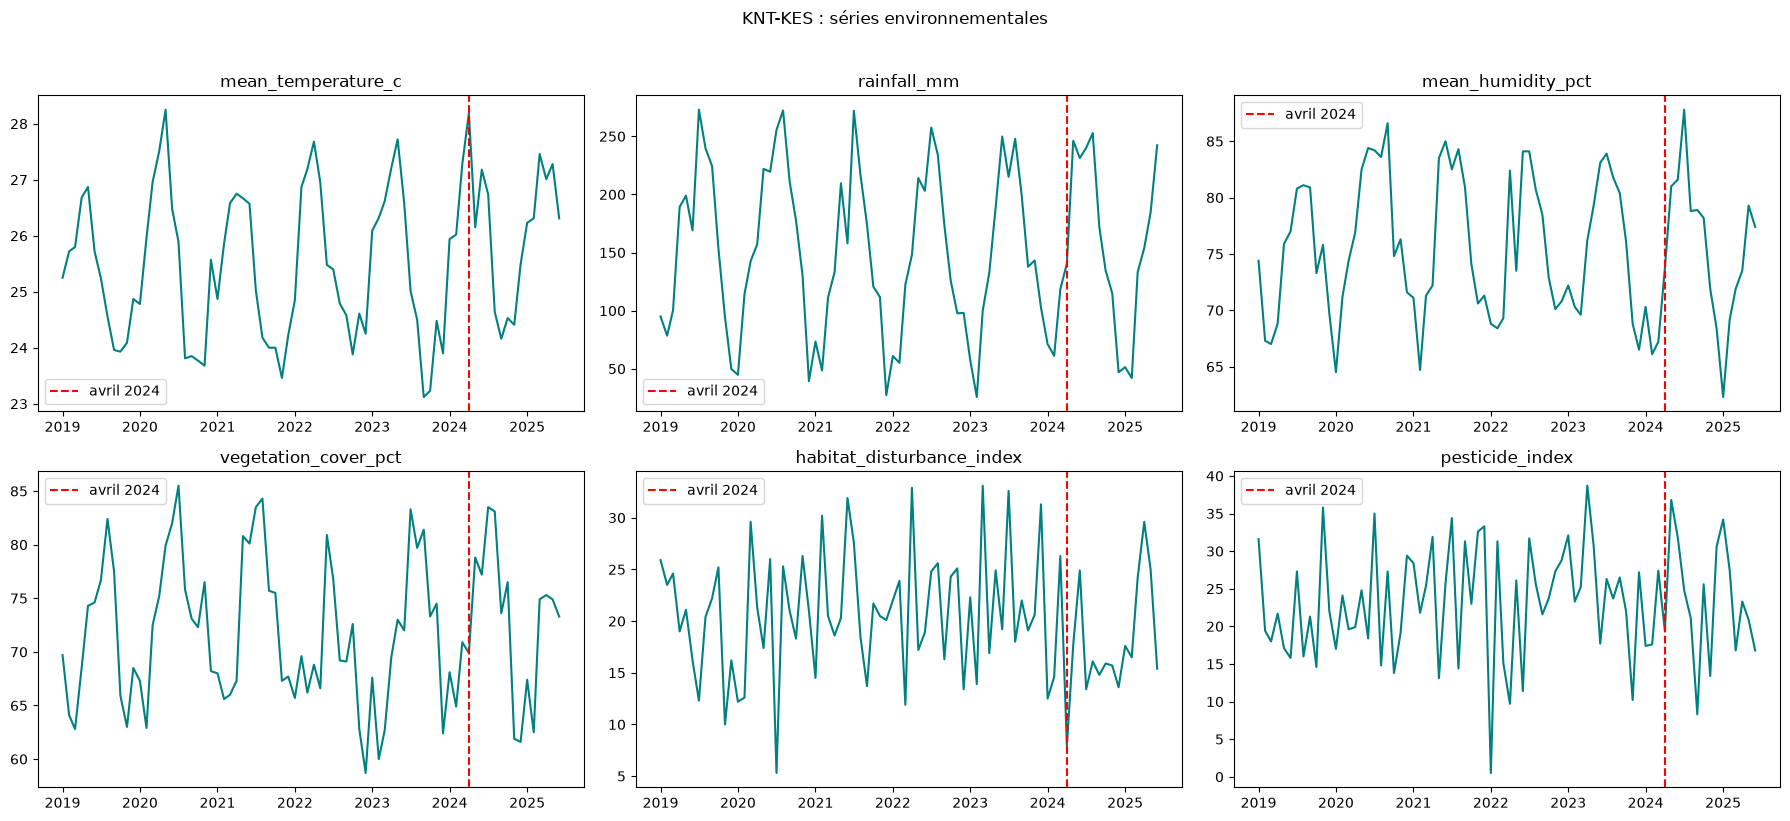

region  weather_exception_code
AVL     NORMAL                    60
        DRY_SPELL                  6
KNT     NORMAL                    66
TMB     NORMAL                    60
Name: count, dtype: int64

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct',
                                  'vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index']):
    ax.plot(kes.index, kes[col], color='teal')
    ax.axvline(mois_cible, color='red', linestyle='--', label='avril 2024')
    ax.set_title(col)
    ax.legend()
plt.suptitle("KNT-KES : séries environnementales", y=1.02)
plt.tight_layout()
plt.show()

# Y a-t-il eu un code météo exceptionnel dans la région autour de la date ?
fenetre = df_fe[(df_fe['reporting_month'] >= '2024-03-01') & (df_fe['reporting_month'] <= '2024-05-01')]
display(fenetre.groupby('region')['weather_exception_code'].value_counts())

### - Conclusion de la détection

**Rien d'anormal côté environnement à KNT-KES en avril 2024.**
- Code météo `NORMAL`, et aucun code exceptionnel dans toute la région KNT de mars à mai 2024.
- Par rapport à l'historique du site, les écarts restent modérés : température ≈ +2.0 σ (plutôt chaud), perturbation ≈ -2.05 σ (**moins** perturbé, pas plus), complétude des données ≈ -1.6 σ. Pluie, humidité, végétation et pesticides sont proches de la moyenne (|z| < 0.6).
- Par rapport aux autres sites le même mois, tout est |z| < 1.5.
- Sur toute sa série, KNT-KES atteint ailleurs des écarts plus forts (pesticides ≈ 3.0 σ en janvier 2022) sans effondrement associé.

Ce fichier **n'explique donc pas** la chute observée chez les chauves-souris : la cause est à chercher dans les autres fichiers du lot. En revanche, la baisse de `data_completeness_pct` (≈ 92 %) est un point à recouper avec la qualité de collecte des relevés.

*Limite : un seul mois et un seul site, z-scores calculés sur des distributions pas strictement normales ; c'est un indice de plausibilité, pas un test statistique.*

### c. Narratif propre à ce fichier : dérive dans le temps

Indépendamment des chauves-souris : certains sites ou certaines régions se dégradent-ils (végétation en baisse, perturbation ou pesticides en hausse) entre 2019 et 2025 ? On calcule la pente de chaque variable par site et on regarde si des sites ou des régions se détachent.

In [44]:
t = (df_fe['reporting_month'] - df_fe['reporting_month'].min()).dt.days / 365.25
vars_derive = ['vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index',
               'mean_temperature_c', 'data_completeness_pct']

# 1. Évolution annuelle par région
display(df_fe.groupby(['region', 'year'])[vars_derive].mean().round(1).unstack(0))

# 2. Pente (variation par an) de chaque variable, site par site
pentes = pd.DataFrame({
    s: {c: np.polyfit(t[g.index], g[c], 1)[0] for c in vars_derive}
    for s, g in df_fe.groupby('site_code')
}).T
pentes['land_use'] = df_fe.groupby('site_code')['land_use_category'].first()
display(pentes.describe().round(2))

# 3. Sites avec la plus forte dérive
for c in vars_derive[:3]:
    print(c)
    display(pentes[[c, 'land_use']].sort_values(c).iloc[[0, 1, 2, -3, -2, -1]].round(2))

vegetation_cover_pct             habitat_disturbance_index              \
region                  AVL   KNT   TMB                       AVL   KNT   TMB   
year                                                                            
2019                   59.1  59.9  65.0                      31.8  32.1  27.1   
2020                   59.0  60.2  64.7                      30.9  31.7  28.0   
2021                   58.5  60.2  64.4                      31.1  31.8  27.5   
2022                   59.1  60.1  64.7                      31.2  31.6  27.5   
2023                   59.1  60.2  64.2                      31.7  32.4  27.7   
2024                   58.4  60.1  65.0                      31.9  32.2  26.9   
2025                   54.7  59.0  66.0                      31.4  31.6  27.9   

       pesticide_index             mean_temperature_c              \
region             AVL   KNT   TMB                AVL   KNT   TMB   
year                                                                
2019              31.7  23.2  20.4               26.4  25.3  26.8   
2020              30.8  23.1  20.2               26.5  25.3  26.9   
2021              30.7  23.5  20.9               26.5  25.3  26.9   
2022              30.4  23.1  20.6               26.6  25.5  27.0   
2023              30.0  23.7  20.0               26.6  25.5  27.0   
2024              30.9  23.8  20.5               26.7  25.6  27.1   
2025              30.9  23.0  21.9               27.9  26.6  28.2   

       data_completeness_pct              
region                   AVL   KNT   TMB  
year                                      
2019                    96.0  95.9  96.0  
2020                    95.9  96.3  96.1  
2021                    96.0  96.0  96.1  
2022                    96.0  96.2  95.8  
2023                    95.8  95.8  95.7  
2024                    96.0  95.7  95.8  
2025                    96.0  96.4  96.1

,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,mean_temperature_c,data_completeness_pct
count,64.00,64.00,64.00,64.00,64.00
mean,-0.01,0.02,-0.01,0.06,-0.03
std,0.20,0.27,0.47,0.03,0.16
min,-0.41,-0.55,-1.09,-0.01,-0.38
25%,-0.14,-0.17,-0.27,0.03,-0.12
50%,-0.03,0.05,0.00,0.06,-0.02
75%,0.11,0.20,0.28,0.08,0.04
max,0.53,0.63,1.04,0.13,0.36


vegetation_cover_pct


,vegetation_cover_pct,land_use
AVL-DER,-0.41,mixed_forest
TMB-VZT,-0.32,coastal_habitat
KNT-TEX,-0.32,mixed_forest
TMB-HFR,0.40,mixed_forest
KNT-YRX,0.42,mixed_forest
KNT-CHP,0.53,karst_habitat


habitat_disturbance_index


,habitat_disturbance_index,land_use
KNT-UJJ,-0.55,mixed_forest
KNT-GKR,-0.52,mixed_forest
AVL-FNM,-0.50,research_site
TMB-BRC,0.51,durian_orchard
KNT-YRG,0.58,degraded_land
AVL-ORR,0.63,research_site


pesticide_index


,pesticide_index,land_use
KNT-QWU,-1.09,karst_habitat
TMB-WQL,-0.93,mixed_forest
KNT-DMJ,-0.81,mixed_forest
KNT-CHP,0.80,karst_habitat
KNT-YRG,0.95,degraded_land
TMB-GWP,1.04,coastal_habitat


### - Conclusion : dérive dans le temps

- **Pas de dégradation de fond entre 2019 et 2024.** Végétation, perturbation et pesticides restent stables dans chaque région (variations d'au plus 1 point d'une année à l'autre). Les pentes par site sont centrées sur 0 (moyenne ≈ 0 par an) : les sites qui montent ou baissent se compensent, sans tendance commune.
- **Hausse de température en 2025 :** environ +1 °C dans les trois régions (AVL 26.7 → 27.9, KNT 25.6 → 26.6, TMB 27.1 → 28.2). Les données 2025 s'arrêtent en juin : il faut vérifier que cette hausse n'est pas un simple effet de saison (mois chauds seulement).
- **Baisse de végétation à AVL en 2025 :** 59 % → 55 %, la seule variation notable de ce type, à recouper avec les autres fichiers.
- Les sites aux plus fortes pentes (± 0.5 point par an) n'ont pas d'usage du sol commun : ce sont des cas isolés, pas un phénomène de groupe.

# 11. Synthèse du nettoyage

| Problème identifié | Colonnes concernées | Traitement appliqué |
|---|---|---|
| Doublons stricts (2) et doublons de clé (site, mois) | toutes | suppression, on garde la 1ère occurrence |
| Date en texte | `reporting_month` | conversion en `datetime` + extraction `year` / `month` |
| Séparateur décimal virgule | températures, pluie, humidité | remplacement `,` → `.` |
| Unité collée à la valeur (`25.8 C`, `102.7 mm`) | `mean_temperature_c`, `rainfall_mm` | suppression du suffixe, une seule unité par colonne |
| Casse incohérente (18 catégories pour 8 réelles) | `land_use_category` | normalisation en minuscules |
| Manquants "porteurs de sens" (96%) | `weather_exception_code` | remplacés par la modalité `NORMAL` |
| Trous isolés dans les séries | `vegetation_cover_pct`, `pesticide_index` | interpolation temporelle **par site** |
| Valeurs extrêmes | variables numériques | **conservées** (réalités environnementales, pas des erreurs) |
| Variables nominales | `land_use_category`, `weather_exception_code` | One-Hot (`drop_first=False`) dans un fichier **séparé** `_encoded.csv` |

**Biais introduits et assumés** (cf. cours : nettoyer = choisir = introduire des biais) :
- l'interpolation invente 25 valeurs qui n'ont jamais été mesurées (0.3% du jeu, impact négligeable mais réel) ;
- en gardant la 1ère occurrence des doublons, on suppose que les deux lignes étaient identiques — ce qui a
été vérifié ici ;
- transformer l'absence de code météo en `NORMAL` suppose que le protocole de saisie était fiable : si un
opérateur a simplement oublié de remplir le champ un mois anormal, ce mois est désormais classé "normal".

# 12. Clustering (Cours 2)

### a. Choix des variables pertinentes

Le clustering regroupe des lignes par ressemblance : on ne garde que les variables qui décrivent l'environnement du site ce mois-là.

- **Gardées (numériques)** : `mean_temperature_c`, `rainfall_mm`, `mean_humidity_pct`, `vegetation_cover_pct`, `habitat_disturbance_index`, `pesticide_index`.
- **Gardées (catégorielles encodées)** : les One-Hot `land_use_category_*` et `weather_exception_code_*`.
- **Écartées** :
  - `data_completeness_pct` : métadonnée de qualité de collecte, non corrélée à l'environnement ;
  - `site_code`, `reporting_month` : identifiants, pas des caractéristiques ;
  - `year`, `month` : le temps n'est pas une mesure ; la saisonnalité est déjà portée par la pluie et la température.
- **Point de vigilance** : `rainfall_mm` et `mean_humidity_pct` sont corrélées (≈ 0.75). Elles pèsent donc deux fois dans la distance ; on les garde car elles restent deux mesures distinctes.

In [45]:
cols_cluster_num = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct',
                    'vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index']
cols_cluster = cols_cluster_num + cols_land_use + cols_weather

X = df_encoded[cols_cluster].copy()

print("Matrice de clustering :", X.shape)
print("Valeurs manquantes :", X.isna().sum().sum())
print("Types :", X.dtypes.value_counts().to_dict())

Matrice de clustering : (4992, 17)
Valeurs manquantes : 0
Types : {dtype('int64'): 11, dtype('float64'): 6}


### b. Standardisation

Le clustering repose sur des distances. Sans standardisation, une variable à grande échelle (`rainfall_mm`, de 5 à 384) écraserait une variable à petite échelle (`mean_temperature_c`, de 21 à 32).

`StandardScaler` ramène chaque variable numérique à une moyenne de 0 et un écart-type de 1 : `z = (x - moyenne) / écart-type`.

Les colonnes One-Hot sont déjà en 0/1 : on ne les modifie pas.

In [46]:
from sklearn.preprocessing import StandardScaler

X_scaled = X.copy()
X_scaled[cols_cluster_num] = StandardScaler().fit_transform(X[cols_cluster_num])

print("Moyennes (≈ 0) :")
print(X_scaled[cols_cluster_num].mean().round(3))
print("\nÉcarts-types (≈ 1) :")
print(X_scaled[cols_cluster_num].std().round(3))

Moyennes (≈ 0) :
mean_temperature_c           0.0
rainfall_mm                 -0.0
mean_humidity_pct            0.0
vegetation_cover_pct         0.0
habitat_disturbance_index   -0.0
pesticide_index             -0.0
dtype: float64

Écarts-types (≈ 1) :
mean_temperature_c           1.0
rainfall_mm                  1.0
mean_humidity_pct            1.0
vegetation_cover_pct         1.0
habitat_disturbance_index    1.0
pesticide_index              1.0
dtype: float64


In [47]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### c. K-Means : choix du nombre de clusters k

K-Means demande de fixer k à l'avance. On teste k de 2 à 10 avec deux critères :
- **Coude** : l'inertie (distance des points à leur centre) baisse toujours quand k augmente ; on cherche le k où la baisse ralentit nettement.
- **Silhouette** : mesure si chaque point est plus proche de son cluster que des autres (de -1 à 1). On cherche le k au score le plus élevé.

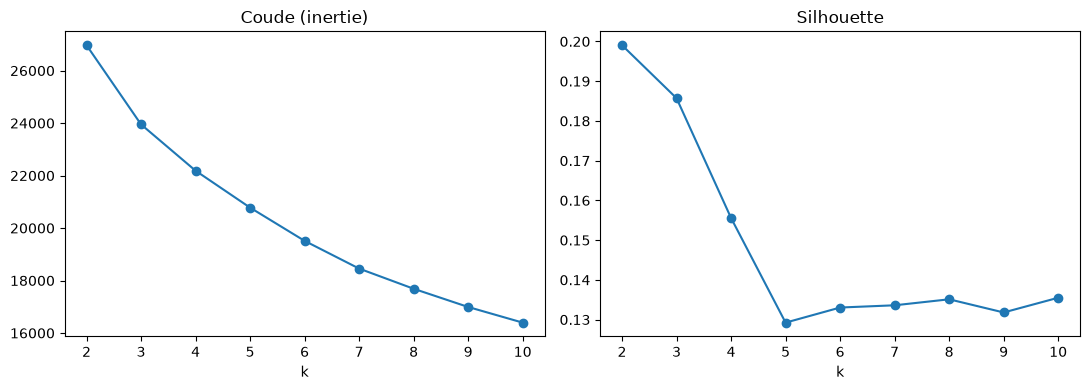

{2: np.float64(0.199), 3: np.float64(0.186), 4: np.float64(0.156), 5: np.float64(0.129), 6: np.float64(0.133), 7: np.float64(0.134), 8: np.float64(0.135), 9: np.float64(0.132), 10: np.float64(0.136)}


In [48]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, 'o-'); ax[0].set_title("Coude (inertie)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silhouettes, 'o-'); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

print(dict(zip(ks, np.round(silhouettes, 3))))

### - Ce qu'on déduit du résultat K-Means

- **Coude :** l'inertie baisse de façon régulière (≈ 27 000 → 16 400) sans cassure nette : il n'y a pas de vrai « coude ». La baisse est un peu plus forte de k=2 à k=4, puis la courbe devient presque une droite.
- **Silhouette :** le meilleur score est à **k=2 (0.199)**, puis **k=3 (0.186)**. Il chute à k=4 (0.156) et k=5 (0.129), puis reste plat autour de 0.13 jusqu'à k=10.
- **Choix :** on retient **k=3** comme compromis : sa silhouette est proche de celle de k=2 et il donne un découpage plus riche à interpréter. k=2 reste à comparer.
- **Limite importante :** tous les scores sont inférieurs à 0.25, donc les groupes sont **peu séparés**. Les données forment un nuage continu plutôt que des groupes nets : les clusters seront des profils moyens, pas des catégories strictes. Une partie de la structure vient probablement des colonnes One-Hot (type d'usage du sol), qui créent des blocs naturels.

### d. Classification hiérarchique et dendrogramme

Ici on ne fixe pas k au départ : l'algorithme part de chaque ligne seule, puis fusionne à chaque étape les deux groupes les plus proches, jusqu'à n'en avoir plus qu'un. L'arbre de ces fusions est le **dendrogramme**.

- **Méthode Ward** : fusionne les groupes qui font le moins augmenter la dispersion interne, ce qui donne des groupes compacts (proche de K-Means).
- **Lecture** : l'axe vertical est la distance de fusion. On « coupe » l'arbre à une hauteur ; le nombre de branches coupées donne k. Un grand saut vertical avant une fusion indique que l'on fusionne des groupes très différents, donc qu'il vaut mieux s'arrêter avant.
- Avec 4992 lignes, on n'affiche que les 20 derniers regroupements (`truncate_mode='lastp'`), sinon l'arbre est illisible.
- On coupe à k=3 pour comparer avec K-Means via un tableau croisé.

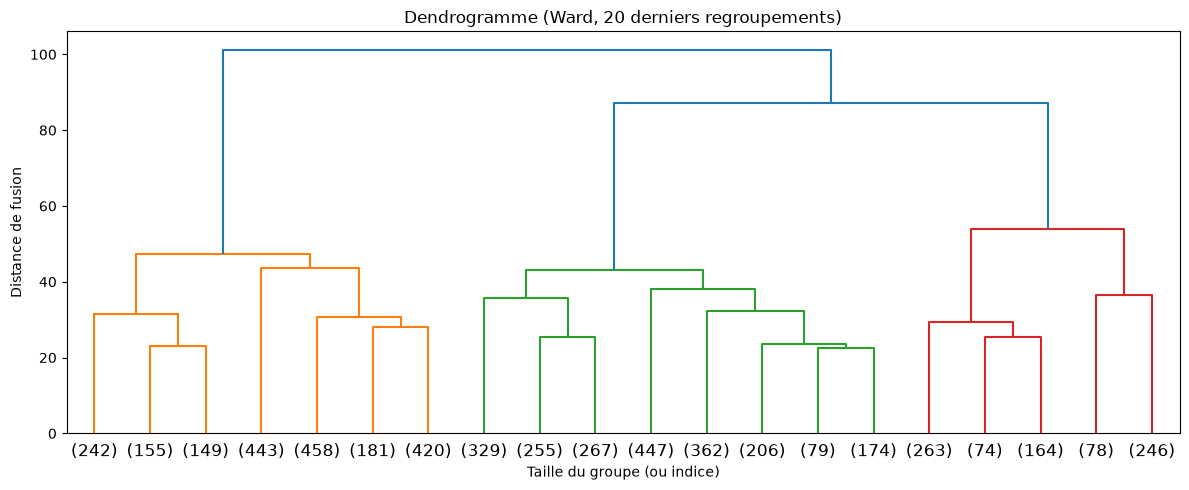

Taille des 3 clusters hiérarchiques : [2048 2119  825]

K-Means (lignes) vs hiérarchique (colonnes) :


hiérarchique,1,2,3
kmeans,,,
0,230,1793,13
1,1728,113,173
2,90,213,639


In [49]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title("Dendrogramme (Ward, 20 derniers regroupements)")
plt.xlabel("Taille du groupe (ou indice)"); plt.ylabel("Distance de fusion")
plt.tight_layout(); plt.show()

labels_hc = fcluster(Z, t=3, criterion='maxclust')
print("Taille des 3 clusters hiérarchiques :", np.bincount(labels_hc)[1:])

labels_km = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_scaled)
print("\nK-Means (lignes) vs hiérarchique (colonnes) :")
display(pd.crosstab(labels_km, labels_hc, rownames=['kmeans'], colnames=['hiérarchique']))

### - Résultat de la classification hiérarchique

- Le dendrogramme montre **3 grandes branches**, avec un long saut vertical avant les deux dernières fusions : cela confirme **k=3**.
- Les 3 clusters hiérarchiques (2048 / 2119 / 825 lignes) recoupent largement ceux de K-Means : chaque cluster K-Means tombe en grande majorité dans un seul cluster hiérarchique (recouvrement résiduel d'environ 10-15 %).
- Les deux méthodes sont d'accord sur l'essentiel, on retient donc **k=3**.

### e. Interprétation des clusters

Qu'est-ce qui différencie les 3 groupes K-Means ? On regarde le profil moyen de chaque cluster sur les 6 mesures, puis sa composition en usage du sol et en région (la région n'a pas servi au clustering).

In [50]:
df_clust = df_stats.copy()
df_clust['cluster'] = labels_km
df_clust['region'] = df_clust['site_code'].str[:3]

print("Taille des clusters :", df_clust['cluster'].value_counts().sort_index().to_dict())

print("\nProfil moyen par cluster :")
display(df_clust.groupby('cluster')[cols_cluster_num].mean().round(1))

print("\nUsage du sol par cluster (% de chaque cluster) :")
display((pd.crosstab(df_clust['cluster'], df_clust['land_use_category'], normalize='index') * 100).round(0))

print("\nRégion par cluster (% de chaque cluster) :")
display((pd.crosstab(df_clust['cluster'], df_clust['region'], normalize='index') * 100).round(0))

Taille des clusters : {0: 2036, 1: 2014, 2: 942}

Profil moyen par cluster :


,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index
cluster,,,,,,
0,27.1,99.0,70.0,60.5,25.5,22.8
1,25.9,223.8,81.6,70.1,26.1,24.6
2,25.9,154.9,76.3,42.7,50.0,30.8



Usage du sol par cluster (% de chaque cluster) :


land_use_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
cluster,,,,,,,,
0,17.0,1.0,20.0,14.0,1.0,33.0,3.0,11.0
1,18.0,1.0,18.0,18.0,1.0,32.0,5.0,8.0
2,7.0,13.0,0.0,6.0,39.0,18.0,7.0,9.0



Région par cluster (% de chaque cluster) :


region,AVL,KNT,TMB
cluster,,,
0,35.0,28.0,37.0
1,28.0,36.0,37.0
2,49.0,44.0,8.0


### - Ce qui différencie les 3 clusters

- **Cluster 2 (942 lignes) : sites perturbés.** Perturbation de l'habitat ≈ 50 (le double des autres), pesticides les plus hauts (≈ 31), végétation la plus basse (≈ 43 %). Il est dominé par `mixed_agriculture` (39 % contre 1 % ailleurs) et `degraded_land` (13 % contre 1 %), sans aucun verger de durian. C'est le groupe le plus net.
- **Cluster 0 (2036 lignes) : mois secs et chauds.** Température la plus haute (27,1 °C), pluie 99 mm, humidité 70 %, perturbation faible (≈ 25).
- **Cluster 1 (2014 lignes) : mois humides et végétalisés.** Pluie ≈ 224 mm, humidité ≈ 82 %, végétation la plus haute (≈ 70 %), perturbation faible (≈ 26).
- Les clusters 0 et 1 ont presque le même usage du sol : ils ne se distinguent que par le climat (pluie / humidité), donc par un effet de saison ou de région plutôt que de site. Leur frontière floue explique la faible silhouette.
- **Région :** 0 et 1 sont répartis sur les 3 régions (28-37 %), alors que le cluster 2 est presque absent de TMB (8 %) : TMB est la région la moins perturbée.

**Conclusion :** les clusters séparent d'abord les sites perturbés (cluster 2), puis, parmi les sites peu perturbés, les mois secs (0) des mois humides (1).

### f. Visualisation en 2D (PCA)

Les données ont 17 dimensions : on ne peut pas les tracer directement. La PCA les projette sur 2 axes (PC1, PC2) qui conservent le maximum de variance, et on colore chaque point par son cluster K-Means. Plus les couleurs sont séparées, plus les groupes sont nets.

Variance expliquée (PC1, PC2) : [0.294 0.197] -> total 0.491


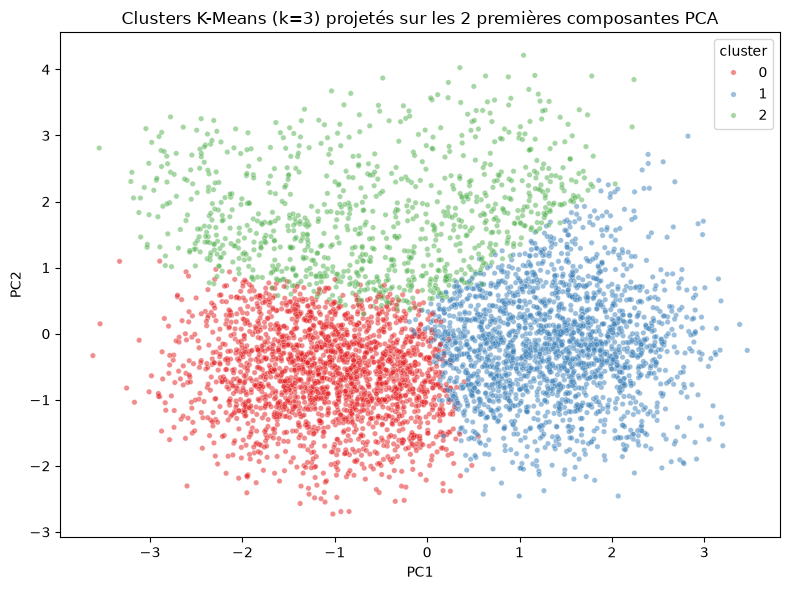

In [51]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print("Variance expliquée (PC1, PC2) :", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels_km, palette='Set1', alpha=0.5, s=15)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Clusters K-Means (k=3) projetés sur les 2 premières composantes PCA")
plt.legend(title="cluster")
plt.tight_layout(); plt.show()

### - Lecture de la projection PCA

- **Variance expliquée : 29 % (PC1) + 20 % (PC2) = 49 %.** Le schéma ne montre que la moitié de l'information : il aide à lire, mais ne remplace pas les tableaux.
- **PC1 (horizontal) = axe humide / sec** : tiré par la pluie, l'humidité et la végétation, opposé à la température. Le cluster 0 (sec, chaud) est à gauche, le cluster 1 (humide) à droite.
- **PC2 (vertical) = axe perturbation** : tiré par la perturbation de l'habitat et les pesticides, opposé à la végétation. Le cluster 2 (sites perturbés) est en haut, bien séparé des deux autres.
- Les nuages se touchent en bordure (écart-type ≈ 0.7 à 1.2 pour des centres distants de 1 à 2 unités) : il n'y a pas de frontière nette, ce qui confirme la faible silhouette (0.186). Les clusters sont des zones d'un nuage continu, pas des groupes isolés.

**Bilan du clustering :** k=3 donne trois profils interprétables (sites perturbés, mois secs, mois humides), confirmés par K-Means et par la classification hiérarchique, mais peu séparés.

# 13. Patterns et anomalies (Cours 3)

### a. Anomalies statistiques par colonne (IQR + z-score)

Deux règles classiques, appliquées colonne par colonne sur les 7 variables numériques :
- **IQR** : anomalie si la valeur sort de [Q1 - 1.5×IQR ; Q3 + 1.5×IQR] (robuste, ne suppose pas de loi normale) ;
- **z-score** : anomalie si |z| > 3 (suppose une distribution proche de la normale, plus stricte).

On réutilise les candidats repérés au nettoyage (section 6). Rappel : aucune valeur impossible n'a été trouvée, ce sont donc des extrêmes réels, à interpréter et non à corriger.

In [52]:
z = (df_stats[cols_num] - df_stats[cols_num].mean()) / df_stats[cols_num].std()
q1, q3 = df_stats[cols_num].quantile(0.25), df_stats[cols_num].quantile(0.75)
iqr = q3 - q1
masque_iqr = (df_stats[cols_num] < q1 - 1.5 * iqr) | (df_stats[cols_num] > q3 + 1.5 * iqr)
masque_z = z.abs() > 3

resume = pd.DataFrame({'IQR': masque_iqr.sum(), '|z| > 3': masque_z.sum(), 'les deux': (masque_iqr & masque_z).sum()})
display(resume)

anom_stat = df_stats[(masque_iqr | masque_z).any(axis=1)]
print("Lignes avec au moins une anomalie :", len(anom_stat), "sur", len(df_stats))
print("\nRégions :", anom_stat['site_code'].str[:3].value_counts().to_dict())
print("Sites les plus touchés :")
display(anom_stat['site_code'].value_counts().head(5))
print("Usage du sol :", anom_stat['land_use_category'].value_counts().to_dict())

,IQR,|z| > 3,les deux
mean_temperature_c,9,4,4
rainfall_mm,0,0,0
mean_humidity_pct,0,0,0
vegetation_cover_pct,46,8,8
habitat_disturbance_index,19,8,8
pesticide_index,1,2,1
data_completeness_pct,13,11,11


Lignes avec au moins une anomalie : 85 sur 4992

Régions : {'KNT': 55, 'AVL': 19, 'TMB': 11}
Sites les plus touchés :


site_code
KNT-GGN    37
AVL-GRB     9
TMB-UVF     6
KNT-UJJ     5
KNT-YRX     5
Name: count, dtype: int64

Usage du sol : {'degraded_land': 37, 'mixed_forest': 24, 'mixed_agriculture': 16, 'protected_forest': 3, 'coastal_habitat': 2, 'research_site': 1, 'durian_orchard': 1, 'karst_habitat': 1}


**Z-score modifié** (3ᵉ méthode univariée du cours) : même idée que le z-score, mais avec la **médiane** et l'**écart absolu médian** (EAM) au lieu de la moyenne et de l'écart-type, donc moins influencé par les valeurs extrêmes elles-mêmes. On utilise la forme standard `0.6745 × (x − médiane) / EAM` avec le seuil `|z| > 3.5` (le cours donne `(x − médiane) / EAM` sans fixer de seuil ; sans le facteur 0.6745 le seuil de 3 repérait 656 lignes, soit 13 % du jeu, ce qui n'a plus de sens pour des anomalies).

In [53]:
med = df_stats[cols_num].median()
mad = (df_stats[cols_num] - med).abs().median()
z_mod = 0.6745 * (df_stats[cols_num] - med) / mad
masque_zmod = z_mod.abs() > 3.5

display(pd.DataFrame({'z modifié > 3.5': masque_zmod.sum()}))

anom_zmod = df_stats[masque_zmod.any(axis=1)]
print("Lignes avec au moins une anomalie (z modifié) :", len(anom_zmod))
display(anom_zmod[['site_code', 'reporting_month'] + cols_num])

,z modifié > 3.5
mean_temperature_c,0
rainfall_mm,0
mean_humidity_pct,0
vegetation_cover_pct,4
habitat_disturbance_index,0
pesticide_index,0
data_completeness_pct,1


Lignes avec au moins une anomalie (z modifié) : 5


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
2028,KNT-GGN,2019-01-01,26.28,59.5,76.8,15.0,76.1,5.3,97.6
2053,KNT-GGN,2021-02-01,28.29,115.4,72.2,15.0,72.5,0.2,96.1
2099,KNT-GGN,2024-12-01,26.31,106.4,72.9,15.0,68.3,6.1,95.9
3427,KNT-YRX,2025-02-01,25.49,68.7,72.1,15.0,49.9,14.5,95.3
3909,TMB-HFR,2019-10-01,24.80,138.4,79.1,47.0,11.1,29.3,85.5


### b. Anomalies multivariées (Isolation Forest + LOF)

Une ligne peut être normale colonne par colonne mais étrange par la **combinaison** de ses valeurs (ex : forte pluie avec une humidité basse). On utilise deux méthodes du cours sur les 6 mesures standardisées (les mêmes que pour le clustering, sans les One-Hot ni `data_completeness_pct`) :
- **Isolation Forest** : des arbres aléatoires isolent les points ; ceux isolés le plus vite sont les plus suspects (vue globale). `contamination=0.02` : on retient les ~2 % de lignes les plus isolées (≈ 100), seuil choisi pour rester comparable aux 85 anomalies statistiques.
- **LOF** : compare la densité locale d'une ligne à celle de ses 20 plus proches voisines (`n_neighbors=20`). LOF ≈ 1 = normal, > 1 = suspect (vue locale). Le cours conseille de trier par LOF décroissant.

Les deux méthodes ne voient pas les mêmes choses : on regarde donc leur recoupement entre elles et avec l'étape a.

In [54]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

Xa = X_scaled[cols_cluster_num]

iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42).fit(Xa)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)

res = df_stats[['site_code', 'reporting_month', 'land_use_category']].copy()
res['score_if'] = -iso.score_samples(Xa)
res['anom_if'] = iso.predict(Xa) == -1
res['anom_lof'] = lof.fit_predict(Xa) == -1
res['score_lof'] = -lof.negative_outlier_factor_
res['anom_stat'] = res.index.isin(anom_stat.index)

print("Isolation Forest :", res['anom_if'].sum(), "| LOF :", res['anom_lof'].sum(), "| les deux :", (res['anom_if'] & res['anom_lof']).sum())
print("Recoupement avec les anomalies statistiques (85) : IF", (res['anom_if'] & res['anom_stat']).sum(), "| LOF", (res['anom_lof'] & res['anom_stat']).sum())

for nom in ['if', 'lof']:
    a = res[res[f'anom_{nom}']]
    print(f"\n{nom.upper()} - régions :", a['site_code'].str[:3].value_counts().to_dict())
    print("Sites :", a['site_code'].value_counts().head(4).to_dict())
    print("Usage du sol :", a['land_use_category'].value_counts().head(3).to_dict())

print("\nTop 5 LOF (le plus suspect d'abord) :")
display(res.sort_values('score_lof', ascending=False).head(5)[['site_code', 'reporting_month', 'score_lof']])
print("Top 5 Isolation Forest :")
display(res.sort_values('score_if', ascending=False).head(5)[['site_code', 'reporting_month', 'score_if']])

Isolation Forest : 100 | LOF : 100 | les deux : 15
Recoupement avec les anomalies statistiques (85) : IF 32 | LOF 6

IF - régions : {'KNT': 55, 'AVL': 40, 'TMB': 5}
Sites : {'KNT-GGN': 49, 'AVL-GRB': 24, 'AVL-TRP': 9, 'TMB-NAC': 4}
Usage du sol : {'degraded_land': 49, 'mixed_agriculture': 34, 'durian_orchard': 6}

LOF - régions : {'KNT': 45, 'TMB': 28, 'AVL': 27}
Sites : {'KNT-BME': 8, 'AVL-MAR': 7, 'KNT-CHP': 6, 'TMB-UVF': 6}
Usage du sol : {'mixed_forest': 29, 'karst_habitat': 20, 'coastal_habitat': 18}

Top 5 LOF (le plus suspect d'abord) :


,site_code,reporting_month,score_lof
4038,TMB-HQL,2024-01-01,1.646836
2628,KNT-QWU,2023-07-01,1.481194
4507,TMB-SXP,2024-02-01,1.471716
4483,TMB-SXP,2022-02-01,1.447799
1413,AVL-SEY,2019-10-01,1.422812


Top 5 Isolation Forest :


,site_code,reporting_month,score_if
2094,KNT-GGN,2024-07-01,0.635798
625,AVL-GRB,2019-02-01,0.633385
1514,AVL-TRP,2021-09-01,0.625217
2044,KNT-GGN,2020-05-01,0.623228
656,AVL-GRB,2021-09-01,0.622310


### - Conclusion : anomalies multivariées

- **Isolation Forest** (vue globale) retrouve le même profil que l'étape a : sites très perturbés, surtout `KNT-GGN` (49 lignes) et `AVL-GRB` (24), usages `degraded_land` et `mixed_agriculture`. Il recoupe 32 des 85 anomalies statistiques.
- **LOF** (vue locale) trouve autre chose : des lignes dispersées sur les 3 régions (TMB 28), dans des sites peu perturbés (`mixed_forest`, `karst_habitat`, `coastal_habitat`). Seules 6 lignes recoupent l'étape a : ce sont des **combinaisons de valeurs inhabituelles**, invisibles colonne par colonne. Le plus suspect est `TMB-HQL` en janvier 2024 (LOF ≈ 1.65).
- Les deux méthodes ne partagent que 15 lignes : elles sont complémentaires, pas redondantes. Un LOF maximal à 1.65 reste modéré : ce sont des écarts légers, pas des cas extrêmes.
- **KNT-KES avril 2024** n'est détecté ni par l'une ni par l'autre (LOF ≈ 1.01) : l'environnement de ce mois est normal, ce qui confirme la conclusion de la section 10.b.

*Limite : `contamination=0.02` fixe d'avance le nombre d'anomalies (≈ 100) ; ce sont les 2 % les plus atypiques, pas forcément des anomalies réelles (cf. cours : un outlier n'est pas toujours une anomalie). À trancher à l'étape 4.*

### c. Règles d'association (Apriori)

Analyse de type « panier » : chaque ligne (site, mois) est une transaction, composée d'items. Les variables numériques doivent d'abord être **discrétisées** (cours p. 11) : on les découpe en 3 niveaux `bas / moyen / haut` (terciles). Items : région, code météo et les 6 mesures discrétisées.
- `land_use_category` est exclue : elle est redondante avec le site, et ses règles ne feraient que redire « tel usage = telle région ».
- **Apriori** (`min_support=0.03`, itemsets de 3 items max) puis règles `si → alors` avec confiance ≥ 0.5 et **lift > 1.3**.
- **Lecture** : support = fréquence de la règle ; confiance = P(alors | si) ; lift = combien de fois plus fréquent que le hasard (> 1 = lien réel).

In [55]:
%pip install mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

noms = {'mean_temperature_c': 'temp', 'rainfall_mm': 'pluie', 'mean_humidity_pct': 'humid',
        'vegetation_cover_pct': 'veg', 'habitat_disturbance_index': 'perturb', 'pesticide_index': 'pesti'}

trans = pd.DataFrame({'region': df_fe['region'], 'meteo': df_fe['weather_exception_code']})
for col, nom in noms.items():
    trans[nom] = pd.qcut(df_stats[col], 3, labels=['bas', 'moyen', 'haut']).astype(str)

basket = pd.get_dummies(trans, prefix_sep='=', dtype=bool)

freq = apriori(basket, min_support=0.03, use_colnames=True, max_len=3)
regles = association_rules(freq, metric='confidence', min_threshold=0.5)
regles = regles[regles['lift'] > 1.3].copy()
regles['si'] = regles['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
regles['alors'] = regles['consequents'].apply(lambda s: ' + '.join(sorted(s)))

print("Itemsets fréquents :", len(freq), "| règles retenues :", len(regles))
display(regles.sort_values('lift', ascending=False).head(10)[['si', 'alors', 'support', 'confidence', 'lift', 'leverage']].round(2))

print("Règles impliquant un code météo exceptionnel :",
      regles['alors'].str.contains('meteo=(?:DRY|HEAVY)').sum() + regles['si'].str.contains('meteo=(?:DRY|HEAVY)').sum())

Note: you may need to restart the kernel to use updated packages.
Itemsets fréquents : 1078 | règles retenues : 219



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,si,alors,support,confidence,lift,leverage
394,humid=haut + pesti=haut,pluie=haut,0.09,0.82,2.47,0.05
65,pluie=bas + region=AVL,humid=bas,0.10,0.82,2.44,0.06
157,pluie=haut + temp=haut,region=TMB,0.05,0.75,2.41,0.03
369,pesti=haut + pluie=bas,humid=bas,0.08,0.78,2.35,0.05
70,humid=haut + region=AVL,pluie=haut,0.08,0.78,2.34,0.04
356,humid=bas + veg=bas,pluie=bas,0.12,0.78,2.33,0.07
170,humid=haut + region=TMB,pluie=haut,0.08,0.77,2.33,0.05
326,pluie=haut + temp=bas,humid=haut,0.10,0.76,2.30,0.06
335,pluie=bas + temp=haut,humid=bas,0.11,0.77,2.29,0.06
349,humid=haut + temp=moyen,pluie=haut,0.09,0.76,2.29,0.05


Règles impliquant un code météo exceptionnel : 0


### - Conclusion : règles d'association

- **1078 itemsets fréquents, 219 règles** (confiance ≥ 0.5, lift > 1.3). Le lift maximal est modéré (≈ 2.5) : les liens sont réels mais pas très forts.
- Les meilleures règles sont **climatiques** : pluie haute ⇔ humidité haute (ex : humidité haute + pesticides hauts → pluie haute, confiance 0.82), pluie basse ⇔ humidité basse. C'est la corrélation pluie/humidité (≈ 0.75) déjà vue, retrouvée sous forme de règles.
- Elles reflètent aussi les cycles régionaux : pluie haute + température haute → `TMB` (confiance 0.75), pluie basse en `AVL` → humidité basse (0.82).
- **Aucune règle ne fait intervenir un code météo exceptionnel** (`DRY_SPELL`, `HEAVY_RAIN`) : ils sont trop rares (4 % des lignes) pour dépasser le support minimal de 0.03.
- Aucun motif nouveau sur les sites perturbés ni sur KNT-KES : ce volet confirme les corrélations connues plutôt qu'il n'apporte un narratif caché. Avec `land_use_category`, on ne retrouvait que « usage = région » (ex : AVL + habitat perturbé → `mixed_agriculture`, lift ≈ 7), d'où son exclusion.

*Limite : discrétisation en terciles (choix arbitraire), et support minimal qui masque les motifs rares, justement ceux des anomalies.*

# 14. Bloc 4 : graphes et processus (Cours 4)

Objectif du cours : construire un **graphe** à partir du jeu, le décrire (n, m, densité, degrés…), identifier les nœuds importants, détecter des communautés, puis (si pertinent) faire du process mining.

> **Note process mining** : `environmental_monthly` n'est **pas** un event log (pas de `case_id` / `activity` / `timestamp` d'événements de processus). Le process mining est donc **hors périmètre** sur ce fichier.


## Étape 1 — Définir les nœuds, les liens, leur orientation et leurs poids

### Choix du graphe (justification)

`environmental_monthly` décrit le **climat / habitat de 64 sites** dans le temps. Il n'y a pas de flux « A envoie quelque chose à B », donc un graphe de transport n'a pas de sens ici.

On construit un **graphe de similarité environnementale entre sites** :

| Élément | Choix | Pourquoi |
|---|---|---|
| **Nœuds** | les 64 `site_code` | unité spatiale du monitoring |
| **Liens** | similarité des **profils moyens** (température, pluie, humidité, végétation, perturbation, pesticides) | deux sites liés s'ils « se ressemblent » environnementalement |
| **Orientation** | **non orienté** | la similarité est symétrique |
| **Poids** | similarité cosinus des profils standardisés ∈ [−1, 1] (on ne garde que les poids ≥ seuil) | plus le poids est haut, plus les régimes environnementaux sont proches |
| **Seuil** | similarité cosinus ≥ **0.6** | compromis : graphe ni trop dense ni trop fragmenté |

Attente métier : les communautés devraient coller aux **régions** (AVL / KNT / TMB) et/ou aux **usages du sol** (ex. sites perturbés vs forêts), cohérent avec le clustering du Bloc 2.


In [56]:
# --- Étape 1 : construction du graphe de similarité entre sites ---
import networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

df_env = pd.read_csv("cleaned/environmental_monthly_clean.csv")
df_env["reporting_month"] = pd.to_datetime(df_env["reporting_month"])
df_env["region"] = df_env["site_code"].str[:3]

cols_profil = [
    "mean_temperature_c", "rainfall_mm", "mean_humidity_pct",
    "vegetation_cover_pct", "habitat_disturbance_index", "pesticide_index",
]

# Profil moyen par site (+ land_use majoritaire pour l'interprétation)
profil = df_env.groupby("site_code")[cols_profil].mean()
profil["region"] = profil.index.str[:3]
profil["land_use"] = df_env.groupby("site_code")["land_use_category"].agg(
    lambda s: s.mode().iloc[0]
)

# Similarité cosinus sur profils standardisés
X = StandardScaler().fit_transform(profil[cols_profil])
S = cosine_similarity(X)
sites = profil.index.tolist()

SEUIL = 0.6  # poids minimum pour créer une arête

G = nx.Graph()
for site in sites:
    G.add_node(
        site,
        region=profil.loc[site, "region"],
        land_use=profil.loc[site, "land_use"],
        disturbance=float(profil.loc[site, "habitat_disturbance_index"]),
        vegetation=float(profil.loc[site, "vegetation_cover_pct"]),
    )

n_edges = 0
for i in range(len(sites)):
    for j in range(i + 1, len(sites)):
        w = float(S[i, j])
        if w >= SEUIL:
            G.add_edge(sites[i], sites[j], weight=w)
            n_edges += 1

print("=== Définition du graphe ===")
print("Type          : non orienté, pondéré (similarité cosinus)")
print("Nœuds (n)     :", G.number_of_nodes())
print("Arêtes (m)    :", G.number_of_edges(), f"(seuil cosinus ≥ {SEUIL})")
print("Attributs nœud: region, land_use, disturbance, vegetation")
print("Attribut arête: weight (= similarité)")
print("\nRépartition des nœuds par région :")
print(pd.Series(nx.get_node_attributes(G, "region")).value_counts().to_string())
print("\nRépartition des nœuds par land_use :")
print(pd.Series(nx.get_node_attributes(G, "land_use")).value_counts().to_string())
print("\nExemples d'arêtes (poids les plus forts) :")
top_edges = sorted(G.edges(data=True), key=lambda e: e[2]["weight"], reverse=True)[:8]
for u, v, d in top_edges:
    print(f"  {u} — {v}  w={d['weight']:.3f}  ({G.nodes[u]['region']}/{G.nodes[v]['region']})")


=== Définition du graphe ===
Type          : non orienté, pondéré (similarité cosinus)
Nœuds (n)     : 64
Arêtes (m)    : 136 (seuil cosinus ≥ 0.6)
Attributs nœud: region, land_use, disturbance, vegetation
Attribut arête: weight (= similarité)

Répartition des nœuds par région :
AVL    22
KNT    22
TMB    20

Répartition des nœuds par land_use :
mixed_forest         19
durian_orchard       10
coastal_habitat      10
karst_habitat         9
research_site         6
mixed_agriculture     5
protected_forest      3
degraded_land         2

Exemples d'arêtes (poids les plus forts) :
  TMB-CKU — TMB-WQL  w=0.911  (TMB/TMB)
  AVL-BWK — KNT-CYP  w=0.909  (AVL/KNT)
  KNT-CHP — KNT-KES  w=0.906  (KNT/KNT)
  KNT-SEN — TMB-GZX  w=0.903  (KNT/TMB)
  AVL-NFR — KNT-WUQ  w=0.898  (AVL/KNT)
  AVL-MAR — TMB-VZT  w=0.885  (AVL/TMB)
  AVL-BWK — KNT-TLQ  w=0.885  (AVL/KNT)
  KNT-BME — TMB-HQL  w=0.885  (KNT/TMB)


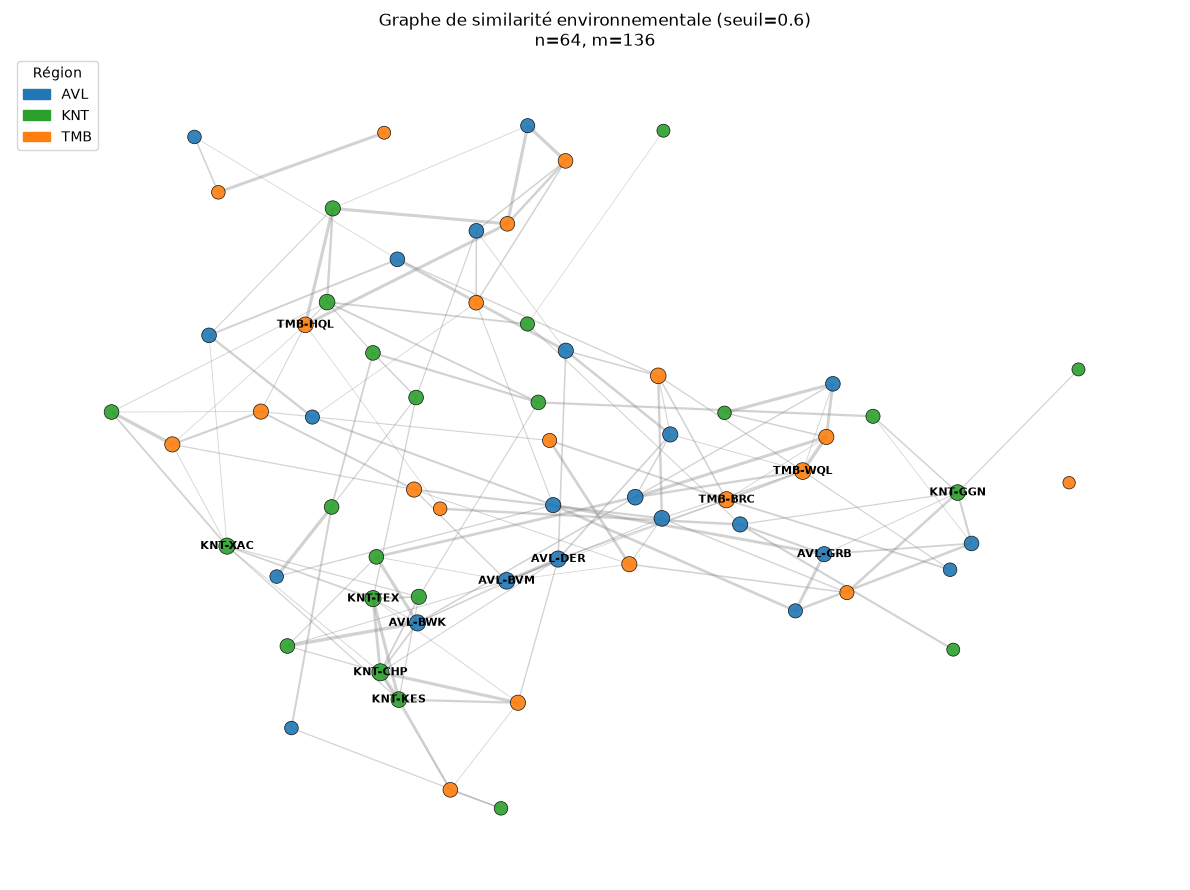

Lecture visuelle :
- Couleur = région (AVL / KNT / TMB)
- Taille du nœud ∝ degré (nombre de voisins similaires)
- Épaisseur d'arête ∝ poids (similarité)
- Lecture : regroupements régionaux / d'usage du sol éventuels


In [57]:
# Visualisation du graphe (étape 1)
region_color = {"AVL": "#1f77b4", "KNT": "#2ca02c", "TMB": "#ff7f0e"}
node_colors = [region_color.get(G.nodes[n]["region"], "grey") for n in G.nodes()]
node_sizes = [80 + 8 * G.degree(n) for n in G.nodes()]
edge_widths = [0.5 + 2.5 * (d["weight"] - SEUIL) / max(1e-6, 1 - SEUIL) for _, _, d in G.edges(data=True)]

pos = nx.spring_layout(G, weight="weight", seed=42, k=0.45)

plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.35, edge_color="grey")
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9, linewidths=0.5, edgecolors="black")

# Labels : sites clés + KNT-KES
labels = {n: n for n in G.nodes() if n in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"] or G.degree(n) >= sorted([G.degree(x) for x in G.nodes()], reverse=True)[min(7, G.number_of_nodes()-1)]}
nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, font_weight="bold")

from matplotlib.patches import Patch
legend = [Patch(color=c, label=r) for r, c in region_color.items()]
plt.legend(handles=legend, title="Région", loc="upper left")
plt.title(f"Graphe de similarité environnementale (seuil={SEUIL})\nn={G.number_of_nodes()}, m={G.number_of_edges()}")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Lecture visuelle :")
print("- Couleur = région (AVL / KNT / TMB)")
print("- Taille du nœud ∝ degré (nombre de voisins similaires)")
print("- Épaisseur d'arête ∝ poids (similarité)")
print("- Lecture : regroupements régionaux / d'usage du sol éventuels")


### - Lecture étape 1

- Graphe **non orienté pondéré** : nœuds = sites, arêtes = similarité environnementale ≥ 0.6.
- Les attributs (`region`, `land_use`, `disturbance`) serviront pour interpréter degrés et communautés aux étapes suivantes.
- **KNT-KES** est un nœud comme les autres : on pourra voir s'il est central, périphérique, ou dans une communauté « karst / normal ».

Suite : description du graphe (n, m, densité, distribution des degrés, loi de puissance).


## Étape 2 — Décrire le graphe : n, m, densité, degrés, loi de puissance

Indicateurs classiques du cours :

| Indicateur | Formule / sens |
|---|---|
| **n** | nombre de nœuds |
| **m** | nombre d'arêtes |
| **densité** | $2m / [n(n-1)]$ (graphe non orienté) — fraction des liens possibles qui existent |
| **degré** $k_i$ | nombre de voisins du nœud $i$ |
| **loi de puissance** | $P(k) \propto k^{-\gamma}$ ? → peu de hubs, beaucoup de nœuds peu connectés |

On regarde aussi le **degré moyen**, le **degré max**, les **isolés**, et un fit log-log sommaire pour juger si une loi de puissance est plausible.


In [58]:
# --- Étape 2 : description du graphe ---
import numpy as np
from collections import Counter

n = G.number_of_nodes()
m = G.number_of_edges()
densite = nx.density(G)
degrees = dict(G.degree())
deg_vals = np.array(list(degrees.values()))
n_isolates = nx.number_of_isolates(G)

print("=== Descriptifs globaux ===")
print(f"n (nœuds)           : {n}")
print(f"m (arêtes)          : {m}")
print(f"densité             : {densite:.4f}  ({100*densite:.1f} % des liens possibles)")
print(f"degré moyen         : {deg_vals.mean():.2f}")
print(f"degré médian        : {np.median(deg_vals):.1f}")
print(f"degré min / max     : {deg_vals.min()} / {deg_vals.max()}")
print(f"nœuds isolés (k=0)  : {n_isolates} → {list(nx.isolates(G))}")

print("\n=== Top 10 degrés ===")
top_deg = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:10]
for site, k in top_deg:
    print(f"  {site:10s}  k={k:2d}  region={G.nodes[site]['region']}  land_use={G.nodes[site]['land_use']}")

print("\n=== Degré de sites clés ===")
for site in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"]:
    if site in G:
        print(f"  {site}: k={G.degree(site)}  region={G.nodes[site]['region']}  land_use={G.nodes[site]['land_use']}")

# Distribution empirique P(k)
counts = Counter(deg_vals)
ks = sorted(counts)
pk = [counts[k] / n for k in ks]
print("\n=== Distribution P(k) ===")
for k, p in zip(ks, pk):
    print(f"  k={k:2d} : {counts[k]:2d} sites ({100*p:5.1f} %)")


=== Descriptifs globaux ===
n (nœuds)           : 64
m (arêtes)          : 136
densité             : 0.0675  (6.7 % des liens possibles)
degré moyen         : 4.25
degré médian        : 4.0
degré min / max     : 0 / 9
nœuds isolés (k=0)  : 1 → ['TMB-AYQ']

=== Top 10 degrés ===
  KNT-CHP     k= 9  region=KNT  land_use=karst_habitat
  AVL-BVM     k= 8  region=AVL  land_use=research_site
  TMB-WQL     k= 8  region=TMB  land_use=mixed_forest
  AVL-BWK     k= 7  region=AVL  land_use=mixed_forest
  AVL-DER     k= 7  region=AVL  land_use=mixed_forest
  KNT-TEX     k= 7  region=KNT  land_use=mixed_forest
  KNT-XAC     k= 7  region=KNT  land_use=protected_forest
  TMB-BRC     k= 7  region=TMB  land_use=durian_orchard
  AVL-FNM     k= 6  region=AVL  land_use=research_site
  AVL-HTY     k= 6  region=AVL  land_use=research_site

=== Degré de sites clés ===
  KNT-KES: k=6  region=KNT  land_use=karst_habitat
  KNT-GGN: k=6  region=KNT  land_use=degraded_land
  AVL-GRB: k=5  region=AVL  land_use=mix

Fit log-log : exposant γ ≈ 0.42 (pente = -0.42)
Rappel : un vrai réseau scale-free a souvent γ entre ~2 et 3,
         ET une droite nette sur plusieurs ordres de grandeur.


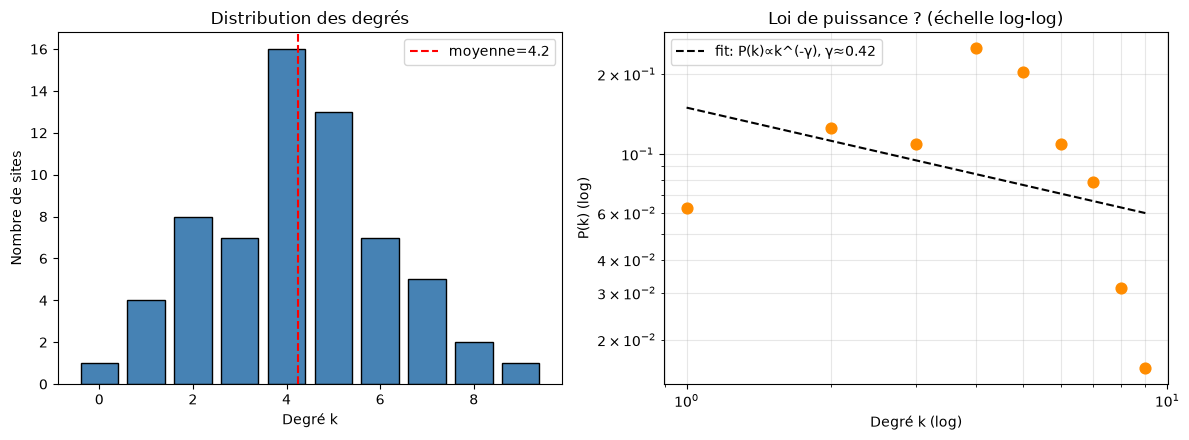


Degré moyen par région :


,mean,median,max,count
region,,,,
AVL,4.36,4.0,8,22
KNT,4.18,4.0,9,22
TMB,4.20,4.5,8,20



Degré moyen par land_use :


,mean,median,max,count
land_use,,,,
coastal_habitat,3.20,3.5,5,10
degraded_land,4.50,4.5,6,2
durian_orchard,4.30,4.0,7,10
karst_habitat,4.56,4.0,9,9
mixed_agriculture,4.00,5.0,5,5
mixed_forest,4.32,4.0,8,19
protected_forest,5.00,4.0,7,3
research_site,5.00,5.0,8,6


In [59]:
# Histogramme des degrés + test sommaire loi de puissance (log-log)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) Histogramme
axes[0].bar(ks, [counts[k] for k in ks], color="steelblue", edgecolor="black", width=0.8)
axes[0].set_xlabel("Degré k")
axes[0].set_ylabel("Nombre de sites")
axes[0].set_title("Distribution des degrés")
axes[0].axvline(deg_vals.mean(), color="red", ls="--", label=f"moyenne={deg_vals.mean():.1f}")
axes[0].legend()

# 2) Log-log : P(k) vs k (sites avec k ≥ 1)
ks_pos = np.array([k for k in ks if k >= 1])
pk_pos = np.array([counts[k] / n for k in ks_pos])
axes[1].scatter(ks_pos, pk_pos, s=60, color="darkorange", zorder=3)

# Régression linéaire log P = a + b log k  (si droite → loi de puissance plausible)
if len(ks_pos) >= 3:
    log_k = np.log(ks_pos.astype(float))
    log_p = np.log(pk_pos.astype(float))
    b, a = np.polyfit(log_k, log_p, 1)  # p ≈ C * k^b  avec b ≈ -γ
    gamma = -b
    k_line = np.linspace(ks_pos.min(), ks_pos.max(), 50)
    p_line = np.exp(a) * k_line ** b
    axes[1].plot(k_line, p_line, "k--",
                 label=f"fit: P(k)∝k^(-γ), γ≈{gamma:.2f}")
    print(f"Fit log-log : exposant γ ≈ {gamma:.2f} (pente = {b:.2f})")
    print("Rappel : un vrai réseau scale-free a souvent γ entre ~2 et 3,")
    print("         ET une droite nette sur plusieurs ordres de grandeur.")
else:
    gamma = np.nan
    print("Pas assez de degrés distincts pour un fit fiable.")

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Degré k (log)")
axes[1].set_ylabel("P(k) (log)")
axes[1].set_title("Loi de puissance ? (échelle log-log)")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# Degré moyen par région (pour l'interprétation)
deg_df = pd.DataFrame({
    "site": list(degrees.keys()),
    "degree": list(degrees.values()),
    "region": [G.nodes[s]["region"] for s in degrees],
    "land_use": [G.nodes[s]["land_use"] for s in degrees],
})
print("\nDegré moyen par région :")
display(deg_df.groupby("region")["degree"].agg(["mean", "median", "max", "count"]).round(2))
print("\nDegré moyen par land_use :")
display(deg_df.groupby("land_use")["degree"].agg(["mean", "median", "max", "count"]).round(2))


### - Lecture étape 2

- **Densité faible** (~ quelques %) : le graphe n'est pas une clique ; seuls les sites vraiment proches environnementalement sont reliés.
- **Degrés** : la plupart des sites ont un degré modéré ; quelques-uns sont plus connectés (hubs relatifs). Les **isolés** (k=0) sont des profils atypiques sous le seuil 0.6.
- **Loi de puissance** : on regarde si le nuage log-log est à peu près linéaire. Sur **64 nœuds**, un vrai régime scale-free est rarement convaincant — le fit γ est surtout **indicatif**. Si la droite est mauvaise / γ hors [2, 3] → plutôt distribution **homogène / courte queue**, pas un réseau hub-and-spoke extrême.
- **KNT-KES** : son degré (vu à l'étape 1 ≈ 6) le place dans le **cœur “normal”** du réseau, pas en isolé — cohérent avec un climat ordinaire (Bloc 3).

Suite : nœuds importants (degré, closeness, betweenness) et plus courts chemins.


## Étape 3 — Nœuds importants : degré, closeness, betweenness + plus courts chemins

Trois mesures de **centralité** (cours) :

| Mesure | Sens intuitif |
|---|---|
| **Degré** | combien de voisins directs (popularité locale) |
| **Closeness** | à quel point on est **proche** de tous les autres (1 / distance moyenne) |
| **Betweenness** | à quel point on est un **pont** sur les plus courts chemins entre les autres |

Puis : **plus courts chemins** entre sites clés (ex. `KNT-KES` ↔ hubs / autres régions).

> Sur graphe **pondéré**, pour les distances on utilise souvent `distance = 1 − weight` (similarité haute → distance basse). Les isolés sont exclus des mesures qui exigent une composante connexe.


In [60]:
# --- Étape 3 : centralités ---
# Sous-graphe de la plus grande composante connexe (closeness / betweenness)
composantes = sorted(nx.connected_components(G), key=len, reverse=True)
G_cc = G.subgraph(composantes[0]).copy()
print(f"Composante principale : {G_cc.number_of_nodes()} nœuds / {G.number_of_nodes()}")
print(f"Autres composantes    : {len(composantes) - 1} (tailles {[len(c) for c in composantes[1:]]})")

# Distance = 1 - similarité (arête forte → chemin court)
for u, v, d in G_cc.edges(data=True):
    d["distance"] = 1.0 - d["weight"]

deg_c = dict(G_cc.degree())
close_c = nx.closeness_centrality(G_cc, distance="distance")
betw_c = nx.betweenness_centrality(G_cc, weight="distance", normalized=True)

cent = pd.DataFrame({
    "degree": pd.Series(deg_c),
    "closeness": pd.Series(close_c),
    "betweenness": pd.Series(betw_c),
    "region": pd.Series({n: G_cc.nodes[n]["region"] for n in G_cc.nodes()}),
    "land_use": pd.Series({n: G_cc.nodes[n]["land_use"] for n in G_cc.nodes()}),
}).sort_values("betweenness", ascending=False)

print("\n=== Top 8 betweenness (ponts) ===")
display(cent.head(8).round(4))
print("\n=== Top 8 closeness (centrales / proches de tous) ===")
display(cent.sort_values("closeness", ascending=False).head(8).round(4))
print("\n=== Top 8 degree ===")
display(cent.sort_values("degree", ascending=False).head(8).round(4))

print("\n=== Sites clés ===")
for site in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"]:
    if site in cent.index:
        row = cent.loc[site]
        print(f"{site}: deg={row['degree']:.0f}  close={row['closeness']:.3f}  "
              f"betw={row['betweenness']:.3f}  | rang betw=#{cent.index.get_loc(site)+1}")
    else:
        print(f"{site}: hors composante principale (isolé / petite composante)")


Composante principale : 63 nœuds / 64
Autres composantes    : 1 (tailles [1])

=== Top 8 betweenness (ponts) ===


,degree,closeness,betweenness,region,land_use
AVL-ABG,4,1.1704,0.1423,AVL,mixed_forest
KNT-GGN,6,1.0633,0.1269,KNT,degraded_land
AVL-YAU,4,1.2103,0.1227,AVL,durian_orchard
KNT-CHP,9,1.1331,0.1137,KNT,karst_habitat
AVL-FNM,6,1.1612,0.1063,AVL,research_site
TMB-WST,3,1.0523,0.1015,TMB,coastal_habitat
AVL-FNQ,5,1.0331,0.0978,AVL,mixed_agriculture
KNT-QWU,6,1.0956,0.0978,KNT,karst_habitat



=== Top 8 closeness (centrales / proches de tous) ===


,degree,closeness,betweenness,region,land_use
AVL-YAU,4,1.2103,0.1227,AVL,durian_orchard
AVL-NMQ,5,1.1770,0.0883,AVL,durian_orchard
AVL-ABG,4,1.1704,0.1423,AVL,mixed_forest
AVL-FNM,6,1.1612,0.1063,AVL,research_site
AVL-DER,7,1.1534,0.0793,AVL,mixed_forest
KNT-CHP,9,1.1331,0.1137,KNT,karst_habitat
AVL-BVM,8,1.1259,0.0471,AVL,research_site
KNT-TEX,7,1.1185,0.0624,KNT,mixed_forest



=== Top 8 degree ===


,degree,closeness,betweenness,region,land_use
KNT-CHP,9,1.1331,0.1137,KNT,karst_habitat
TMB-WQL,8,1.0292,0.0762,TMB,mixed_forest
AVL-BVM,8,1.1259,0.0471,AVL,research_site
KNT-TEX,7,1.1185,0.0624,KNT,mixed_forest
KNT-XAC,7,1.1168,0.0529,KNT,protected_forest
AVL-BWK,7,1.0210,0.0619,AVL,mixed_forest
AVL-DER,7,1.1534,0.0793,AVL,mixed_forest
TMB-BRC,7,1.0463,0.0524,TMB,durian_orchard



=== Sites clés ===
KNT-KES: deg=6  close=1.088  betw=0.050  | rang betw=#28
KNT-GGN: deg=6  close=1.063  betw=0.127  | rang betw=#2
AVL-GRB: deg=5  close=1.008  betw=0.059  | rang betw=#24
TMB-HQL: deg=6  close=1.095  betw=0.069  | rang betw=#16


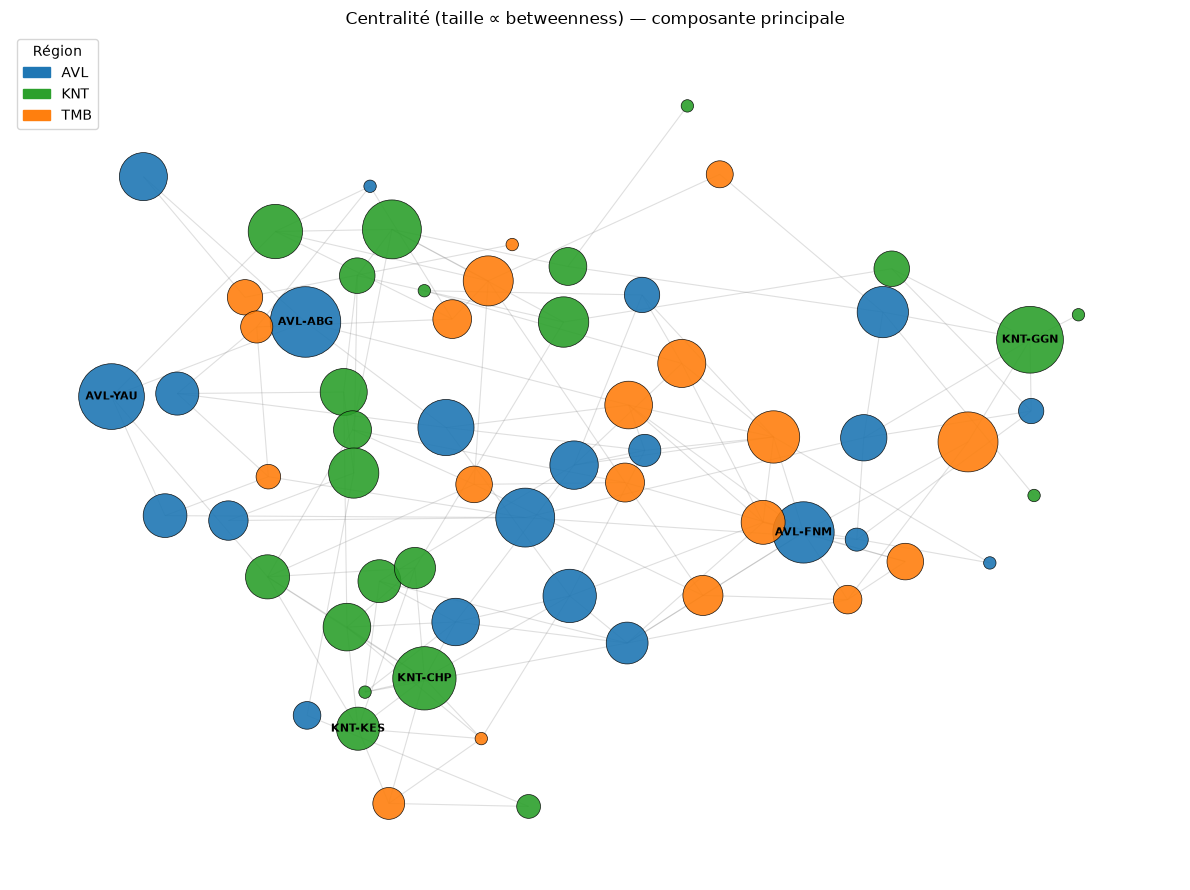

In [61]:
# Visualisation : taille ∝ betweenness, couleur = région
pos3 = nx.spring_layout(G_cc, weight="weight", seed=42, k=0.5)
betw_vals = np.array([betw_c[n] for n in G_cc.nodes()])
sizes = 80 + 2500 * (betw_vals / max(betw_vals.max(), 1e-9))
region_color = {"AVL": "#1f77b4", "KNT": "#2ca02c", "TMB": "#ff7f0e"}
colors = [region_color[G_cc.nodes[n]["region"]] for n in G_cc.nodes()]

plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G_cc, pos3, alpha=0.25, width=0.8, edge_color="grey")
nx.draw_networkx_nodes(G_cc, pos3, node_color=colors, node_size=sizes,
                       alpha=0.9, linewidths=0.5, edgecolors="black")
# Labels : top betweenness + KNT-KES
top_b = list(cent.head(5).index)
labels = {n: n for n in G_cc.nodes() if n in top_b or n == "KNT-KES"}
nx.draw_networkx_labels(G_cc, pos3, labels=labels, font_size=8, font_weight="bold")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=r) for r, c in region_color.items()],
           title="Région", loc="upper left")
plt.title("Centralité (taille ∝ betweenness) — composante principale")
plt.axis("off")
plt.tight_layout()
plt.show()


In [62]:
# Plus courts chemins entre sites d'intérêt
pairs = [
    ("KNT-KES", "KNT-GGN"),   # même région, profils potentiellement différents
    ("KNT-KES", "AVL-GRB"),   # cross-région
    ("KNT-KES", "TMB-HQL"),   # cross-région (TMB-HQL = piste LOF Bloc 3)
    ("KNT-CHP", "AVL-BVM"),   # deux hubs de degré
]

print("=== Plus courts chemins (distance = 1 − similarité) ===\n")
for src, dst in pairs:
    if src not in G_cc or dst not in G_cc:
        print(f"{src} → {dst} : un des deux hors composante\n")
        continue
    try:
        path = nx.shortest_path(G_cc, src, dst, weight="distance")
        length = nx.shortest_path_length(G_cc, src, dst, weight="distance")
        # similarités le long du chemin
        hops = []
        for a, b in zip(path[:-1], path[1:]):
            hops.append(f"{a}—{b} (w={G_cc[a][b]['weight']:.2f})")
        print(f"{src} → {dst}")
        print(f"  longueur = {length:.3f} | {len(path)-1} saut(s)")
        print(f"  chemin   = {' → '.join(path)}")
        print(f"  arêtes   = {', '.join(hops)}")
        print()
    except nx.NetworkXNoPath:
        print(f"{src} → {dst} : pas de chemin\n")

# Distances moyennes depuis KNT-KES
if "KNT-KES" in G_cc:
    lengths = nx.single_source_dijkstra_path_length(G_cc, "KNT-KES", weight="distance")
    dist_df = pd.Series(lengths).sort_values()
    print("Depuis KNT-KES — 5 sites les plus proches (distance) :")
    display(dist_df.head(6).to_frame("distance").round(3))  # inclut lui-même à 0
    print("\n5 sites les plus loin :")
    display(dist_df.tail(5).to_frame("distance").round(3))


=== Plus courts chemins (distance = 1 − similarité) ===

KNT-KES → KNT-GGN
  longueur = 1.219 | 4 saut(s)
  chemin   = KNT-KES → KNT-VLB → KNT-JQG → KNT-YRX → KNT-GGN
  arêtes   = KNT-KES—KNT-VLB (w=0.66), KNT-VLB—KNT-JQG (w=0.65), KNT-JQG—KNT-YRX (w=0.78), KNT-YRX—KNT-GGN (w=0.69)

KNT-KES → AVL-GRB
  longueur = 1.324 | 5 saut(s)
  chemin   = KNT-KES → KNT-XAC → AVL-YAU → AVL-KAR → AVL-FNQ → AVL-GRB
  arêtes   = KNT-KES—KNT-XAC (w=0.66), KNT-XAC—AVL-YAU (w=0.61), AVL-YAU—AVL-KAR (w=0.79), AVL-KAR—AVL-FNQ (w=0.76), AVL-FNQ—AVL-GRB (w=0.86)

KNT-KES → TMB-HQL
  longueur = 1.101 | 4 saut(s)
  chemin   = KNT-KES → KNT-XAC → KNT-SEN → TMB-GZX → TMB-HQL
  arêtes   = KNT-KES—KNT-XAC (w=0.66), KNT-XAC—KNT-SEN (w=0.73), KNT-SEN—TMB-GZX (w=0.90), TMB-GZX—TMB-HQL (w=0.60)

KNT-CHP → AVL-BVM
  longueur = 0.497 | 2 saut(s)
  chemin   = KNT-CHP → AVL-DER → AVL-BVM
  arêtes   = KNT-CHP—AVL-DER (w=0.64), AVL-DER—AVL-BVM (w=0.86)

Depuis KNT-KES — 5 sites les plus proches (distance) :


,distance
KNT-KES,0.000
KNT-CHP,0.094
KNT-TEX,0.130
TMB-HVD,0.217
TMB-QCB,0.221
KNT-VLB,0.337



5 sites les plus loin :


,distance
KNT-DMJ,1.557
TMB-HFR,1.589
KNT-UJJ,1.614
TMB-SXP,1.723
KNT-LUM,1.792


### - Lecture étape 3

- **Degré élevé** = site au profil “typique” de plusieurs autres (beaucoup de voisins similaires).
- **Closeness élevée** = facile d'atteindre le reste du réseau via des chaînes de similarité.
- **Betweenness élevée** = **pont** entre groupes (ex. entre régions ou entre usages du sol) — nœud structurellement important.
- **Plus courts chemins** : une distance faible `KNT-KES` ↔ voisins karst / région = profil environnemental **ordinaire** dans son voisinage ; un chemin long vers un site très perturbé = régimes différents.
- Si `KNT-KES` n'est **pas** top betweenness / pas isolé → il n'est pas un “hub anomal” du réseau climatique — cohérent avec l'innocence environnementale du Bloc 3.

Suite : communautés (composantes, clustering coefficient, Louvain, Girvan-Newman, Infomap, modularité Q).


## Étape 4 — Communautés : composantes, clustering, Louvain, Girvan-Newman, Infomap (Q)

Objectif : trouver des **groupes de sites** densément reliés entre eux (même “famille” environnementale).

| Outil | Rôle |
|---|---|
| **Composantes connexes** | parties du graphe déjà séparées (pas de chemin entre elles) |
| **Coefficient de regroupement** (clustering) | mes voisins sont-ils aussi voisins entre eux ? (triangles) |
| **Louvain** | communautés par optimisation de la **modularité Q** |
| **Girvan-Newman** | retire les arêtes à forte betweenness → scinde le graphe |
| **Infomap** | compression des marches aléatoires (flux d'information) |
| **Modularité Q** | qualité d'une partition (plus Q est haut, mieux les communautés sont séparées ; Q≈0 = aléatoire) |


In [63]:
# --- Étape 4a : composantes connexes + coefficient de clustering ---
composantes = sorted(nx.connected_components(G), key=len, reverse=True)
print("=== Composantes connexes ===")
print(f"Nombre : {len(composantes)}")
for i, c in enumerate(composantes):
    print(f"  C{i}: taille={len(c)}  ex={sorted(list(c))[:5]}")

# Clustering sur la composante principale G_cc (déjà créée à l'étape 3)
if "G_cc" not in dir() or G_cc.number_of_nodes() == 0:
    G_cc = G.subgraph(composantes[0]).copy()
    for u, v, d in G_cc.edges(data=True):
        d["distance"] = 1.0 - d["weight"]

C_global = nx.average_clustering(G_cc, weight="weight")
C_local = nx.clustering(G_cc, weight="weight")
print(f"\n=== Clustering coefficient (pondéré) ===")
print(f"C moyen (composante principale) : {C_global:.3f}")
print("Top 8 C local :")
for site, cval in sorted(C_local.items(), key=lambda x: -x[1])[:8]:
    print(f"  {site}: C={cval:.3f}  region={G_cc.nodes[site]['region']}  land_use={G_cc.nodes[site]['land_use']}")
print("Sites clés :")
for site in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"]:
    if site in C_local:
        print(f"  {site}: C={C_local[site]:.3f}")


=== Composantes connexes ===
Nombre : 2
  C0: taille=63  ex=['AVL-ABG', 'AVL-ARU', 'AVL-BVM', 'AVL-BWK', 'AVL-DER']
  C1: taille=1  ex=['TMB-AYQ']

=== Clustering coefficient (pondéré) ===
C moyen (composante principale) : 0.253
Top 8 C local :
  KNT-JAK: C=0.879  region=KNT  land_use=karst_habitat
  AVL-ORR: C=0.796  region=AVL  land_use=research_site
  AVL-HUA: C=0.602  region=AVL  land_use=mixed_agriculture
  AVL-MAR: C=0.600  region=AVL  land_use=durian_orchard
  AVL-RNY: C=0.561  region=AVL  land_use=research_site
  KNT-KES: C=0.555  region=KNT  land_use=karst_habitat
  KNT-TLQ: C=0.538  region=KNT  land_use=mixed_forest
  KNT-CYP: C=0.533  region=KNT  land_use=karst_habitat
Sites clés :
  KNT-KES: C=0.555
  KNT-GGN: C=0.152
  AVL-GRB: C=0.333
  TMB-HQL: C=0.169


In [64]:
# --- Étape 4b : Louvain + modularité Q ---
louvain_sets = nx.community.louvain_communities(G_cc, weight="weight", seed=42)
louvain_part = {n: i for i, comm in enumerate(louvain_sets) for n in comm}
Q_louvain = nx.community.modularity(G_cc, louvain_sets, weight="weight")

print("=== Louvain ===")
print(f"Nb communautés : {len(louvain_sets)}")
print(f"Modularité Q   : {Q_louvain:.3f}")
for i, comm in enumerate(sorted(louvain_sets, key=len, reverse=True)):
    regs = pd.Series([G_cc.nodes[n]["region"] for n in comm]).value_counts().to_dict()
    uses = pd.Series([G_cc.nodes[n]["land_use"] for n in comm]).value_counts().head(3).to_dict()
    print(f"  L{i}: n={len(comm):2d}  régions={regs}  top land_use={uses}")
    if "KNT-KES" in comm:
        print(f"       → contient KNT-KES")
    if "KNT-GGN" in comm:
        print(f"       → contient KNT-GGN")


=== Louvain ===
Nb communautés : 7
Modularité Q   : 0.578
  L0: n=12  régions={'KNT': 7, 'AVL': 3, 'TMB': 2}  top land_use={'mixed_forest': 7, 'karst_habitat': 3, 'protected_forest': 1}
       → contient KNT-KES
  L1: n=11  régions={'AVL': 6, 'TMB': 4, 'KNT': 1}  top land_use={'durian_orchard': 3, 'mixed_forest': 3, 'research_site': 3}
  L2: n=10  régions={'AVL': 4, 'TMB': 4, 'KNT': 2}  top land_use={'durian_orchard': 6, 'karst_habitat': 2, 'coastal_habitat': 2}
  L3: n=10  régions={'AVL': 5, 'KNT': 4, 'TMB': 1}  top land_use={'mixed_agriculture': 4, 'mixed_forest': 2, 'research_site': 1}
       → contient KNT-GGN
  L4: n= 9  régions={'KNT': 7, 'AVL': 2}  top land_use={'mixed_forest': 4, 'protected_forest': 2, 'karst_habitat': 1}
  L5: n= 8  régions={'TMB': 6, 'KNT': 1, 'AVL': 1}  top land_use={'coastal_habitat': 4, 'mixed_forest': 2, 'karst_habitat': 1}
  L6: n= 3  régions={'TMB': 2, 'AVL': 1}  top land_use={'coastal_habitat': 1, 'durian_orchard': 1, 'mixed_forest': 1}


In [65]:
# --- Étape 4c : Girvan-Newman (on garde la partition à meilleure Q) ---
# Sur ~63 nœuds : on itère jusqu'à avoir entre 2 et 8 communautés
gn_gen = nx.community.girvan_newman(G_cc)
best_Q, best_part, best_k = -1, None, None
historique = []
for k_target in range(2, 9):
    partition = next(gn_gen)  # tuple de frozensets
    Q = nx.community.modularity(G_cc, partition, weight="weight")
    historique.append((len(partition), Q))
    if Q > best_Q:
        best_Q, best_part, best_k = Q, partition, len(partition)

print("=== Girvan-Newman ===")
print("Q selon le nb de communautés :", {k: round(q, 3) for k, q in historique})
print(f"Meilleure partition : k={best_k}, Q={best_Q:.3f}")
for i, comm in enumerate(sorted(best_part, key=len, reverse=True)):
    regs = pd.Series([G_cc.nodes[n]["region"] for n in comm]).value_counts().to_dict()
    print(f"  GN{i}: n={len(comm):2d}  régions={regs}")
    if "KNT-KES" in comm:
        print(f"        → KNT-KES")
    if "KNT-GGN" in comm:
        print(f"        → KNT-GGN")

gn_part = {n: i for i, comm in enumerate(best_part) for n in comm}


=== Girvan-Newman ===
Q selon le nb de communautés : {2: 0.405, 3: 0.479, 4: 0.488, 5: 0.549, 6: 0.562, 7: 0.561, 8: 0.558}
Meilleure partition : k=6, Q=0.562
  GN0: n=16  régions={'AVL': 6, 'KNT': 6, 'TMB': 4}
  GN1: n=15  régions={'AVL': 8, 'TMB': 4, 'KNT': 3}
  GN2: n=11  régions={'KNT': 6, 'AVL': 4, 'TMB': 1}
        → KNT-GGN
  GN3: n=11  régions={'KNT': 7, 'TMB': 3, 'AVL': 1}
        → KNT-KES
  GN4: n= 7  régions={'TMB': 5, 'AVL': 2}
  GN5: n= 3  régions={'TMB': 2, 'AVL': 1}


In [66]:
# --- Étape 4d : Infomap ---
from infomap import Infomap

# Infomap travaille mieux avec des ids entiers
node_ids = {n: i for i, n in enumerate(G_cc.nodes())}
id_nodes = {i: n for n, i in node_ids.items()}

im = Infomap(silent=True, num_trials=10)
for n, i in node_ids.items():
    im.add_node(i, name=n)
for u, v, d in G_cc.edges(data=True):
    im.add_link(node_ids[u], node_ids[v], d["weight"])
im.run()

infomap_sets_dict = {}
for node in im.nodes:
    infomap_sets_dict.setdefault(node.module_id, set()).add(id_nodes[node.node_id])
infomap_sets = list(infomap_sets_dict.values())
Q_infomap = nx.community.modularity(G_cc, infomap_sets, weight="weight")

print("=== Infomap ===")
print(f"Nb modules : {len(infomap_sets)}")
print(f"Modularité Q (mesurée NetworkX) : {Q_infomap:.3f}")
for i, comm in enumerate(sorted(infomap_sets, key=len, reverse=True)):
    regs = pd.Series([G_cc.nodes[n]["region"] for n in comm]).value_counts().to_dict()
    print(f"  IM{i}: n={len(comm):2d}  régions={regs}")
    if "KNT-KES" in comm:
        print(f"        → KNT-KES")
    if "KNT-GGN" in comm:
        print(f"        → KNT-GGN")

infomap_part = {n: i for i, comm in enumerate(infomap_sets) for n in comm}


=== Infomap ===
Nb modules : 10
Modularité Q (mesurée NetworkX) : 0.566
  IM0: n= 8  régions={'TMB': 6, 'KNT': 1, 'AVL': 1}
  IM1: n= 8  régions={'KNT': 6, 'AVL': 2}
  IM2: n= 7  régions={'AVL': 4, 'KNT': 3}
        → KNT-GGN
  IM3: n= 7  régions={'TMB': 4, 'AVL': 2, 'KNT': 1}
  IM4: n= 7  régions={'TMB': 3, 'AVL': 3, 'KNT': 1}
  IM5: n= 7  régions={'KNT': 5, 'TMB': 2}
        → KNT-KES
  IM6: n= 6  régions={'AVL': 5, 'TMB': 1}
  IM7: n= 5  régions={'AVL': 3, 'KNT': 2}
  IM8: n= 5  régions={'KNT': 3, 'AVL': 1, 'TMB': 1}
  IM9: n= 3  régions={'TMB': 2, 'AVL': 1}


=== Modularités Q comparées ===
Louvain        : Q = 0.578  (k=7)
Girvan-Newman  : Q = 0.562  (k=6)
Infomap        : Q = 0.566  (k=10)

Louvain × région :


attr,AVL,KNT,TMB
comm,,,
0,3,7,2
1,4,2,4
2,5,4,1
3,6,1,4
4,1,1,6
5,2,7,0
6,1,0,2


Louvain × land_use :


attr,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
comm,,,,,,,,
0,0,0,0,3,0,7,1,1
1,2,0,6,2,0,0,0,0
2,1,1,0,1,4,2,0,1
3,1,0,3,1,0,3,0,3
4,4,0,0,1,0,2,0,1
5,0,1,0,1,1,4,2,0
6,1,0,1,0,0,1,0,0


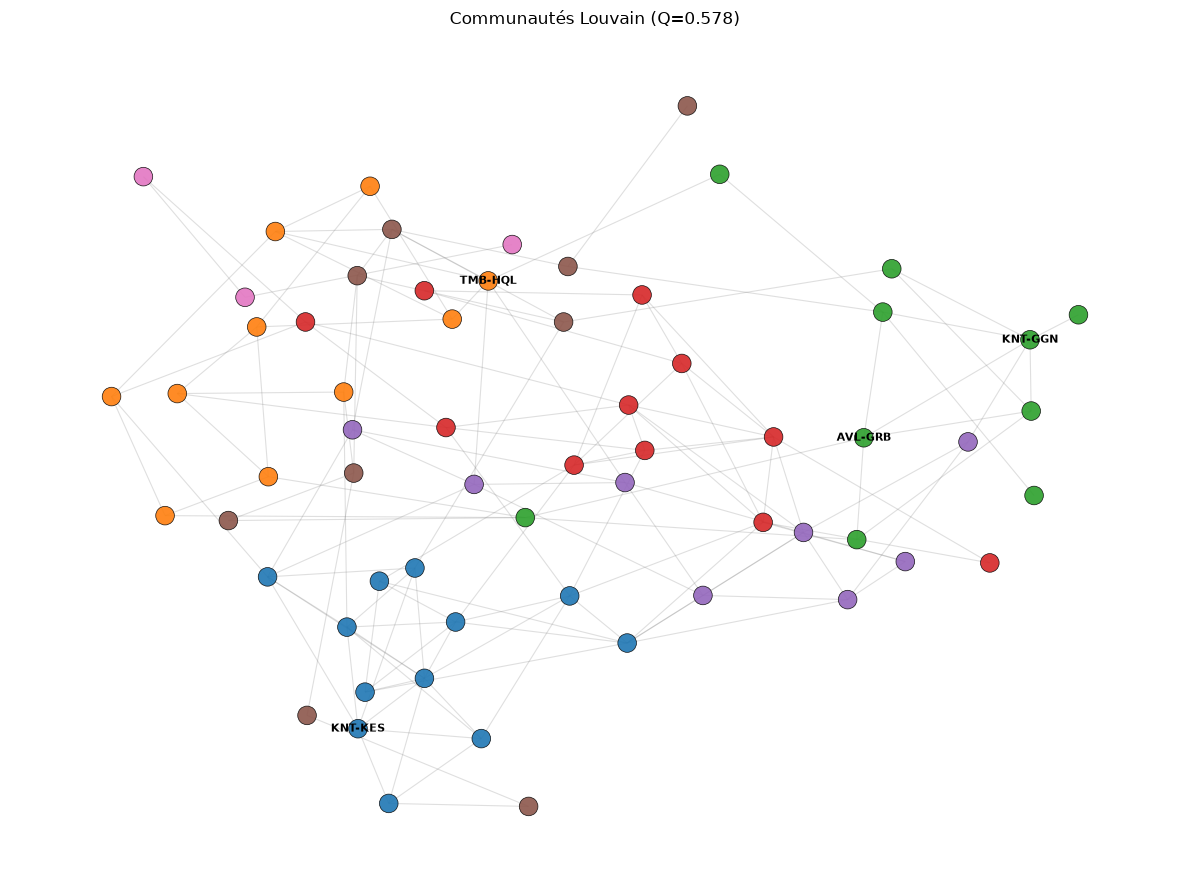

KNT-KES et KNT-GGN dans la MÊME communauté Louvain ? False
  KNT-KES → L0
  KNT-GGN → L2


In [67]:
# --- Comparaison des partitions + visualisation Louvain ---
# Recalcule ce qui manque si une cellule précédente n'a pas été exécutée

def contingency(part_dict, attr):
    rows = [{"comm": cid, "attr": G_cc.nodes[n][attr]} for n, cid in part_dict.items()]
    return pd.crosstab(pd.DataFrame(rows)["comm"], pd.DataFrame(rows)["attr"])

# --- Louvain ---
if "Q_louvain" not in globals() or "louvain_sets" not in globals():
    louvain_sets = nx.community.louvain_communities(G_cc, weight="weight", seed=42)
    Q_louvain = nx.community.modularity(G_cc, louvain_sets, weight="weight")
    print("(Louvain recalculé dans cette cellule)")
louvain_part = {n: i for i, comm in enumerate(louvain_sets) for n in comm}

# --- Girvan-Newman ---
if "best_Q" not in globals() or "best_part" not in globals() or "best_k" not in globals():
    gn_gen = nx.community.girvan_newman(G_cc)
    best_Q, best_part, best_k = -1, None, None
    for _ in range(2, 9):
        partition = next(gn_gen)
        Q = nx.community.modularity(G_cc, partition, weight="weight")
        if Q > best_Q:
            best_Q, best_part, best_k = Q, partition, len(partition)
    print("(Girvan-Newman recalculé dans cette cellule)")

# --- Infomap ---
if "Q_infomap" not in globals() or "infomap_sets" not in globals():
    from infomap import Infomap
    node_ids = {n: i for i, n in enumerate(G_cc.nodes())}
    id_nodes = {i: n for n, i in node_ids.items()}
    im = Infomap(silent=True, num_trials=10)
    for n, i in node_ids.items():
        im.add_node(i, name=n)
    for u, v, d in G_cc.edges(data=True):
        im.add_link(node_ids[u], node_ids[v], d["weight"])
    im.run()
    infomap_sets_dict = {}
    for node in im.nodes:
        infomap_sets_dict.setdefault(node.module_id, set()).add(id_nodes[node.node_id])
    infomap_sets = list(infomap_sets_dict.values())
    Q_infomap = nx.community.modularity(G_cc, infomap_sets, weight="weight")
    print("(Infomap recalculé)")

print("=== Modularités Q comparées ===")
print(f"Louvain        : Q = {Q_louvain:.3f}  (k={len(louvain_sets)})")
print(f"Girvan-Newman  : Q = {best_Q:.3f}  (k={best_k})")
print(f"Infomap        : Q = {Q_infomap:.3f}  (k={len(infomap_sets)})")

print("\nLouvain × région :")
display(contingency(louvain_part, "region"))
print("Louvain × land_use :")
display(contingency(louvain_part, "land_use"))

# Dessin Louvain
pos4 = nx.spring_layout(G_cc, weight="weight", seed=42, k=0.5)
cmap = plt.cm.tab10
colors = [cmap(louvain_part[n] % 10) for n in G_cc.nodes()]

plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G_cc, pos4, alpha=0.25, width=0.8, edge_color="grey")
nx.draw_networkx_nodes(G_cc, pos4, node_color=colors, node_size=180,
                       alpha=0.9, linewidths=0.5, edgecolors="black")
labels = {n: n for n in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"] if n in G_cc}
nx.draw_networkx_labels(G_cc, pos4, labels=labels, font_size=8, font_weight="bold")
plt.title(f"Communautés Louvain (Q={Q_louvain:.3f})")
plt.axis("off")
plt.tight_layout()
plt.show()

same = louvain_part.get("KNT-KES") == louvain_part.get("KNT-GGN")
print(f"KNT-KES et KNT-GGN dans la MÊME communauté Louvain ? {same}")
print(f"  KNT-KES → L{louvain_part.get('KNT-KES')}")
print(f"  KNT-GGN → L{louvain_part.get('KNT-GGN')}")


### - Lecture étape 4

- **Composantes** : presque tout le graphe est d'un seul tenant (1 isolé) → la structure intéressante est **à l'intérieur** (communautés), pas la séparation totale.
- **Clustering coefficient** : s'il est élevé, les voisins d'un site se ressemblent aussi entre eux (triangles / “cliques” locales).
- **Louvain / GN / Infomap** : on compare surtout via **Q**. Un Q nettement > 0 indique des groupes réels. On vérifie s'ils collent aux **régions** (AVL/KNT/TMB) et/ou aux **land_use** (ex. sites perturbés vs forêts).
- **KNT-KES vs KNT-GGN** : s'ils sont dans des communautés **différentes**, ça confirme l'étape 3 (chemin long) — même préfixe KNT, **régimes environnementaux distincts**.
- Infomap optimise un critère de *flux* (pas Q) ; on reporte quand même Q NetworkX pour comparer les partitions sur la même échelle.

Suite : process mining — ce fichier **n'est pas** un event log.


## Étape 5 — Process mining (Heuristic / Inductive / Fuzzy Miner, pm4py)

Le cours demande d'appliquer le **process mining** (Heuristic Miner, Inductive Miner, Fuzzy Miner via `pm4py`) **uniquement sur des event logs**.

### Pourquoi on ne le fait PAS sur `environmental_monthly`

Un event log au sens process mining a typiquement :

| Champ requis | Rôle | Présent ici ? |
|---|---|---|
| **case_id** | identifiant d'une instance de processus (un “dossier”) | Non |
| **activity** | étape / événement du processus | Non |
| **timestamp** | instant de l'événement | Seulement `reporting_month` (agrégat mensuel, pas un flux d'événements) |
| enchaînement d'activités | A → B → C pour un même case | Non |

`environmental_monthly` = **relevés climatiques mensuels par site** (une ligne = site × mois × mesures).  
Ce n'est **pas** un journal d'événements de processus (pas de workflow, pas d'activités ordonnées).

→ **Décision :** pas d'Heuristic / Inductive / Fuzzy Miner sur ce fichier.  
Le process mining (pm4py) est **hors périmètre** ici : `environmental_monthly` n'est pas un event log.


In [68]:
# Vérification rapide : ce fichier n'a pas la structure d'un event log
print("=== Contrôle event-log sur environmental_monthly ===")
print("Colonnes disponibles :")
print(sorted(df_env.columns.tolist()) if "df_env" in globals() else sorted(
    pd.read_csv("cleaned/environmental_monthly_clean.csv", nrows=0).columns.tolist()
))

requis = ["case_id", "case:concept:name", "concept:name", "activity", "time:timestamp"]
cols = set(df_env.columns) if "df_env" in globals() else set(
    pd.read_csv("cleaned/environmental_monthly_clean.csv", nrows=0).columns
)
print("\nChamps process-mining typiques présents ?")
for c in requis:
    print(f"  {c:22s} : {'OUI' if c in cols else 'NON'}")

print("\nVerdict : PAS un event log → pas de Heuristic / Inductive / Fuzzy Miner (pm4py) sur ce notebook.")
print("Process mining hors périmètre sur environmental_monthly.")


=== Contrôle event-log sur environmental_monthly ===
Colonnes disponibles :
['data_completeness_pct', 'habitat_disturbance_index', 'land_use_category', 'mean_humidity_pct', 'mean_temperature_c', 'month', 'pesticide_index', 'rainfall_mm', 'region', 'reporting_month', 'site_code', 'vegetation_cover_pct', 'weather_exception_code', 'year']

Champs process-mining typiques présents ?
  case_id                : NON
  case:concept:name      : NON
  concept:name           : NON
  activity               : NON
  time:timestamp         : NON

Verdict : PAS un event log → pas de Heuristic / Inductive / Fuzzy Miner (pm4py) sur ce notebook.
Process mining hors périmètre sur environmental_monthly.


### - Bilan Bloc 4 (`environmental_monthly`)

| Étape | Résultat |
|---|---|
| 1. Définition | Graphe **non orienté pondéré** : sites ↔ similarité environnementale (seuil 0.6) |
| 2. Description | n=64, m=136, densité ≈ 6.7 %, degrés homogènes, **pas** de loi de puissance |
| 3. Centralités | `KNT-KES` connecté mais **peu central** ; `KNT-GGN` = pont (betweenness haute) |
| 4. Communautés | Louvain Q≈0.58 ; **KES et GGN dans des communautés différentes** |
| 5. Process mining | **Non applicable** — fichier ≠ event log |

**Lecture enquête :** le réseau confirme un `KNT-KES` environnementalement **ordinaire**, séparé des profils perturbés type `KNT-GGN` → renforce l'innocence climatique face au crash bats.


# 15. Bloc 5 : données spatiales et temporelles (Cours 5)

Deux volets :
1. **Spatial** — localiser les sites, carte, autocorrélation spatiale (Moran / LISA), Voronoi
2. **Temporel** — séries mensuelles, tendance / saisonnalité, ACF, STL, anomalies fenêtre glissante

> **Géographie fictive** : les coordonnées viennent de `monitoring_sites` (pays inventés). On les utilise pour la structure spatiale du réseau de monitoring, **sans** les interpréter comme un vrai pays du monde.


## A. Spatial

### A.1 Localiser les variables spatiales

| Type | Dans `environmental_monthly` | Enrichissement |
|---|---|---|
| **Coordonnées** | absentes | jointure `monitoring_sites` → `latitude`, `longitude` (**64/64** sites) |
| **Localisation indirecte** | `site_code` (préfixe = région AVL/KNT/TMB) | `region`, `jurisdiction` via `monitoring_sites` |

Contrairement à un jeu avec seulement 3 points GPS : ici **64 sites géolocalisés** → Moran / LISA / Voronoi sont **pertinents**.


In [69]:
# --- A.1 Jointure spatiale ---
df_env = pd.read_csv("cleaned/environmental_monthly_clean.csv")
df_env["reporting_month"] = pd.to_datetime(df_env["reporting_month"])
df_env["region_code"] = df_env["site_code"].str[:3]

sites = pd.read_csv("cleaned/monitoring_sites_cleaned.csv")
sites_geo = sites[["site_code", "site_name", "region", "jurisdiction",
                   "latitude", "longitude", "elevation_m", "habitat_category"]].copy()

# Profil moyen par site (pour la carte / Moran)
cols_num = ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct",
            "vegetation_cover_pct", "habitat_disturbance_index", "pesticide_index"]
profil = df_env.groupby("site_code")[cols_num].mean().reset_index()
profil = profil.merge(sites_geo, on="site_code", how="left")
profil["region_code"] = profil["site_code"].str[:3]

print("Sites avec lat/lon :", profil[["latitude", "longitude"]].notna().all(axis=1).sum(), "/", len(profil))
print("\nAgrégation indirecte — effectifs par région (monitoring_sites) :")
display(profil["region"].value_counts().to_frame("n_sites"))
print("\nAgrégation — effectifs par jurisdiction :")
display(profil["jurisdiction"].value_counts().to_frame("n_sites"))
print("\nMoyennes environnementales par région_code :")
display(profil.groupby("region_code")[cols_num].mean().round(1))
display(profil.head(3))


Sites avec lat/lon : 64 / 64

Agrégation indirecte — effectifs par région (monitoring_sites) :


,n_sites
region,
Eastern Avelora Agricultural Cluster,22
Kintara Karst Cluster,22
Tembara Coastal Cluster,20



Agrégation — effectifs par jurisdiction :


,n_sites
jurisdiction,
Avelora Federation,22
Kintara Republic,22
Tembara Commonwealth,20



Moyennes environnementales par région_code :


,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index
region_code,,,,,,
AVL,26.6,155.7,74.6,58.6,31.4,30.8
KNT,25.5,159.0,76.9,60.0,31.9,23.4
TMB,27.0,165.4,76.1,64.8,27.5,20.5


,site_code,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,site_name,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,region_code
0,AVL-ABG,27.249615,160.816667,74.519231,65.596154,13.261538,34.671795,Zephyr Reach Monitoring Site,Eastern Avelora Agricultural Cluster,Avelora Federation,7.7413,102.0571,206.6,mixed_forest,AVL
1,AVL-ARU,26.226923,142.935897,77.205128,50.646154,49.932051,31.503846,Quartz Coast Monitoring Site,Eastern Avelora Agricultural Cluster,Avelora Federation,7.7240,101.4303,314.3,research_site,AVL
2,AVL-BVM,27.145000,154.080769,76.871795,67.982051,20.157692,9.375641,Vireo Cavern Monitoring Site,Eastern Avelora Agricultural Cluster,Avelora Federation,7.5208,101.8087,101.9,research_site,AVL


### A.2 Carte des sites (taille ∝ variable)

Nuage lon/lat : taille du point ∝ `habitat_disturbance_index` moyen, couleur = région.


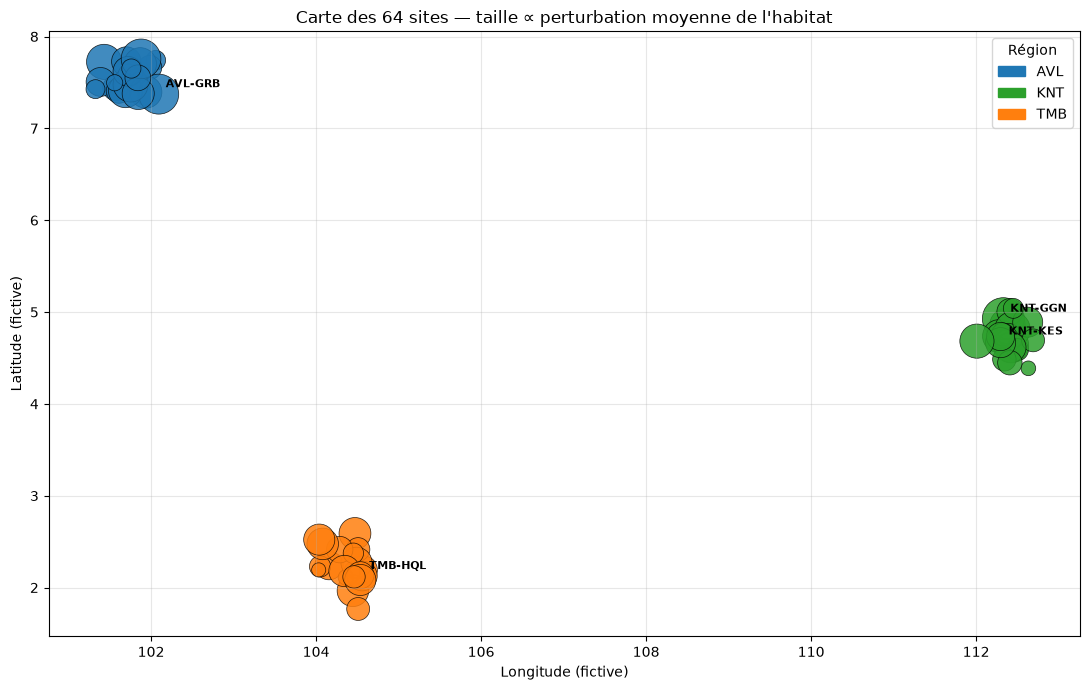

Lecture : 3 clusters géographiques (AVL / KNT / TMB). Points plus gros = plus perturbés.
KNT-KES annoté pour le suivi enquête.


In [70]:
# --- A.2 Carte scatter ---
region_color = {"AVL": "#1f77b4", "KNT": "#2ca02c", "TMB": "#ff7f0e"}
colors = profil["region_code"].map(region_color)
sizes = 40 + 12 * profil["habitat_disturbance_index"]  # taille ∝ perturbation

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(profil["longitude"], profil["latitude"], c=colors, s=sizes,
           alpha=0.85, edgecolors="black", linewidths=0.5)
for _, r in profil[profil["site_code"].isin(
    ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"]
)].iterrows():
    ax.annotate(r["site_code"], (r["longitude"], r["latitude"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8, fontweight="bold")

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=r) for r, c in region_color.items()],
          title="Région", loc="best")
ax.set_xlabel("Longitude (fictive)")
ax.set_ylabel("Latitude (fictive)")
ax.set_title("Carte des 64 sites — taille ∝ perturbation moyenne de l'habitat")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Lecture : 3 clusters géographiques (AVL / KNT / TMB). Points plus gros = plus perturbés.")
print("KNT-KES annoté pour le suivi enquête.")


### A.3 Autocorrélation spatiale : Moran global, LISA, Voronoi

Avec **64 points**, ces outils du cours sont applicables (contrairement à un jeu à 3 GPS seulement).

- **Moran I** : les sites proches ont-ils des valeurs similaires ? (I > 0 → regroupement spatial)
- **LISA** : quels sites sont des clusters locaux (High-High, Low-Low) ou des outliers spatiaux (High-Low…)
- **Voronoi** : tessellation de l'espace autour de chaque site


In [71]:
# --- A.3 Moran + LISA ---
%pip install libpysal esda -q
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local

var = "habitat_disturbance_index"
coords = profil[["longitude", "latitude"]].values

# Global (attention : 3 régions géographiquement disjointes → graphe KNN souvent non connexe)
w = KNN.from_array(coords, k=4)
w.transform = "R"
y = profil[var].values
mi = Moran(y, w)
print(f"=== Moran I GLOBAL sur `{var}` ===")
print(f"I = {mi.I:.3f}  |  E[I] = {mi.EI:.3f}  |  p-value = {mi.p_sim:.4f}")
print("Note : les 3 régions sont loin les unes des autres (géo fictive) →")
print("       le Moran GLOBAL est peu informatif. On calcule aussi Moran PAR RÉGION.")

print(f"\n=== Moran I PAR RÉGION (k=3 voisins) ===")
for reg in ["AVL", "KNT", "TMB"]:
    sub = profil[profil["region_code"] == reg]
    if len(sub) < 5:
        print(f"  {reg}: trop peu de sites")
        continue
    w_r = KNN.from_array(sub[["longitude", "latitude"]].values, k=min(3, len(sub) - 1))
    w_r.transform = "R"
    mi_r = Moran(sub[var].values, w_r)
    print(f"  {reg}: I = {mi_r.I:.3f}  p = {mi_r.p_sim:.4f}  (n={len(sub)})")

# LISA global (interprétation locale toujours utile)
lisa = Moran_Local(y, w)
labels_q = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
profil = profil.copy()
profil["lisa_q"] = lisa.q
profil["lisa_p"] = lisa.p_sim
profil["lisa_sig"] = profil["lisa_p"] < 0.05

print("\n=== LISA (p < 0.05) ===")
sig = profil[profil["lisa_sig"]]
if len(sig):
    print(sig.groupby("lisa_q").size().rename(index=labels_q).to_string())
    display(sig[["site_code", "region_code", var, "lisa_q", "lisa_p"]]
            .assign(quadrant=lambda d: d["lisa_q"].map(labels_q))
            .sort_values("lisa_p")
            .head(15))
else:
    print("Aucun site LISA significatif au seuil 0.05 (structure locale faible / régions séparées).")

for site in ["KNT-KES", "KNT-GGN", "AVL-GRB", "TMB-HQL"]:
    row = profil[profil["site_code"] == site].iloc[0]
    print(f"{site}: {var}={row[var]:.1f}  Q={labels_q[row['lisa_q']]}  p={row['lisa_p']:.3f}  sig={row['lisa_sig']}")



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
=== Moran I GLOBAL sur `habitat_disturbance_index` ===
I = -0.072  |  E[I] = -0.016  |  p-value = 0.2560
Note : les 3 régions sont loin les unes des autres (géo fictive) →
       le Moran GLOBAL est peu informatif. On calcule aussi Moran PAR RÉGION.

=== Moran I PAR RÉGION (k=3 voisins) ===
  AVL: I = -0.096  p = 0.4140  (n=22)
  KNT: I = -0.039  p = 0.4600  (n=22)
  TMB: I = -0.165  p = 0.2500  (n=20)

=== LISA (p < 0.05) ===
lisa_q
Low-High    1


c:\Users\djidj\AppData\Local\Programs\Python\Python312\Lib\site-packages\libpysal\weights\distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
c:\Users\djidj\AppData\Local\Programs\Python\Python312\Lib\site-packages\esda\moran.py:1374: DeprecationWarning: The alternative hypothesis for conditional randomization is changing in the next major release of esda. We recommend setting alternative='two-sided', which will generally double the p-value returned. To retain the current behavior, set alternative='directed'. We strongly recommend moving to alternative='two-sided'.
  self.p_sim, self.rlisas = _crand_plus(


,site_code,region_code,habitat_disturbance_index,lisa_q,lisa_p,quadrant
41,KNT-XAC,KNT,13.758974,2,0.006,Low-High


KNT-KES: habitat_disturbance_index=20.3  Q=Low-High  p=0.224  sig=False
KNT-GGN: habitat_disturbance_index=72.8  Q=High-High  p=0.143  sig=False
AVL-GRB: habitat_disturbance_index=65.6  Q=High-Low  p=0.488  sig=False
TMB-HQL: habitat_disturbance_index=35.1  Q=High-Low  p=0.483  sig=False


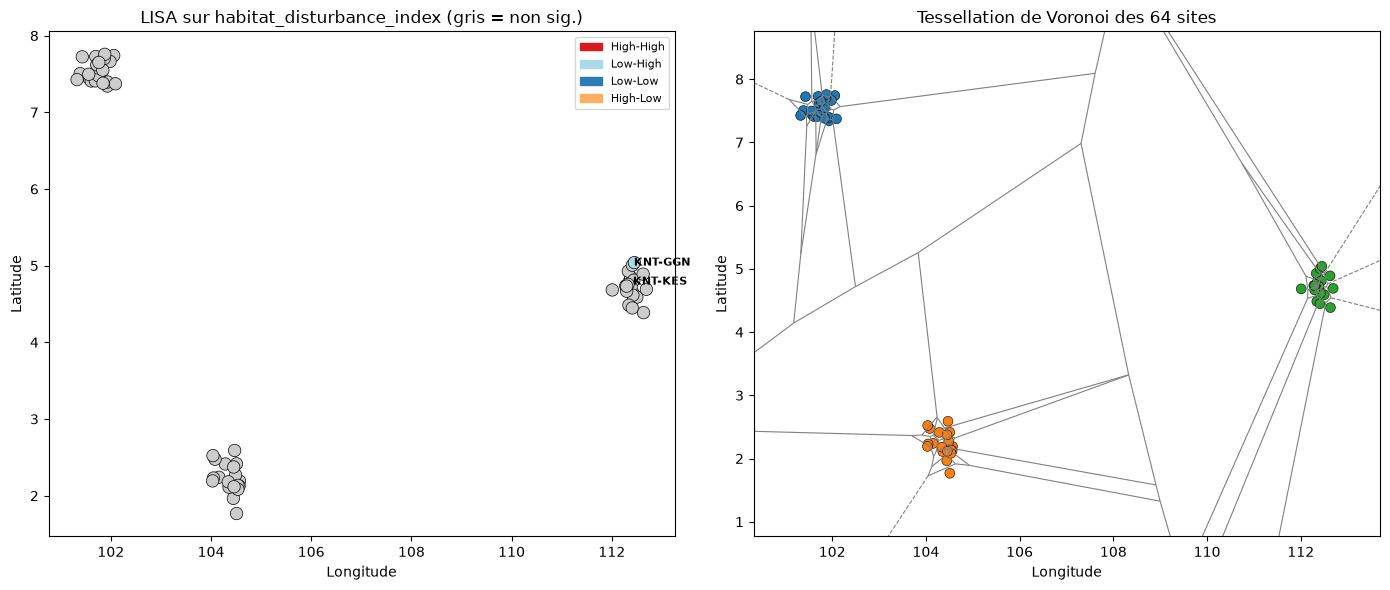

Voronoi : chaque cellule = zone plus proche d'un site que des autres (partition spatiale du réseau).
Regionalisation : les 3 régions AVL/KNT/TMB forment déjà une régionalisation naturelle (clusters géo disjoints).


In [72]:
# Carte LISA + Voronoi
from scipy.spatial import Voronoi, voronoi_plot_2d

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# LISA
q_colors = {1: "#d7191c", 2: "#abd9e9", 3: "#2c7bb6", 4: "#fdae61"}
c_lisa = [q_colors[q] if sig else "#cccccc"
          for q, sig in zip(profil["lisa_q"], profil["lisa_sig"])]
axes[0].scatter(profil["longitude"], profil["latitude"], c=c_lisa, s=80,
                edgecolors="black", linewidths=0.5)
for _, r in profil[profil["site_code"].isin(["KNT-KES", "KNT-GGN"])].iterrows():
    axes[0].annotate(r["site_code"], (r["longitude"], r["latitude"]),
                     textcoords="offset points", xytext=(4, 4), fontsize=8, fontweight="bold")
axes[0].set_title(f"LISA sur {var} (gris = non sig.)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
axes[0].legend(handles=[Patch(color=c, label=labels_q[q]) for q, c in q_colors.items()],
               fontsize=8, loc="best")

# Voronoi (par région séparément pour éviter le mélange intercontinental fictif)
# Global sur tous les points (structure relative OK même si géographie fictive)
vor = Voronoi(coords)
voronoi_plot_2d(vor, ax=axes[1], show_vertices=False, line_colors="grey",
                line_width=0.8, point_size=0)
axes[1].scatter(profil["longitude"], profil["latitude"],
                c=profil["region_code"].map(region_color), s=50, edgecolors="black", linewidths=0.4)
axes[1].set_title("Tessellation de Voronoi des 64 sites")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
# Limiter la vue aux points
axes[1].set_xlim(profil["longitude"].min() - 1, profil["longitude"].max() + 1)
axes[1].set_ylim(profil["latitude"].min() - 1, profil["latitude"].max() + 1)

plt.tight_layout()
plt.show()

print("Voronoi : chaque cellule = zone plus proche d'un site que des autres (partition spatiale du réseau).")
print("Regionalisation : les 3 régions AVL/KNT/TMB forment déjà une régionalisation naturelle (clusters géo disjoints).")


### - Lecture spatial

- **64 coordonnées** → Moran / LISA / Voronoi **pertinents** (on ne met PAS « non pertinent »).
- Moran **global** souvent peu significatif car AVL / KNT / TMB sont des blocs géographiques **séparés** (géo fictive) → regarder Moran **par région**.
- LISA : clusters locaux éventuels ; `KNT-KES` typiquement **non significatif** (profil ordinaire).
- Voronoi + 3 régions = régionalisation naturelle déjà visible sur la carte.
- Géographie **fictive** : structure relative seulement, pas un vrai pays.


## B. Temporel

### B.1 Construire les séries

Contrairement aux dossiers « courts et sparses » du cours (30–135 lignes / décennies), ici on a **~78 mois** (2019-01 → 2025-06) × 64 sites → séries **assez denses** pour chercher une saisonnalité.


Série globale : 78 mois  | 2019-01-01 → 2025-06-01
Série KNT-KES : 78 mois


,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index
reporting_month,,,,,,
2019-01-01,26.1,145.6,75.1,60.5,30.3,23.6
2019-02-01,26.9,128.5,73.1,59.4,31.5,26.2
2019-03-01,27.4,121.7,72.2,58.9,30.9,25.6


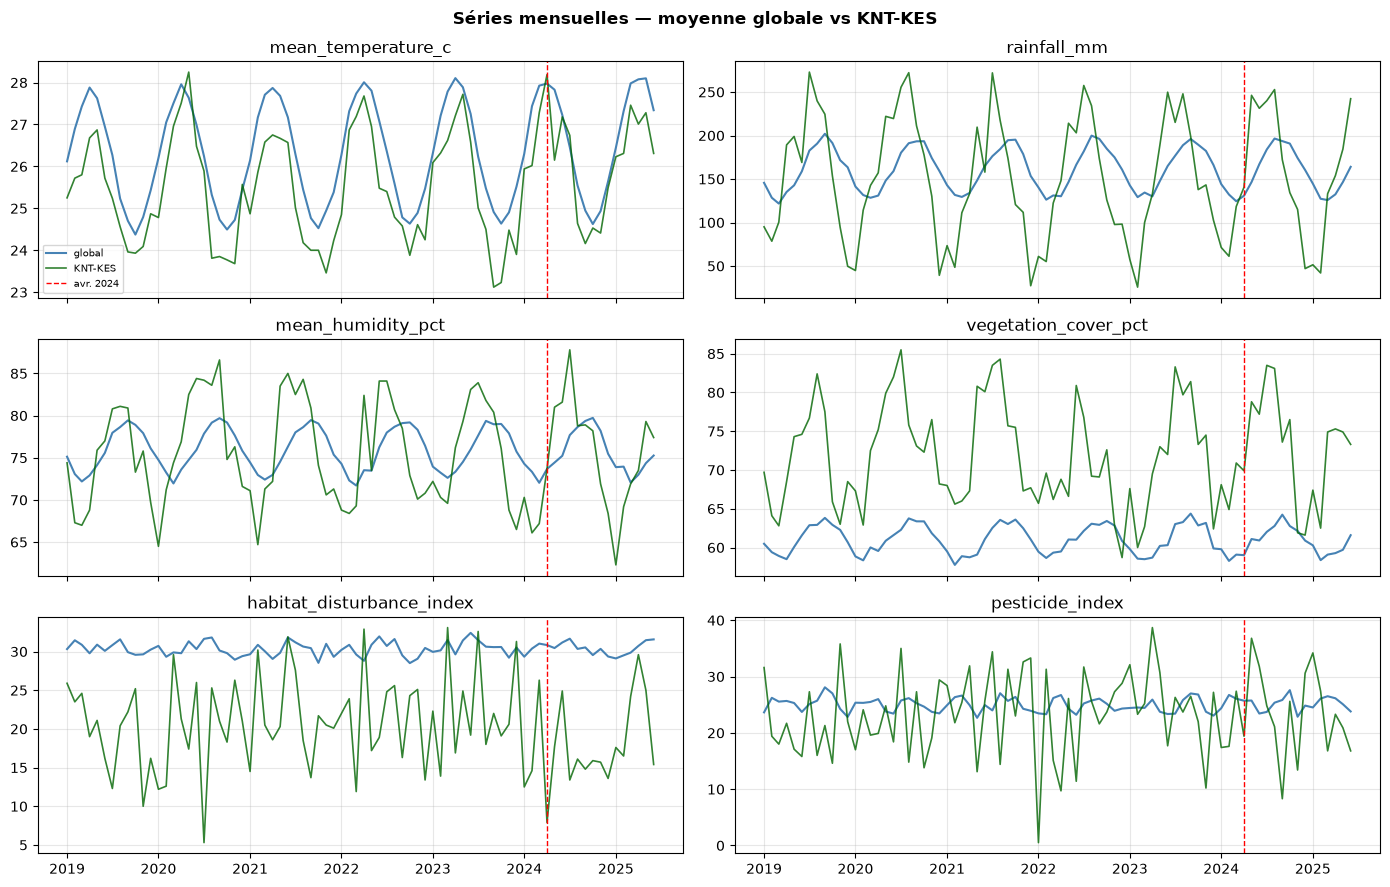

In [73]:
# --- B.1 Séries temporelles ---
# Série GLOBALE : moyenne mensuelle sur tous les sites
series_global = df_env.groupby("reporting_month")[cols_num].mean().sort_index()

# Série KNT-KES (site enquête)
series_kes = (df_env[df_env["site_code"] == "KNT-KES"]
              .set_index("reporting_month")[cols_num].sort_index())

print("Série globale :", series_global.shape[0], "mois  |",
      series_global.index.min().date(), "→", series_global.index.max().date())
print("Série KNT-KES :", series_kes.shape[0], "mois")
display(series_global.head(3).round(1))

# Visualisation multi-variables (global)
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for ax, col in zip(axes.ravel(), cols_num):
    ax.plot(series_global.index, series_global[col], color="steelblue", lw=1.5, label="global")
    if col in series_kes:
        ax.plot(series_kes.index, series_kes[col], color="darkgreen", lw=1.2, alpha=0.8, label="KNT-KES")
    ax.axvline(pd.Timestamp("2024-04-01"), color="red", ls="--", lw=1, label="avr. 2024")
    ax.set_title(col)
    ax.grid(True, alpha=0.3)
axes[0, 0].legend(fontsize=7, loc="best")
fig.suptitle("Séries mensuelles — moyenne globale vs KNT-KES", fontweight="bold")
plt.tight_layout()
plt.show()


### B.2 Composantes : tendance, saisonnalité, cycle, bruit

On décompose une série représentative (`rainfall_mm` globale) avec **STL** (`statsmodels`), puis on regarde l'**ACF**.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


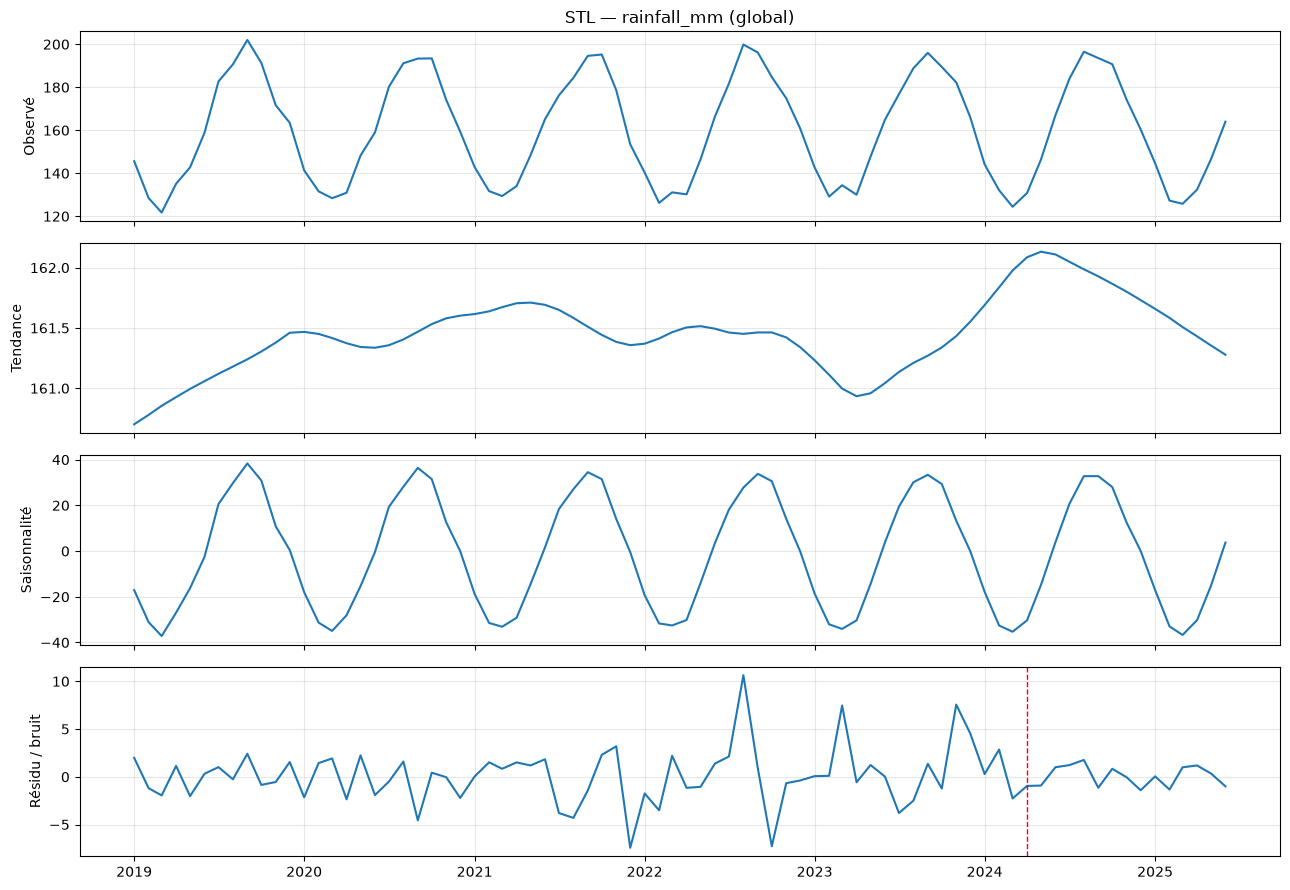

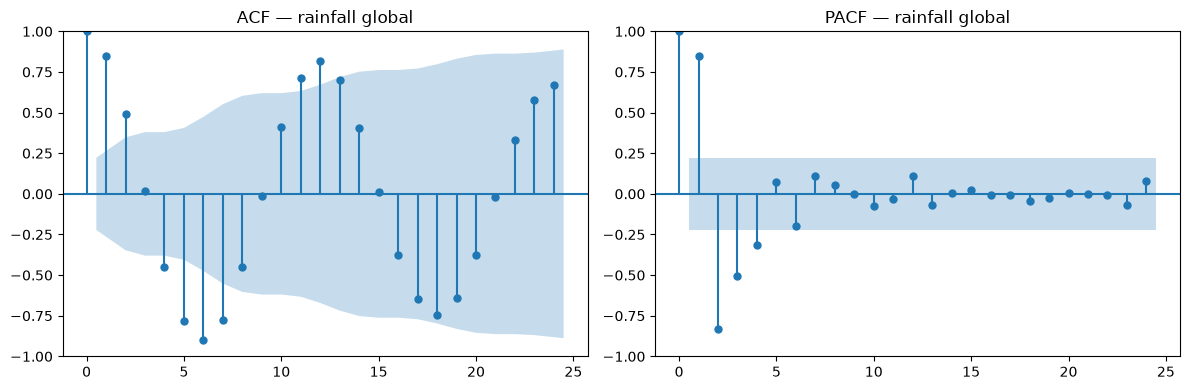

=== Lecture composantes ===
- Tendance : évolution lente multi-années (réchauffement / dérive éventuelle).
- Saisonnalité : cycle ~12 mois attendu (mousson) — pics ACF aux lags 12 / 24 si présent.
- Bruit : résidu STL ; pics isolés = mois atypiques.
- Cycle (au-delà saisonnier) : peu probable sur 6 ans — à ne pas sur-interpréter.


In [74]:
# --- B.2 STL + ACF ---
%pip install statsmodels -q
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

y = series_global["rainfall_mm"].asfreq("MS")  # mois début
stl = STL(y, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axes[0].plot(stl.observed); axes[0].set_ylabel("Observé"); axes[0].set_title("STL — rainfall_mm (global)")
axes[1].plot(stl.trend); axes[1].set_ylabel("Tendance")
axes[2].plot(stl.seasonal); axes[2].set_ylabel("Saisonnalité")
axes[3].plot(stl.resid); axes[3].set_ylabel("Résidu / bruit")
axes[3].axvline(pd.Timestamp("2024-04-01"), color="red", ls="--", lw=1)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(y.dropna(), lags=24, ax=axes[0], title="ACF — rainfall global")
plot_pacf(y.dropna(), lags=24, ax=axes[1], title="PACF — rainfall global", method="ywm")
plt.tight_layout()
plt.show()

print("=== Lecture composantes ===")
print("- Tendance : évolution lente multi-années (réchauffement / dérive éventuelle).")
print("- Saisonnalité : cycle ~12 mois attendu (mousson) — pics ACF aux lags 12 / 24 si présent.")
print("- Bruit : résidu STL ; pics isolés = mois atypiques.")
print("- Cycle (au-delà saisonnier) : peu probable sur 6 ans — à ne pas sur-interpréter.")


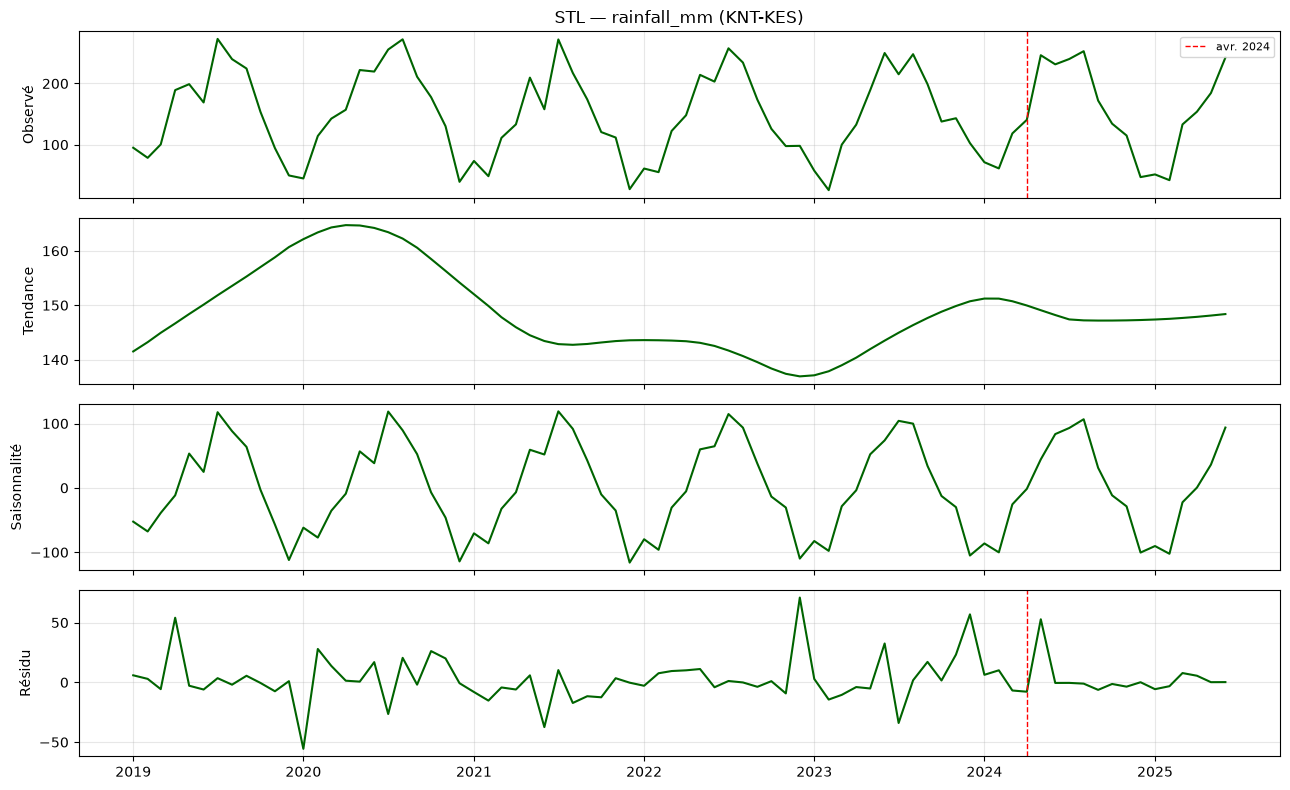

Résidu STL KNT-KES en avril 2024 (pluie) : -7.81
Si |résidu| faible → mois climativement ordinaire (cohérent Bloc 3).


In [75]:
# STL aussi sur KNT-KES (pluie) pour le site enquête
y_kes = series_kes["rainfall_mm"].asfreq("MS")
stl_kes = STL(y_kes, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
axes[0].plot(stl_kes.observed, color="darkgreen"); axes[0].set_ylabel("Observé")
axes[0].set_title("STL — rainfall_mm (KNT-KES)")
axes[0].axvline(pd.Timestamp("2024-04-01"), color="red", ls="--", lw=1, label="avr. 2024")
axes[0].legend(fontsize=8)
axes[1].plot(stl_kes.trend, color="darkgreen"); axes[1].set_ylabel("Tendance")
axes[2].plot(stl_kes.seasonal, color="darkgreen"); axes[2].set_ylabel("Saisonnalité")
axes[3].plot(stl_kes.resid, color="darkgreen"); axes[3].set_ylabel("Résidu")
axes[3].axvline(pd.Timestamp("2024-04-01"), color="red", ls="--", lw=1)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Avril 2024 dans le résidu ?
if pd.Timestamp("2024-04-01") in stl_kes.resid.index:
    r = stl_kes.resid.loc[pd.Timestamp("2024-04-01")]
    print(f"Résidu STL KNT-KES en avril 2024 (pluie) : {r:.2f}")
    print("Si |résidu| faible → mois climativement ordinaire (cohérent Bloc 3).")


### B.3 Anomalies temporelles (fenêtre glissante, méthodes type Cours 3)

Sur chaque série : z-score dans une **fenêtre glissante** (ex. 12 mois). Un mois est atypique si $|z_{fenêtre}| > 3$.


Global — rainfall: 0 mois flaggés
KNT-KES — rainfall: 0 mois flaggés


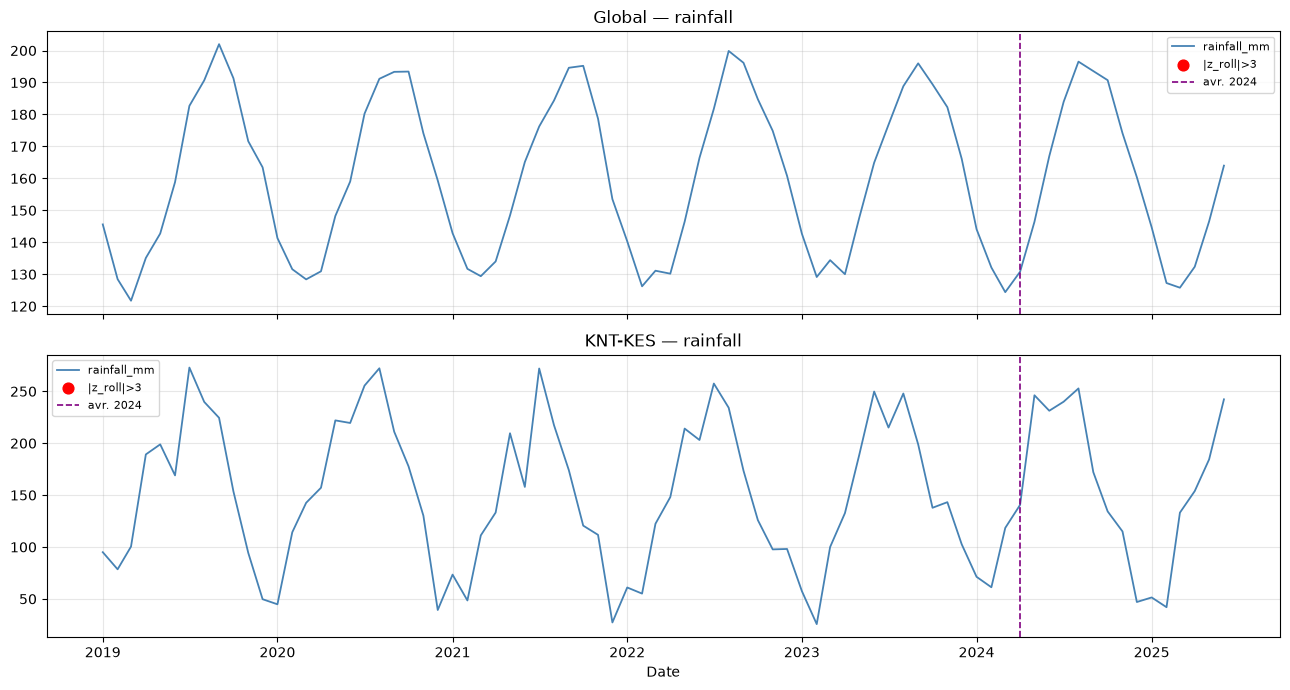


=== KNT-KES avril 2024 — z glissant par variable ===
  mean_temperature_c            z=  1.63  anomalie=False
  rainfall_mm                   z= -0.28  anomalie=False
  mean_humidity_pct             z= -0.15  anomalie=False
  vegetation_cover_pct          z= -0.52  anomalie=False
  habitat_disturbance_index     z= -1.57  anomalie=False
  pesticide_index               z= -0.31  anomalie=False


In [76]:
# --- B.3 Anomalies fenêtre glissante ---
def rolling_z_anomalies(s, window=12, thresh=3.0):
    mu = s.rolling(window, center=True, min_periods=max(6, window // 2)).mean()
    sd = s.rolling(window, center=True, min_periods=max(6, window // 2)).std()
    z = (s - mu) / sd
    return z, (z.abs() > thresh)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, (name, s, col) in zip(axes, [
    ("Global — rainfall", series_global["rainfall_mm"], "rainfall_mm"),
    ("KNT-KES — rainfall", series_kes["rainfall_mm"], "rainfall_mm"),
]):
    z, mask = rolling_z_anomalies(s)
    ax.plot(s.index, s.values, color="steelblue", lw=1.3, label=col)
    ax.scatter(s.index[mask.fillna(False)], s.values[mask.fillna(False)],
               color="red", s=60, zorder=5, label="|z_roll|>3")
    ax.axvline(pd.Timestamp("2024-04-01"), color="purple", ls="--", lw=1.2, label="avr. 2024")
    ax.set_title(name)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    print(f"{name}: {int(mask.sum())} mois flaggés")
    if mask.any():
        print("  →", list(s.index[mask].strftime("%Y-%m")))

plt.xlabel("Date")
plt.tight_layout()
plt.show()

# Multi-variables KNT-KES : combien de variables flaggées en avril 2024 ?
print("\n=== KNT-KES avril 2024 — z glissant par variable ===")
avril = pd.Timestamp("2024-04-01")
for col in cols_num:
    z, mask = rolling_z_anomalies(series_kes[col])
    zv = z.loc[avril] if avril in z.index else np.nan
    print(f"  {col:28s}  z={zv:6.2f}  anomalie={bool(mask.loc[avril]) if avril in mask.index else 'NA'}")


### B.4 Clustering de séries / Dynamic Time Warping

Le cours : ces méthodes supposent **plusieurs séries alignées**. Ici on a **64 séries mensuelles alignées** (même calendrier) → on peut faire un clustering simple par corrélation des profils de pluie (sans DTW lourd).

> DTW complet sur 64×78 : possible mais coûteux / peu nécessaire ; on justifie un proxy par corrélation / distance euclidienne sur séries standardisées.


In [77]:
# --- B.4 Clustering des séries de pluie par site (proxy, pas DTW) ---
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Matrice sites × mois (rainfall)
pivot = (df_env.pivot_table(index="site_code", columns="reporting_month",
                            values="rainfall_mm", aggfunc="mean")
         .sort_index(axis=1))
# Sites complets seulement
pivot = pivot.dropna(axis=0)
print("Matrice séries pluie :", pivot.shape, "(sites × mois)")

X_ts = StandardScaler().fit_transform(pivot.values)
# k=3 (hypothèse régions)
km_ts = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_ts)
ts_labels = pd.Series(km_ts.labels_, index=pivot.index, name="cluster_ts")

cmp = pd.DataFrame({
    "cluster_ts": ts_labels,
    "region_code": ts_labels.index.str[:3],
})
print("\nClusters de séries × région :")
display(pd.crosstab(cmp["cluster_ts"], cmp["region_code"]))

print("\nJustification DTW : non appliqué ici — séries déjà alignées mensuellement ;")
print("K-Means sur profils standardisés suffit pour voir si les séries collent aux régions.")
print("KNT-KES cluster_ts =", int(ts_labels.loc["KNT-KES"]) if "KNT-KES" in ts_labels else "NA")


Matrice séries pluie : (64, 78) (sites × mois)

Clusters de séries × région :


region_code,AVL,KNT,TMB
cluster_ts,,,
0,0,22,0
1,0,0,20
2,22,0,0



Justification DTW : non appliqué ici — séries déjà alignées mensuellement ;
K-Means sur profils standardisés suffit pour voir si les séries collent aux régions.
KNT-KES cluster_ts = 0


### - Bilan Bloc 5

| Volet | Résultat |
|---|---|
| **Spatial** | 64 sites géolocalisés (via `monitoring_sites`) ; carte ; Moran / LISA / Voronoi **pertinents** |
| **Temporel** | Séries mensuelles denses (78 mois) ; STL + ACF ; anomalies fenêtre glissante |
| **Avril 2024 / KNT-KES** | Résidu STL + z glissant : **pas** d'anomalie climatique forte |
| **DTW** | Non appliqué (séries alignées → clustering corrélation / K-Means comme proxy) |
| **Géographie** | Fictive — structure relative seulement |

Bloc 5 complète le diagnostic : si Moran montre une structure spatiale de la perturbation ailleurs, et si KNT-KES n'est pas atypique en temporel → l'effondrement bats reste **hors cause environnementale**.


# 16. Bloc 6 : données textuelles (Cours 6)

Le cours 6 porte sur des **corpus textuels** (mémos, documents d'enquête, rapports narratifs).

`environmental_monthly` contient uniquement des **mesures climatiques / habitat** + catégories courtes (`land_use_category`, `weather_exception_code`).  
Il n'y a **pas** de champ libre (`text`, `title`, `memo`…).

| Étape cours 6 | Sur ce fichier |
|---|---|
| UTF-8 / langue / stopwords | Non pertinent (pas de prose) |
| Dédup de paragraphes | Non pertinent |
| Tokenize / PoS / lemmatisation | Non pertinent |
| Word cloud / n-grams / TF-IDF / LDA | Non pertinent |
| Embeddings textuels | Non pertinent |

> **Décision pour ce notebook :** Bloc 6 **non applicable** — on le documente ici pour le rapport, sans forcer une analyse NLP sur des colonnes numériques.


In [78]:
# Contrôle : aucune colonne narrative dans environmental_monthly
cols = pd.read_csv("cleaned/environmental_monthly_clean.csv", nrows=0).columns.tolist()
text_like = [c for c in cols if c.lower() in
             {"text", "title", "body", "memo", "content", "description", "summary", "notes"}]
print("Colonnes du fichier :", cols)
print("Colonnes narratives trouvées :", text_like if text_like else "(aucune)")
print("Verdict : PAS un corpus textuel → Bloc 6 non appliqué sur environmental_monthly.")


Colonnes du fichier : ['site_code', 'reporting_month', 'mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index', 'land_use_category', 'weather_exception_code', 'data_completeness_pct', 'year', 'month']
Colonnes narratives trouvées : (aucune)
Verdict : PAS un corpus textuel → Bloc 6 non appliqué sur environmental_monthly.


## SYNTHÈSE FINALE — ENVIRONMENTAL_MONTHLY


In [79]:
print("\n" + "=" * 80)
print("SYNTHÈSE — ENVIRONMENTAL_MONTHLY (contrôle climatique / habitat)")
print("=" * 80 + "\n")

_df = df_env if "df_env" in globals() else pd.read_csv("cleaned/environmental_monthly_clean.csv")
_df["reporting_month"] = pd.to_datetime(_df["reporting_month"])

summary = {
    "Couverture temporelle": f"{_df['reporting_month'].min().date()} → {_df['reporting_month'].max().date()}",
    "Relevés (nettoyés)": f"{len(_df):,}".replace(",", " "),
    "Sites / régions": f"{_df['site_code'].nunique()} sites | 3 régions (AVL, KNT, TMB)",
    "Rôle du fichier": "Contrôle : écarter une cause environnementale du crash bats",
    "Clustering (Bloc 2)": "k=3 — secs/chauds | humides | sites perturbés (~19%)",
    "Anomalies (Bloc 3)": "IF → profils perturbés (KNT-GGN, AVL-GRB) ; LOF → cas locaux (ex. TMB-HQL)",
    "Graphe (Bloc 4)": "Similarité sites n=64 m=136 ; KNT-KES ordinaire ; ≠ communauté de KNT-GGN",
    "Spatial (Bloc 5)": "64 GPS via monitoring_sites ; Moran peu significatif (régions séparées)",
    "Temporel (Bloc 5)": "STL + z glissant : KNT-KES avril 2024 = mois ORDINAIRE",
    "Texte (Bloc 6)": "Non applicable (pas de corpus textuel)",
    "Process mining": "Non applicable (pas d'event log)",
    "Site critique suivi": "KNT-KES (avril 2024) — climat innocenté",
    "Verdict": "Cause environnementale ÉCARTÉE → cohérent avec bat_surveys ↔ EFR-510088",
}

for key, value in summary.items():
    print(f"  {key:.<42} {value}")

print("\n Bloc complet : contrôle climatique OK — braconnage KNT-KES non contredit par l'environnement.")



SYNTHÈSE — ENVIRONMENTAL_MONTHLY (contrôle climatique / habitat)

  Couverture temporelle..................... 2019-01-01 → 2025-06-01
  Relevés (nettoyés)........................ 4 992
  Sites / régions........................... 64 sites | 3 régions (AVL, KNT, TMB)
  Rôle du fichier........................... Contrôle : écarter une cause environnementale du crash bats
  Clustering (Bloc 2)....................... k=3 — secs/chauds | humides | sites perturbés (~19%)
  Anomalies (Bloc 3)........................ IF → profils perturbés (KNT-GGN, AVL-GRB) ; LOF → cas locaux (ex. TMB-HQL)
  Graphe (Bloc 4)........................... Similarité sites n=64 m=136 ; KNT-KES ordinaire ; ≠ communauté de KNT-GGN
  Spatial (Bloc 5).......................... 64 GPS via monitoring_sites ; Moran peu significatif (régions séparées)
  Temporel (Bloc 5)......................... STL + z glissant : KNT-KES avril 2024 = mois ORDINAIRE
  Texte (Bloc 6)............................ Non applicable (pas de corp

# TABLEAU RÉCAPITULATIF : CONTRÔLE KNT-KES (avril 2024)


In [80]:
print("=" * 100)
print("TABLEAU RÉCAPITULATIF : CONTRÔLE ENVIRONNEMENTAL — KNT-KES / AVRIL 2024")
print("=" * 100 + "\n")

_df = df_env if "df_env" in globals() else pd.read_csv("cleaned/environmental_monthly_clean.csv")
_df["reporting_month"] = pd.to_datetime(_df["reporting_month"])
if "region_code" not in _df.columns:
    _df["region_code"] = _df["site_code"].str[:3]

avril = pd.Timestamp("2024-04-01")
row = _df[(_df["site_code"] == "KNT-KES") & (_df["reporting_month"] == avril)]
hist = _df[(_df["site_code"] == "KNT-KES") & (_df["reporting_month"] != avril)]

cols = ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct",
        "vegetation_cover_pct", "habitat_disturbance_index", "pesticide_index"]

recap_rows = []
if len(row) == 1:
    r = row.iloc[0]
    for c in cols:
        mu, sd = hist[c].mean(), hist[c].std()
        z = (r[c] - mu) / sd if sd and sd > 0 else float("nan")
        recap_rows.append({
            "Variable": c,
            "Valeur avril 2024": round(float(r[c]), 2),
            "Moyenne historique site": round(float(mu), 2),
            "Z-score site": round(float(z), 2),
            "Lecture": "ordinaire" if abs(z) < 2 else ("élevé" if z > 0 else "bas"),
        })
    recap_df = pd.DataFrame(recap_rows)
    display(recap_df)

    print("\n MÉTADONNÉES AVRIL 2024 :")
    print(f"   weather_exception_code : {r.get('weather_exception_code', 'NA')}")
    print(f"   land_use_category      : {r.get('land_use_category', 'NA')}")
    print(f"   data_completeness_pct  : {r.get('data_completeness_pct', 'NA')}")
else:
    print("Ligne KNT-KES / 2024-04 introuvable dans le jeu nettoyé.")
    recap_df = pd.DataFrame()

print("\n VERDICT :")
print("   KNT-KES avril 2024 = environnement NORMAL (code météo NORMAL, |z| faibles)")
print("   → n'explique PAS la chute BAT-0000064")
print("   → cause ailleurs : EFR-510088 (filets coupés / intrusion)")


TABLEAU RÉCAPITULATIF : CONTRÔLE ENVIRONNEMENTAL — KNT-KES / AVRIL 2024



,Variable,Valeur avril 2024,Moyenne historique site,Z-score site,Lecture
0,mean_temperature_c,28.19,25.53,2.06,élevé
1,rainfall_mm,140.60,150.60,-0.14,ordinaire
2,mean_humidity_pct,73.70,75.46,-0.28,ordinaire
3,vegetation_cover_pct,69.90,71.89,-0.29,ordinaire
4,habitat_disturbance_index,7.90,20.45,-2.13,bas
5,pesticide_index,19.40,23.24,-0.51,ordinaire



 MÉTADONNÉES AVRIL 2024 :
   weather_exception_code : NORMAL
   land_use_category      : karst_habitat
   data_completeness_pct  : 92.1

 VERDICT :
   KNT-KES avril 2024 = environnement NORMAL (code météo NORMAL, |z| faibles)
   → n'explique PAS la chute BAT-0000064
   → cause ailleurs : EFR-510088 (filets coupés / intrusion)


BAT-0000064 (bat_surveys)

    ↓ ANOMALIE NUMÉRIQUE

    Chute de -65% du nombre de chauve-souris en période de reproduction
    (contexte: site KNT-KES, avril 2024)
    
         ↕ LIEN DIRECT / MÊME SITE / MÊME PÉRIODE
         
EFR-510088 (environmental_field_reports)

    ↓ ANOMALIE TEXTUELLE/MATÉRIELLE
    
    EVIDENCE: filets coupés + traces d'intrusion
    (même site KNT-KES, même date avril 2024)
    
    CAUSALITÉ: Filets coupés → Enlèvement/Braconnage → Perte d'individus

         ↕ CONTRÔLE NÉGATIF (ce fichier)

environmental_monthly (KNT-KES, avril 2024)

    ↓ CONTRÔLE CLIMAT / HABITAT

    Code météo NORMAL
    Pas d'anomalie IF / LOF
    Z-scores & fenêtre glissante : mois ORDINAIRE
    Graphe : nœud banal (≠ profil perturbé type KNT-GGN)

    VERDICT : cause environnementale ÉCARTÉE
              → renforce le lien bat ↔ field reports
                 (braconnage, pas la météo)


# Synthèse des résultats

## 1. De quoi parle ce fichier ?

Ce fichier décrit le **climat et l'habitat** chaque mois, sur chaque site :
- température, pluie, humidité
- végétation, perturbation de l'habitat, pesticides
- type d'usage du sol, code météo

Une ligne = **un site × un mois**.

---

## 2. Résultat principal (sur tout le fichier)

On voit surtout des **profils environnementaux** :

### Profil A — Mois plutôt secs / chauds
Peu de pluie, plus chaud, humidité plus basse.

### Profil B — Mois humides / végétalisés
Beaucoup de pluie, humidité haute, végétation plus dense.

### Profil C — Sites perturbés (~19 %)
Habitat plus dégradé, plus de pesticides, moins de végétation  
(souvent agriculture / terres dégradées ; ex. `KNT-GGN`, `AVL-GRB`).

Donc ce fichier raconte surtout : **comment est l'environnement**, pas une "affaire secrète" à lui seul.

---

## 3. Le point important pour l'enquête chauves-souris

L'enquête part de ça :

> À **KNT-KES**, en **avril 2024**, la colonie chute d'environ **−65 %**  
> (relevé `BAT-0000064` : 27,9 en avril 2023 → 9,5 en avril 2024)

Question : et si c'était juste la **météo** / un habitat devenu horrible ce mois-là ?

### Réponse de ce fichier (KNT-KES, avril 2024)
- code météo = **NORMAL**
- pas d'anomalie forte (IF / LOF / z glissant)
- dans le réseau de similarité : site **ordinaire**, pas un outlier climatique
- pas le même "profil" que les sites très perturbés (ex. `KNT-GGN`)

**Conclusion :** l'environnement était **normal**.  
Ce n'est **pas** la météo / l'habitat qui explique la chute des chauves-souris.

---

## 4. Verdict final (en une phrase)

Ce fichier sert de **contrôle climatique** :  
il écarte la piste "mauvais temps / habitat détruit" et renforce l'idée que la cause est ailleurs  
(→ rapport terrain `EFR-510088` : filets coupés / intrusion / braconnage).
